In [1]:
%load_ext autoreload

%autoreload 2

# custom imports

from ete3 import Tree
from ete3.treeview import faces, AttrFace, TextFace, TreeStyle, NodeStyle, CircleFace, RectFace

import ete3 as ete3
ete3.__version__

import os

os.environ['QT_QPA_PLATFORM']='offscreen'

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import glob

In [3]:
import matplotlib as mpl

In [4]:
import subprocess
import os
import glob
import pickle

In [5]:
import itertools
from itertools import tee

In [6]:
from IPython.display import display, clear_output
from tqdm import tqdm

In [7]:
from scipy.stats import spearmanr
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [8]:
from Bio import SeqIO

In [9]:
ete3.__version__

'3.1.3'

In [10]:
import sys
sys.path.append('/data/mhoffert/fiererlab/adenylate_kinase_ogt/')

In [11]:
from src.models.nn_models import MLPRegressor, AttentionRegressor
from src.models.utils import unscale_ogts, scale_ogts, reload_model

# Load helping data

In [12]:
# load temperature data
temp_data = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/metric_tables/20240327_metrics_df_full.tsv.gz', sep='\t', index_col=0)
temp_data.head()

,Position,Contacts at 4.5 Å,SASA,uid,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,bbsc_internal_hbonds,...,temp,mean_temp,seq_length,bitscore,C,L,N,P,max_structure_length,lid_bitscore
0,94.0,11.358289,52.616491,GB_GCA_000376885.1,-454.076,1.278,10.765,2.648,124.0,21.0,...,37.0,37.0,187,178.2,90.0,48.0,42.0,6.0,24,0.0
1,108.0,11.125581,49.464040,GB_GCA_000016765.1,-450.126,1.316,10.730,2.697,132.0,30.0,...,30.0,30.0,215,175.3,116.0,49.0,43.0,6.0,23,52.3
2,119.5,11.289720,49.538232,GB_GCA_000242235.1,-419.604,1.327,10.981,2.842,128.0,22.0,...,37.0,37.0,214,192.2,117.0,48.0,42.0,6.0,24,59.2
3,105.5,11.276190,50.018080,GB_GCA_000283575.1,-452.738,1.390,10.905,2.771,129.0,20.0,...,30.0,30.0,210,168.7,112.0,48.0,43.0,6.0,24,58.3
4,91.0,11.359116,51.483049,GB_GCA_001054945.1,-431.800,1.243,10.768,2.669,117.0,20.0,...,37.0,37.0,181,192.9,88.0,44.0,42.0,6.0,21,0.0


In [13]:
genome2temp = temp_data.set_index('uid')['temp']

## Load tree

In [14]:
gtdb_full = Tree('/data/mhoffert/genomes/GTDB_r214.1/bac120_r214.tree', format=1, quoted_node_names=True)

In [15]:
gtdb_full

Tree node 'd__Bacteria' (0x7d21bf09813)

In [16]:
# rename nodes in gtdb_pruned
names_map = pd.Series()
i = 0
for node in tqdm(gtdb_full.traverse(strategy='levelorder')):
    if not node.is_leaf():
        new_name = f'c{i:06}'
        names_map.loc[new_name] = node.name
        node.name = new_name
    i += 1

161577it [05:03, 531.53it/s]


In [17]:
names_map.head()

c000000              d__Bacteria
c000001    99.0:p__Spirochaetota
c000002                     99.0
c000003                     97.0
c000004                     92.0
dtype: object

In [18]:
# prune to OGT dataset
gtdb_pruned = gtdb_full.copy()
gtdb_pruned.prune(temp_data['uid'].unique(), preserve_branch_length=True)

In [19]:
gtdb_pruned.describe()

Number of leaf nodes:	9341
Total number of nodes:	18681
Rooted:	Yes
Most distant node:	RS_GCF_005061465.1
Max. distance:	2.994207


In [20]:
# prune to OGT dataset
gtdb_pruned = gtdb_full.copy()
gtdb_pruned.prune(genome2temp.index, preserve_branch_length=True)

In [21]:
gtdb_pruned.describe()

Number of leaf nodes:	9341
Total number of nodes:	18681
Rooted:	Yes
Most distant node:	RS_GCF_005061465.1
Max. distance:	2.994207


# Model accuracies table

In [22]:
scaler = reload_model('./../data/predictive_models/supporting_data/ogt_scaler.pickle')
scaler

StandardScaler()

In [23]:
models = glob.glob('./../data/predictive_models/*.pickle')
models = [m for m in models if not 'ogt_scaler' in m]
result_index = ['Train', 'Test', 'Type', 'RMSE', '$R^2$']
model_results = pd.DataFrame(columns=result_index)

for i, model in enumerate(models):
    
    if not '_tuned_' in model:
        try: 
            loaded_model = reload_model(model)
        except AttributeError:
            print('failed')
        label = loaded_model['metadata']['label']
        y_true = unscale_ogts(loaded_model['true_values'], scaler)
        y_pred = unscale_ogts(loaded_model['predictions'], scaler)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        r2 = r2_score(y_true, y_pred)
        if 'corkrey' in model:
            train, test = 'Corkrey', 'Even'
        else:
            train, test = 'Even', 'Corkrey'
            
        model_type = model.split('/')[-1].split('_')[1].upper()
        if 'ind' in model:
            model_type = 'Per-site ' + model_type

        result_data = [train, test, model_type, rmse, r2]
        model_results.loc[i, :] = pd.Series(index=result_index,
                                            data=result_data)
        

In [24]:
model_results #.to_csv('./../data/models')

,Train,Test,Type,RMSE,$R^2$
0,Corkrey,Even,RF,9.257354,0.56863
1,Even,Corkrey,RF,10.676804,0.664818
2,Corkrey,Even,SVR,9.374791,0.557616
3,Even,Corkrey,SVR,9.190328,0.751652
4,Corkrey,Even,LM,8.912877,0.600137
5,Even,Corkrey,LM,9.584752,0.729878
6,Even,Corkrey,NN,9.098953,0.756566
7,Corkrey,Even,NN,9.36512,0.558529
8,Corkrey,Even,Per-site NN,10.42271,0.453189
9,Even,Corkrey,Per-site NN,10.182502,0.695135


In [25]:
model_results['rmse_rank'] = model_results['RMSE'].rank()
model_results['r2_rank'] = model_results['$R^2$'].rank(ascending=False)
model_results.sort_values(['Type', 'Train'])

,Train,Test,Type,RMSE,$R^2$,rmse_rank,r2_rank
27,Even,Corkrey,ENETCV,9.542777,0.732238,10.0,5.0
22,Even,Corkrey,GPR,9.359084,0.742448,6.0,3.0
4,Corkrey,Even,LM,8.912877,0.600137,2.0,13.0
5,Even,Corkrey,LM,9.584752,0.729878,11.0,6.0
7,Corkrey,Even,NN,9.36512,0.558529,7.0,15.0
6,Even,Corkrey,NN,9.098953,0.756566,3.0,1.0
26,Corkrey,Even,Per-site ENET,9.697493,0.526636,13.0,17.0
24,Even,Corkrey,Per-site ENET,10.648084,0.666618,17.0,10.0
25,Even,Corkrey,Per-site ENETCV,9.944808,0.709202,14.0,8.0
23,Even,Corkrey,Per-site GPR,9.674906,0.724772,12.0,7.0


# Corkey vs Gosha figure 

In [26]:
# load melnikov data
melnikov = pd.read_csv('./../data/ogt/Melnikov_bacteria_nbci_temperatures.csv')
melnikov['org_group'] = melnikov["Organism Groups"].apply(lambda x: x.split(';')[-1])

def reformat_col(old_col):
    new_col = old_col.lower().replace('(', ' ')
    for sub in ['%', ')', '#',]:
        new_col = new_col.replace(sub, '')
    return new_col.replace(' ', '_')

melnikov = melnikov.rename(columns=dict((s, reformat_col(s)) for s in melnikov.columns))
melnikov.head()

,organism_name,organism_groups,strain,biosample,bioproject,assembly,level,size_mb,gc,replicons,wgs,scaffolds,cds,release_date,genbank_ftp,refseq_ftp,temperature,org_group
0,Polaribacter irgensii 23-P,Bacteria;FCB group;Bacteroidetes/Chlorobi group,23-P,SAMN02436114,PRJNA13451,GCA_000153225.1,Scaffold,2.76346,34.6000,NaN,AAOG01,2,2352,2006-02-24T00:00:00Z,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/000...,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/000...,4.0,Bacteroidetes/Chlorobi group
1,Polaribacter filamentus,Bacteria;FCB group;Bacteroidetes/Chlorobi group,ATCC 700397,SAMN06074323,PRJNA355329,GCA_002943715.1,Contig,4.28193,31.4000,NaN,MQUA01,15,3545,2018-02-26T00:00:00Z,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/002...,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/002...,4.0,Bacteroidetes/Chlorobi group
2,Octadecabacter antarcticus 307,Bacteria;Proteobacteria;Alphaproteobacteria,307,SAMN02603621,PRJNA19333,GCA_000155675.2,Complete,4.87548,54.5768,chromosome:NC_020911.1/CP003740.1; plasmid pOA...,NaN,2,4421,2013-04-08T00:00:00Z,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/000...,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/000...,4.0,Alphaproteobacteria
3,Octadecabacter arcticus 238,Bacteria;Proteobacteria;Alphaproteobacteria,238,SAMN02603620,PRJNA19331,GCA_000155735.2,Complete,5.47825,55.1917,chromosome:NC_020908.1/CP003742.1; plasmid pOA...,NaN,3,4854,2013-04-08T00:00:00Z,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/000...,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/000...,4.0,Alphaproteobacteria
4,Shewanella violacea DSS12,Bacteria;Proteobacteria;Gammaproteobacteria,DSS12,SAMD00060963,PRJDA34739,GCA_000091325.1,Complete,4.96210,44.7000,chromosome:NC_014012.1/AP011177.1,NaN,1,3888,2010-04-01T23:08:00Z,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/000...,ftp://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/000...,4.0,Gammaproteobacteria


In [27]:
# get GTDB data
gtdb_md = pd.read_csv('/data/mhoffert/genomes/GTDB_r214.1/bac120_metadata.tsv.gz', sep='\t', index_col=0)

gtdb_md_rep = gtdb_md[gtdb_md['gtdb_representative'].eq('t')].copy()

gtdb_md_rep['species'] = gtdb_md_rep['gtdb_taxonomy'].apply(lambda x: x.split(';')[-1].replace('s__', ''))



/tmp/ipykernel_3927213/3101735791.py:2: DtypeWarning: Columns (61,63,65,74,82,83) have mixed types. Specify dtype option on import or set low_memory=False.
  gtdb_md = pd.read_csv('/data/mhoffert/genomes/GTDB_r214.1/bac120_metadata.tsv.gz', sep='\t', index_col=0)


In [28]:
corkrey_matches = pd.read_csv('/data/mhoffert/fiererlab/ogt/results/db/corkey_gtdb_matching.tsv', sep='\t', index_col=0)
corkrey_data = pd.read_csv('/data/mhoffert/fiererlab/ogt/source_data/Corkey_temperatures.csv')
corkrey_full = pd.merge(corkrey_data.groupby('binomial.name').agg({'T.C':'mean'}), corkrey_matches, left_index=True, right_on='original_id')

In [29]:
corkrey_full = corkrey_full.groupby('match_accession').agg({'T.C':'mean'})

In [30]:
# merge melnikov and gtdb data
merged = pd.merge(melnikov[['organism_name', 'assembly', 'temperature']], 
                  gtdb_md_rep.reset_index()[['accession', 'ncbi_genbank_assembly_accession', 'species']],
                  left_on='assembly', right_on='ncbi_genbank_assembly_accession').dropna()

print(len(merged['accession'].unique()), len(merged))

merged.head()

9352 9352


,organism_name,assembly,temperature,accession,ncbi_genbank_assembly_accession,species
0,Polaribacter irgensii 23-P,GCA_000153225.1,4.0,RS_GCF_000153225.1,GCA_000153225.1,Polaribacter irgensii
1,Polaribacter filamentus,GCA_002943715.1,4.0,RS_GCF_002943715.1,GCA_002943715.1,Polaribacter filamentus
2,Octadecabacter antarcticus 307,GCA_000155675.2,4.0,RS_GCF_000155675.2,GCA_000155675.2,Octadecabacter antarcticus
3,Octadecabacter arcticus 238,GCA_000155735.2,4.0,RS_GCF_000155735.2,GCA_000155735.2,Octadecabacter arcticus
4,Shewanella violacea DSS12,GCA_000091325.1,4.0,RS_GCF_000091325.1,GCA_000091325.1,Shewanella violacea


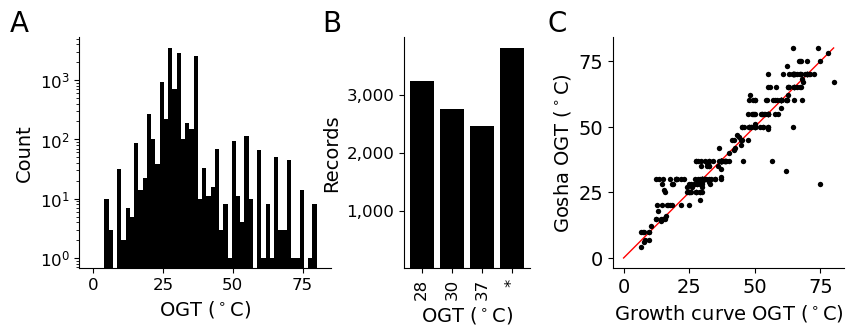

In [243]:
# Melnikov vs corkrey
fig= plt.figure(figsize=(10,3))
gs = mpl.gridspec.GridSpec(1, 3, width_ratios=[4,2,4])

# plot 1
# -----------------------------------
ax = fig.add_subplot(gs[0])
sns.histplot(melnikov['temperature'], linewidth=0, bins=50, color='k', alpha=1)
# sns.ecdfplot(melnikov['temperature'], stat='count', zorder=0, color='red')
ax.set_yscale('log')
ax.set_ylabel('Count', fontsize=14)
ax.set_xlabel('OGT ($^\circ$C)', fontsize=14)
sns.despine(left=True, bottom=True, right=True)
plt.tick_params(labelsize=12)
_ticks = [0, 25,50, 75]
ax.set_xticks(_ticks)
ax.set_xlim(-5, 85)
sns.despine()
ax.annotate('A', (-0.2, 1.025), ha='right',
            annotation_clip=False, xycoords='axes fraction', fontsize=20)

# plot 2
# -----------------------------------
ax = fig.add_subplot(gs[1])
plt.bar(['28', '30', '37', '*'], [3247, 2757, 2459, 3802], color='k')
plt.tick_params(labelsize=12)
plt.tick_params(rotation=90, axis='x')
ax.set_ylabel('Records', fontsize=14)
ax.set_xlabel('OGT ($^\circ$C)', fontsize=14)
# ax.set_yscale('log')
ax.set_yticks([1e3, 2e3, 3e3])
ax.set_yticklabels(['1,000', '2,000', '3,000'])
ax.annotate('B', (-0.5, 1.025), ha='right',
            annotation_clip=False, xycoords='axes fraction', fontsize=20)


# plot 3
# -----------------------------------
ax = fig.add_subplot(gs[2])
sns.scatterplot(x=corkrey_full['T.C'], y=merged.set_index('accession')['temperature'], linewidth=0, color='k', s=15)

plt.tick_params(labelsize=14)
ax.set_ylabel('Gosha OGT ($^\circ$C)', fontsize=14)
ax.set_xlabel('Growth curve OGT ($^\circ$C)', fontsize=14)
plt.plot((0, 80), (0, 80), color='r', linewidth=1, zorder=0)
_ticks = [0, 25,50, 75]
ax.set_yticks(_ticks)
ax.set_xticks(_ticks)
ax.annotate('C', (-0.2, 1.025), ha='right',
            annotation_clip=False, xycoords='axes fraction', fontsize=20)
ax.set_aspect('equal')

# fig formatting

sns.despine()
# plt.tight_layout()
fig.subplots_adjust(wspace=0.35)

plt.savefig('./../data/figures/finalized_figures/gosha_vs_corkrey.svg', bbox_inches='tight')
plt.savefig('./../data/figures/finalized_figures/gosha_vs_corkrey.png', bbox_inches='tight', dpi=400)

# Dataset descriptions (Figure 2)
Descriptions of all of the data in the test and training datasets, plus phylogenies for the test and training data

In [1035]:
gtdb_md = pd.read_csv('/data/mhoffert/genomes/GTDB_r214.1/bac120_metadata.tsv.gz', 
                      sep='\t', compression='gzip',
                     index_col=0)

In [1036]:
gtdb_md.head()

,ambiguous_bases,checkm_completeness,checkm_contamination,checkm_marker_count,checkm_marker_lineage,checkm_marker_set_count,checkm_strain_heterogeneity,coding_bases,coding_density,contig_count,...,ssu_silva_blast_align_len,ssu_silva_blast_bitscore,ssu_silva_blast_evalue,ssu_silva_blast_perc_identity,ssu_silva_blast_subject_id,ssu_silva_taxonomy,total_gap_length,trna_aa_count,trna_count,trna_selenocysteine_count
accession,,,,,,,,,,,,,,,,,,,,,
RS_GCF_001206855.1,14,99.60,0.91,761,g__Streptococcus (UID584),238,50.00,1827337,86.246727,77,...,1543,2844,0,99.935,CP028436.1781495.1783046,Bacteria;Firmicutes;Bacilli;Lactobacillales;St...,21,19,35,0
RS_GCF_001108865.1,13,99.39,0.34,761,g__Streptococcus (UID584),238,33.33,1852015,86.277715,51,...,1543,2844,0,99.935,AKVY01000001.1976120.1977665,Bacteria;Firmicutes;Bacilli;Lactobacillales;St...,0,19,38,0
RS_GCF_000730125.1,30,100.00,0.92,476,f__Bifidobacteriaceae (UID1462),217,0.00,2212698,86.271453,45,...,1522,2811,0,100,CP008885.1576966.1578495,Bacteria;Actinobacteriota;Actinobacteria;Bifid...,619,19,55,0
RS_GCF_000950275.1,0,99.45,0.53,921,f__Vibrionaceae (UID4865),366,0.00,4128151,84.994806,57,...,655,1210,0,100,KY272023.1.1437,Bacteria;Proteobacteria;Gammaproteobacteria;En...,0,17,77,1
RS_GCF_000468955.1,0,100.00,0.00,472,o__Lactobacillales (UID543),265,0.00,2107260,86.823994,1,...,1545,2848,0,99.935,CP003157.2105633.2107180,Bacteria;Firmicutes;Bacilli;Lactobacillales;St...,0,19,60,0


## Histplots of Topts

In [26]:
with open('./../data/predictive_models/supporting_data/even_genome_ids.txt', 'r') as handle:
    even_ids = [l.strip() for l in handle.readlines()]

with open('./../data/predictive_models/supporting_data/corkrey_genome_ids.txt', 'r') as handle:
    corkrey_ids = [l.strip() for l in handle.readlines()]

In [27]:
print(len(even_ids), len(corkrey_ids))

1227 230


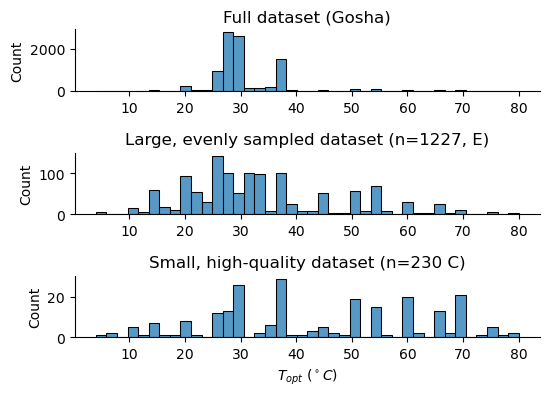

In [1022]:
fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(3, 1, 1)
sns.histplot(temp_data['temp'], bins=40)
ax.set_title('Full dataset (Gosha)')
ax.set_xlabel('')
sns.despine()

ax = fig.add_subplot(3, 1, 2)
sns.histplot(temp_data[temp_data['uid'].isin(even_ids)]['temp'], bins=40)
ax.set_title(f'Large, evenly sampled dataset (n={len(even_ids)}, E)')
ax.set_xlabel('')
sns.despine()

ax = fig.add_subplot(3, 1, 3)
sns.histplot(temp_data[temp_data['uid'].isin(corkrey_ids)]['temp'], bins=40)
ax.set_title(f'Small, high-quality dataset (n={len(corkrey_ids)} C)')
sns.despine()
fig.subplots_adjust(hspace=1)
ax.set_xlabel('$T_{opt}$ ($^\circ{C}$)')
plt.savefig('./../data/figures/finalized_figures/Fig1_dataset_dists.svg', bbox_inches='tight')

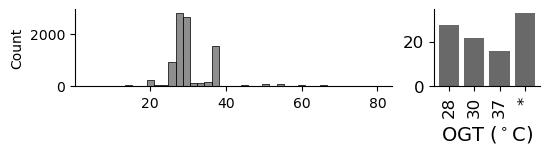

In [510]:
fig = plt.figure(figsize=(6,1))
gs = fig.add_gridspec(1, 2, width_ratios=[3, 1])
ax = fig.add_subplot(gs[0])
sns.histplot(temp_data['temp'], bins=40, color='dimgray')
# ax.set_title('Full dataset (Gosha)')
ax.set_xlabel('')
sns.despine()  

# plot 2
# -----------------------------------
ax = fig.add_subplot(gs[1])
plt.bar(['28', '30', '37', '*'], (np.array([2612, 2077, 1533, 3141]) / 9532) * 100, color='dimgray')
plt.tick_params(labelsize=12)
plt.tick_params(rotation=90, axis='x')
# ax.set_ylabel('Records', fontsize=14)
ax.set_xlabel('OGT ($^\circ$C)', fontsize=14)
sns.despine()
# ax.set_yscale('log')
# ax.set_yticks([1e3, 2e3, 3e3])
# ax.set_yticklabels(['1,000', '2,000', '3,000'])
# ax.annotate('B', (-0.5, 1.025), ha='right',
#             annotation_clip=False, xycoords='axes fraction', fontsize=20)
plt.savefig('./../data/figures/finalized_figures/gosha_only.svg')

In [501]:
temp_data['temp'].value_counts().sort_values() #/ len(temp_data)

temp
73.0       1
72.0       1
61.0       1
79.0       1
49.0       1
        ... 
29.0     558
25.0     755
37.0    1533
30.0    2077
28.0    2612
Name: count, Length: 69, dtype: int64

In [505]:
temp_data.columns

Index(['Position', 'Contacts at 4.5 Å', 'SASA', 'uid', 'total_score',
       'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'cav_vol', 'dslf_fa13',
       'fa_atr', 'fa_dun', 'fa_elec', 'fa_intra_rep', 'fa_intra_sol_xover4',
       'fa_rep', 'fa_sol', 'hbond_bb_sc', 'hbond_lr_bb', 'hbond_sc',
       'hbond_sr_bb', 'internal_hbonds', 'lk_ball_wtd', 'nonpolar_sasa',
       'omega', 'p_aa_pp', 'packstat', 'polar_sasa', 'pro_close',
       'rama_prepro', 'ref', 'sasa', 'sc_internal_hbonds', 'total_cc_contacts',
       'yhh_planarity', '%S', '%L', '%H', 'length', 'avg_cc_contacts_per_res',
       'temp', 'mean_temp', 'seq_length', 'bitscore', 'C', 'L', 'N', 'P',
       'max_structure_length', 'lid_bitscore'],
      dtype='object')

## Trees

In [1109]:
genome2temp = temp_data.set_index('uid')['temp']

In [1110]:
# get tree for each dataset
corkrey_tree = gtdb_full.copy()
corkrey_tree.prune([i for i in corkrey_ids if i in genome2temp.index], preserve_branch_length=True)
corkrey_tree.describe()

Number of leaf nodes:	230
Total number of nodes:	459
Rooted:	Yes
Most distant node:	RS_GCF_000425445.1
Max. distance:	2.145353


In [1111]:
corkrey_tree.ladderize()

230

In [1112]:
np.sum([i in genome2temp.index for i in corkrey_ids])

230

In [1113]:
# get tree for each dataset
even_tree = gtdb_full.copy()
even_tree.prune([i for i in even_ids if i in genome2temp.index], preserve_branch_length=True)
even_tree.describe()

Number of leaf nodes:	1227
Total number of nodes:	2453
Rooted:	Yes
Most distant node:	RS_GCF_000701485.1
Max. distance:	2.807948


In [1114]:
even_tree.ladderize()

1227

In [1115]:
np.sum([i in genome2temp.index for i in even_ids])

1227

In [1116]:
gtdb_pruned.ladderize()

9341

(0.0, 1.0, 0.0, 1.0)

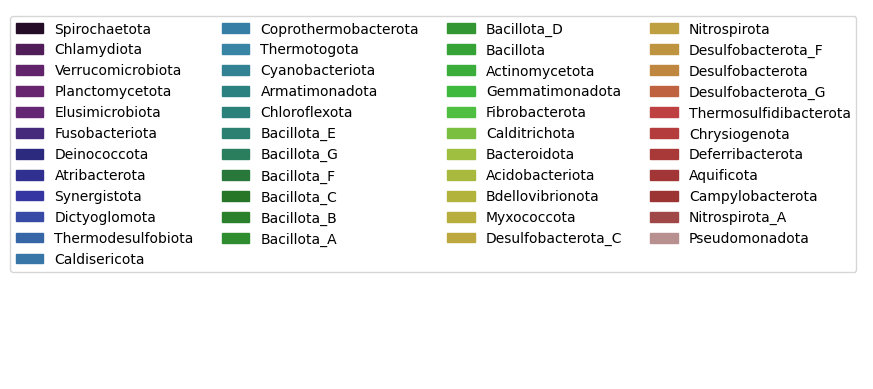

In [1117]:
# make a phylum colormap
phyla = gtdb_md.loc[[l.name for l in gtdb_pruned.get_leaves()], 'gtdb_taxonomy'].apply(lambda x: x.split(';')[1]).unique()
# np.random.shuffle(phyla)
phylum_cmap = dict((p.lstrip('p__'), mpl.colors.to_hex(sns.desaturate(c, 0.5))) for p, c in zip(phyla, sns.color_palette('nipy_spectral', n_colors=len(phyla))))

# and legend
handles = [mpl.patches.Patch(color=i, label=k) for k,i in phylum_cmap.items()]
plt.legend(handles=handles, ncol=4)
plt.axis('off')

In [1118]:
leaf2phylum = gtdb_md.loc[[l.name for l in gtdb_pruned.get_leaves()], 'gtdb_taxonomy'].apply(lambda x: x.split(';')[1].lstrip('p_'))

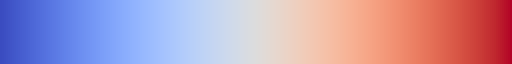

In [1119]:
norm = mpl.colors.Normalize(temp_data['temp'].min(), temp_data['temp'].max())
Topt_cmap = mpl.colormaps['coolwarm']
Topt_cmap

In [1120]:
names_map.shape

(80788,)

In [1121]:
def get_level_names(subset_tree, full_tree, name_mapping, level):
    '''
    for a subsetted tree from full tree
    which may be missing nodes due to pruning, 
    use the full tree to get the taxstring for "level" of each node
    subset_tree: tree
    full_tree: tree
    name_mapping: series mapping interior nodes in full tree to taxnomy
    level: level to get
    '''
    level2str = {0:'d__', 1:'p__', 2:'c__', 3:'o__', 4:'f__', 5:'g__'}
    assert level in level2str.keys(), f'level must be one of {level2str.keys()}'
    taxa_labels = pd.Series()
    for node in tqdm(list(subset_tree.traverse())):
        # get node in original tree
        og_node = full_tree.search_nodes(name=node.name)[0]
        if node.is_leaf():
            og_node = og_node.up
        # traverse up
        # save phylum
        label = ''
        while og_node is not None:
            if level2str[level] in name_mapping.loc[og_node.name]:
                label = name_mapping.loc[og_node.name]
                break
            og_node = og_node.up
            
        taxa_labels.loc[node.name] = label
    return taxa_labels
    


In [1122]:
corkrey_phyla = get_level_names(corkrey_tree, gtdb_full, names_map, 1)

100%|██████████████████████████████████████████████████████████████████| 459/459 [01:43<00:00,  4.45it/s]


In [1123]:
corkrey_phyla.head()

c000000                         
c000216    99.0:p__Spirochaetota
c000050                         
c000319    99.0:p__Spirochaetota
c000320    99.0:p__Spirochaetota
dtype: object

In [1144]:
from ete3. import ScatterFace

ImportError: cannot import name 'ScatterFace' from 'ete3' (/data/mhoffert/miniforge3/envs/adenylate_kinase_ogt/lib/python3.10/site-packages/ete3-3.1.3-py3.10.egg/ete3/__init__.py)

In [1157]:
temp_norm = mpl.colors.Normalize(0, 80)

def node_style(node, leaf2phylum, phylum_labels):

    ns = NodeStyle()
    ns['size'] = 0

    if node.is_leaf():
        # Add a colored square (Face) and a Phylum label

        # if node.name in corkrey_ids:
        #     color='k'
        # else:
        #     color='white'
            
        # faces.add_face_to_node(RectFace(150, 2, color, color), node, column=0, position="aligned")
        
        # if node.name in corkrey_ids:
        #   color='white'  
        # elif node.name in ogtfinder_temps.index:
        #     color='red'
        # else:
        #     color='blue'
        color=mpl.colors.to_hex(Topt_cmap(norm(genome2temp.loc[node.name])))

        # ns['size'] = 1
        faces.add_face_to_node(RectFace(temp_norm(structural_data.loc[node.name, 'temp']) * 20, 0.25, color, color), node, column=1, position="aligned")



    # l2p_nodeval = leaf2phylum.loc[[l.name for l in node.get_leaves()]].unique()
    # print(len(l2p_nodeval))
    # if len(l2p_nodeval) == 1:
        # ns['hz_line_color'] = phylum_cmap[l2p_nodeval[0]]
        # ns['vt_line_color'] = phylum_cmap[l2p_nodeval[0]]
        # ns['size'] = 0
        # ns['bgcolor'] = mpl.colors.to_hex(sns.desaturate(phylum_cmap[node.name.split('p__')[-1].split(';')[0]], 0.75))
    # if '__' in node.name:
    if node.name in phylum_labels.index:
        faces.add_face_to_node(TextFace(f"  {phylum_labels.loc[node.name].split('__')[-1]}", fgcolor='black', fsize=6), node, column=0, position="branch-right")

    node.img_style = ns
    
   




In [1146]:
lorder = [node.name for node in corkrey_tree.traverse('levelorder')]
corkrey_phyla_dedup = corkrey_phyla.drop_duplicates(keep='first')

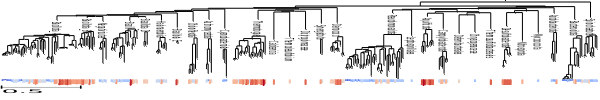

In [1158]:
ts = TreeStyle()
# ts.mode='c'
ts.rotation = 90
ts.show_leaf_name = False # Keep original leaf names
ts.layout_fn = lambda n: node_style(n, leaf2phylum, corkrey_phyla_dedup)
ts.draw_guiding_lines = False
ts.scale = 100

corkrey_tree.render("%%inline", tree_style=ts, w=600, h=100)

In [1156]:
rendered = corkrey_tree.render("./../data/figures/finalized_figures/corkrey_tree.svg", tree_style=ts)

In [1159]:
even_phyla = get_level_names(even_tree, gtdb_full, names_map, 1)

100%|████████████████████████████████████████████████████████████████| 2453/2453 [09:08<00:00,  4.47it/s]


In [1160]:
lorder = [node.name for node in even_tree.traverse('levelorder')]
even_phyla_dedup = even_phyla.drop_duplicates(keep='first')

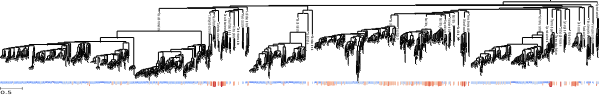

In [1161]:
ts = TreeStyle()
# ts.mode='c'
ts.rotation = 90
ts.show_leaf_name = False # Keep original leaf names
ts.layout_fn = lambda n: node_style(n, leaf2phylum, even_phyla_dedup)
ts.draw_guiding_lines = False
ts.scale = 100

even_tree.render("%%inline", tree_style=ts, w=600, h=100)

In [1162]:
rendered = even_tree.render("./../data/figures/finalized_figures/even_tree.svg", tree_style=ts)

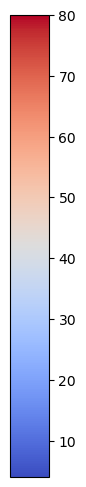

In [1053]:
fig, ax = plt.subplots(figsize=(0.5, 6))
plt.colorbar(mpl.cm.ScalarMappable(norm, Topt_cmap), cax=ax)
plt.savefig('./../data/figures/finalized_figures/temp_cbar.svg', bbox_inches='tight')

# Model accuracy figure (Figure 3)

In [13]:
model = f'even_enetcv_ind'
model_pickle = f'./../data/predictive_models/{model}.pickle'
loaded_model = reload_model(model_pickle)

# load scaler
scaler = reload_model('./../data/predictive_models/supporting_data/ogt_scaler.pickle')

### Basic checks on saved embeddings

In [89]:
# helper functions for test
def load_pickle(path):
    with open(path, "rb") as handle:
        return pickle.load(handle)

def per_site_predict(model, emb, scalers):
    """Copy of src/models/predict.py::per_site_predict (v1)."""
    preds = []
    for col in sorted(model.keys()):
        if scalers is not None:
            site_emb = scalers[col].transform(emb[:, col, :])
        else:
            site_emb = emb[:, col, :]
        preds.append(model[col].predict(site_emb))
    return preds

In [90]:
# predictions from loaded model w/ saved embeddings
embeddings = load_pickle('./../data/esm_msa/c_w_e_full_embeddings.pickle')
emb_preds = np.array(per_site_predict(loaded_model["best_model"], embeddings, loaded_model["scalers"]))
# emb_preds = unscale_ogts(emb_preds, scaler)
emb_preds.shape

(215, 230)

In [91]:
loaded_preds = loaded_model['full_predictions'][:, :]
loaded_preds.shape

(215, 230)

In [92]:
keys = list(loaded_model["best_model"].keys())
print(keys[184:], keys == sorted(keys))

[185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 184] False


Text(0, 0.5, 'saved preds')

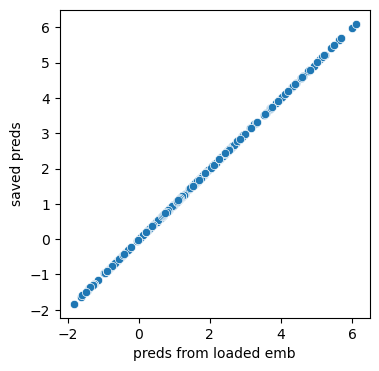

In [93]:
fig, ax = plt.subplots(figsize=(4,4))
sns.scatterplot(x=emb_preds.mean(0), y=loaded_preds.mean(0))
ax.set_xlabel('preds from loaded emb')
ax.set_ylabel('saved preds')

In [94]:
diffs = emb_preds - loaded_preds

In [96]:
diffs

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

### Actual plots

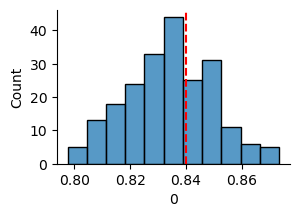

In [35]:
col_rs = pd.read_csv('./../data/predictive_models/supporting_data/even_enetcv_ind_spearmans.tsv',
                        sep='\t', index_col=0)['0']
fig, ax = plt.subplots(figsize=(3,2))
sns.histplot(col_rs)
cutoff = 0.84
ax.axvline(cutoff, color='r', linestyle='--')
sns.despine()
good_cols = col_rs[col_rs > cutoff].index

In [36]:
# # old code to add extra predictions
# with open('./../data/esm_msa/extra_full_embeddings.pickle', 'rb') as handle:
#     efe = pickle.load(handle)

# with open('./../data/esm_msa/extra_temps.pickle', 'rb') as handle:
#     extra_temps = pickle.load(handle)

# extra_preds = np.array([loaded_model['best_model'][i].predict(efe[:, i, :]) for i in good_cols]).mean(0)

## data for B: Tome corkrey preds vs actual

In [37]:
# results from running tome on corkrey data
corkrey_tomes = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/validation_datasets/tomes/corkrey_tome_predictions_Eventraining.tsv', sep='\t')
# reformat genome
corkrey_tomes['genome'] = corkrey_tomes['FileName'].apply(lambda x: x.replace('_protein.fasta', ''))

corkrey_tomes_plotdf = pd.merge(genome2temp, corkrey_tomes, left_index=True, right_on='genome')
corkrey_tomes_plotdf.shape
corkrey_tomes_plotdf.head()

,temp,FileName,predOGT (C),genome
0,37.0,GB_GCA_003148465.1_protein.fasta,41.37,GB_GCA_003148465.1
1,47.0,RS_GCF_000006985.1_protein.fasta,31.15,RS_GCF_000006985.1
2,20.0,RS_GCF_000007925.1_protein.fasta,25.12,RS_GCF_000007925.1
3,10.0,RS_GCF_000012325.1_protein.fasta,16.18,RS_GCF_000012325.1
4,37.0,RS_GCF_000013285.1_protein.fasta,34.91,RS_GCF_000013285.1


## panels A and B

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


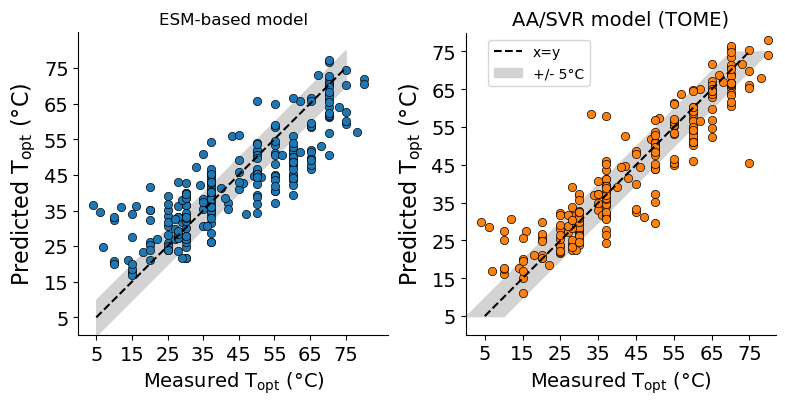

In [38]:
fig = plt.figure(figsize=(14,6))
# gs = plt.GridSpec(2, 3, width_ratios=[1,1,1], height_ratios=[1,1])
ax = fig.add_subplot(1, 3, 1)

y_true = unscale_ogts(loaded_model['true_values'], scaler)
y_pred = unscale_ogts(loaded_model['full_predictions'][good_cols, :].mean(axis=0), scaler)
sns.scatterplot(y=y_pred,
                x=y_true,
               zorder=3, edgecolor='k')


# sns.scatterplot(y=unscale_ogts(extra_preds, scaler),
#                 x=unscale_ogts(extra_temps, scaler),
#                zorder=2, linewidth=0, color='firebrick')

sns.despine()
ax.set_aspect('equal')
_lower, _upper = 0, 87
ax.set_xlim(_lower, _upper)
ax.set_ylim(_lower, 85)
ticks = list(range(5, 85, 10))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
line_lower, line_upper = 5, 75
plt.plot((line_lower, line_upper), 
         (line_lower, line_upper), 
         'k--', label='x=y', zorder=5)

ax.fill_between(np.linspace(line_lower, line_upper, 100), 
                 np.linspace(line_lower+5, line_upper+5, 100),
                np.linspace(line_lower-5, line_upper-5, 100),
                color='lightgray', zorder=0, label='+/- 5°C')

ax.tick_params(labelsize=14, axis='both')
ax.set_xlabel('Measured $\mathregular{T_{opt}}$ (°C)', fontsize=14)
ax.set_ylabel('Predicted $\mathregular{T_{opt}}$ (°C)', fontsize=16)

ax.set_title('ESM-based model')
# ax.annotate('R2 = , RMSE = ')


# ------ Ax 2 ------- 
ax = fig.add_subplot(1, 3, 2)
ax.tick_params(labelsize=14, axis='both')
ax.set_xlabel('Measured $\mathregular{T_{opt}}$ (°C)', fontsize=14)
ax.set_ylabel('Predicted $\mathregular{T_{opt}}$ (°C)', fontsize=16)

lgd = ax.legend(loc='center left', bbox_to_anchor=(0.05, 0.9))
# spr = myco_scores[myco_scores.model_label.eq(model)].iloc[0, 2]
# mse = myco_scores[myco_scores.model_label.eq(model)].iloc[0, 3]
ax.set_title(f'ESM-based model', fontsize=14)


sns.scatterplot(data=corkrey_tomes_plotdf, x='temp', y='predOGT (C)')
# ax = fig.add_subplot(gs[:, :1])
y_true = corkrey_tomes_plotdf['temp']
y_pred = corkrey_tomes_plotdf['predOGT (C)']
sns.scatterplot(y=y_pred,
                x=y_true,
               zorder=3, edgecolor='k')


# sns.scatterplot(y=unscale_ogts(extra_preds, scaler),
#                 x=unscale_ogts(extra_temps, scaler),
#                zorder=2, linewidth=0, color='firebrick')

sns.despine()
ax.set_aspect('equal')
_lower, _upper = 0, 82
ax.set_xlim(_lower, _upper)
ax.set_ylim(_lower, 80)
ticks = list(range(5, 80, 10))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
line_lower, line_upper = 5, 75
plt.plot((line_lower, line_upper), 
         (line_lower, line_upper), 
         'k--', label='x=y', zorder=5)

ax.fill_betweenx(np.linspace(line_lower, line_upper, 100), 
                 np.linspace(line_lower+5, line_upper+5, 100),
                np.linspace(line_lower-5, line_upper-5, 100),
                color='lightgray', zorder=0, label='+/- 5°C')


ax.tick_params(labelsize=14, axis='both')
ax.set_xlabel('Measured $\mathregular{T_{opt}}$ (°C)', fontsize=14)
ax.set_ylabel('Predicted $\mathregular{T_{opt}}$ (°C)', fontsize=16)

lgd = ax.legend(loc='center left', bbox_to_anchor=(0.05, 0.9))
ax.set_title(f'AA/SVR model (TOME)', fontsize=14)

fig.subplots_adjust(wspace=0.25)

### Notes
Should check the number / phylogenetic distance of examples from the training data to the testing data ...

In [39]:
n_aas = []
for g in tqdm(glob.glob('./../data/validation_datasets/tomes/even_genomes/*.fasta')):
    with open(g, 'r') as handle:
        n_aas.append(np.sum([len(r.seq) for r in SeqIO.parse(handle, format='fasta')]))
        

100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 1227/1227 [00:31<00:00, 38.39it/s]


<Axes: ylabel='Count'>

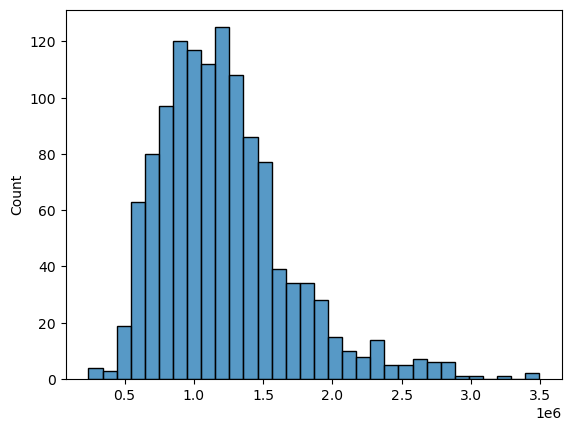

In [40]:
sns.histplot(n_aas)

In [63]:
np.mean(n_aas)

1217041.13202934

## Panel C

Code for constructing the "phylogenetic model" figure: Figure 2

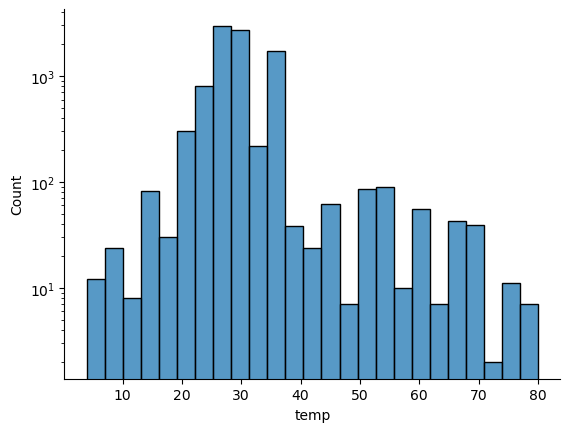

In [42]:
fig, ax = plt.subplots()
sns.histplot(genome2temp, bins=25)
ax.set_yscale('log')
sns.despine()


In [44]:
# make mapping of genome to taxonomy
genome2tax = gtdb_md.loc[:, 'gtdb_taxonomy']
# make sure all records are found
print(len(genome2tax))

# split levels into cols
levels = ['domain', 'phylum', 'class', 'order', 'family', 'genus', 'species']
genome2tax = genome2tax.apply(lambda x: pd.Series(index=levels, data=[i.split('__')[-1] for i in x.split(';')]))
# map index to sequences
# genome2tax = genome2tax.rename(index=msa_keys)

genome2tax.head()

394932


,domain,phylum,class,order,family,genus,species
accession,,,,,,,
RS_GCF_001206855.1,Bacteria,Bacillota,Bacilli,Lactobacillales,Streptococcaceae,Streptococcus,Streptococcus pneumoniae
RS_GCF_001108865.1,Bacteria,Bacillota,Bacilli,Lactobacillales,Streptococcaceae,Streptococcus,Streptococcus pneumoniae
RS_GCF_000730125.1,Bacteria,Actinomycetota,Actinomycetia,Actinomycetales,Bifidobacteriaceae,Bifidobacterium,Bifidobacterium infantis
RS_GCF_000950275.1,Bacteria,Pseudomonadota,Gammaproteobacteria,Enterobacterales_A,Vibrionaceae,Photobacterium,Photobacterium angustum
RS_GCF_000468955.1,Bacteria,Bacillota,Bacilli,Lactobacillales,Streptococcaceae,Lactococcus,Lactococcus cremoris


In [45]:
# get high quality observations
# not sure this is needed any more
# corkrey_matches = pd.read_csv('/data/mhoffert/fiererlab/ogt/results/db/corkey_gtdb_matching.tsv', sep='\t', index_col=0)
# corkrey_data = pd.read_csv('/data/mhoffert/fiererlab/ogt/source_data/Corkey_temperatures.csv')
# corkrey_full = pd.merge(corkrey_data.groupby('binomial.name').agg({'T.C':'mean'}), corkrey_matches, left_index=True, right_on='original_id')

# corkrey_ids = set(corkrey_full['match_accession'].unique())

# comparison_data = pd.read_csv('./../data/metric_tables/20250327_ogtfinder_merged_data.tsv', sep='\t', index_col=0)
# ogtfinder_temps = comparison_data.set_index('accession')['Temp_optimum'].dropna()

## Code for phylogenetic model

### Function defs for fast distance matrix

In [46]:
test_tree = Tree('(((E:0.1,D:0.2):0.3,C:0.5):0.1,(B:0.2,A:0.2):0.5);')
j = 1
for i, node in enumerate(test_tree.traverse(strategy='levelorder')):
    if not node.is_leaf():
        node.name = j 
        j += 1
print(test_tree)


         /-E
      /-|
   /-|   \-D
  |  |
--|   \-C
  |
  |   /-B
   \-|
      \-A


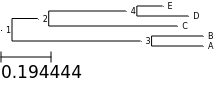

In [47]:
def node_style(node):

    ns = NodeStyle()
    ns['size'] = 0


    faces.add_face_to_node(TextFace(f"  {node.name}", fgcolor='black', fsize=6), node, column=0, position="branch-right")

    node.img_style = ns


ts = TreeStyle()
# ts.mode='c'
ts.show_leaf_name = False # Keep original leaf names
ts.layout_fn = node_style
ts.draw_guiding_lines = False


test_tree.render("%%inline", tree_style=ts) 

In [48]:
def get_lca_cache(tree):
    lca_cache = {}
    leaf_set = set()
    up_node = ''
    total = len(list(tree.traverse()))
    for i, node in enumerate(tree.traverse('preorder')):
        
        if not node.is_root():
            curr_set = set([l.name for l in node.get_leaves()])
            up_node = node.up
            up_set = set([l.name for l in up_node.get_leaves()])
            diff = up_set - curr_set
            
            pairs = [frozenset({l1, l2}) for l1, l2 in itertools.product(diff, curr_set)]
            for p in pairs:
                lca_cache[p] = up_node.name
        
        if i % (int(total / 100)+1) == 0:
            progress = '#' * int((i+1) / total * 20)
            bar_str = ' |'+f'{progress:<{20}}' + '| '
            display(f'progress: {bar_str} : {(i+1) / total * 100:.2f}%')
            clear_output(wait=True)
    return lca_cache




In [49]:
def get_root_dists(tree):
    node_dists = pd.Series()
    for node in tree.traverse():
        node_dists.loc[node.name] = tree.get_distance(node)

    return node_dists

In [50]:
def calculate_dist(node1, node2, dists, lca_cache):
    '''
    dists: distances to root, precomputed
    lca_cache: dict(frozenset(node1, node2)) = lca
    '''
    if node1 != node2:
        return dists.loc[node1] + dists.loc[node2] - (2*dists.loc[lca_cache[frozenset({node1, node2})]])
    else:
        return 0
    

In [51]:
def get_common_prefix(a, b):
    # zip pairs items until the shortest list ends
    for i, (item1, item2) in enumerate(zip(a, b)):
        if item1 != item2:
            return a[:i]
    # If one list is a complete prefix of the other
    return a[:min(len(a), len(b))]

In [52]:
dists = get_root_dists(test_tree)
lca_cache2 = get_lca_cache(test_tree)

'progress:  |####################|  : 100.00%'

In [53]:
leaves = [l for l in test_tree]
for l1, l2 in itertools.product(leaves, leaves):
    ete3_est = np.round(test_tree.get_distance(target=l1, target2=l2))
    custom_est = np.round(calculate_dist(l1.name, l2.name, dists, lca_cache2))
    assert ete3_est == custom_est, f'estimates are not equal: {ete3_est}, {custom_est}'

In [54]:
%%time
leaves = [l for l in test_tree]
for l1, l2 in itertools.product(leaves, leaves):
    test_tree.get_distance(target=l1, target2=l2)
          

CPU times: user 463 µs, sys: 0 ns, total: 463 µs
Wall time: 475 µs


In [55]:
%%time
leaves = [l for l in test_tree]
for l1, l2 in itertools.product(leaves, leaves):
    calculate_dist(l1.name, l2.name, dists, lca_cache2)
          

CPU times: user 1.01 ms, sys: 0 ns, total: 1.01 ms
Wall time: 1.02 ms


### Running distance matrix code

In [56]:
%%time
lca_cache = get_lca_cache(gtdb_pruned)

CPU times: user 2min 43s, sys: 13 s, total: 2min 56s
Wall time: 2min 54s


In [57]:
%%time
dists = get_root_dists(gtdb_pruned)

CPU times: user 23.7 s, sys: 178 ms, total: 23.9 s
Wall time: 23.7 s


### phylogenetic model code

In [58]:
with open('./../data/validation_datasets/tomes/even_genome_ids.txt', 'r') as handle:
    even_ids = [l.strip() for l in handle.readlines()  if l.strip() != '']

with open('./../data/validation_datasets/tomes/corkrey_genome_ids.txt', 'r') as handle:
    corkrey_ids = [l.strip() for l in handle.readlines() if l.strip() != '']

print(len(even_ids), len(corkrey_ids))

1227 230


In [59]:
phylo_preds, phylo_actual, phylo_ids = [], [], []
pruned_leaves = set([l.name for l in gtdb_pruned.get_leaves()])
for c_id in tqdm(corkrey_ids):
    if c_id in pruned_leaves:
        _dists = [calculate_dist(c_id, e_id, dists, lca_cache) for e_id in even_ids if e_id in pruned_leaves]
        closest = even_ids[np.argmin(_dists)]
        phylo_preds.append(genome2temp.loc[closest])
        phylo_actual.append(genome2temp.loc[c_id])
        phylo_ids.append(c_id)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 230/230 [00:06<00:00, 36.78it/s]


In [60]:
calculate_dist(corkrey_ids[8], even_ids[0], dists, lca_cache)

2.151014451

## Full plot: panels A, B, and C

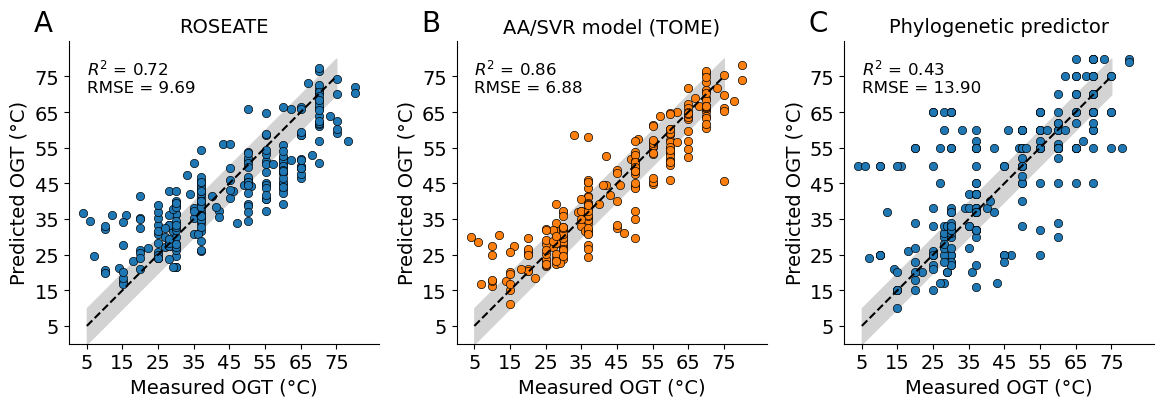

In [245]:
fig = plt.figure(figsize=(14,6))
# gs = plt.GridSpec(2, 3, width_ratios=[1,1,1], height_ratios=[1,1])

axes = []
for i in range(1, 4):
    axes.append(fig.add_subplot(1, 3, i))


# ------ Ax 1 -------
ax = axes[0]
y_true = unscale_ogts(loaded_model['true_values'], scaler)
y_pred = unscale_ogts(loaded_model['full_predictions'][good_cols, :].mean(axis=0), scaler)
sns.scatterplot(y=y_pred,
                x=y_true,
               zorder=3, edgecolor='k', ax=ax)

ax.set_title('ROSEATE', fontsize=14)
r2 = r2_score(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
ax.annotate(f'$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}', 
            xy=(5, 75), va='center', fontsize=12)
ax.annotate('A', (-10, 90), fontsize=20,
           annotation_clip=False, va='center')

# # ------ Ax 2 ------- 
ax = axes[1]

sns.scatterplot(data=corkrey_tomes_plotdf, x='temp', y='predOGT (C)', ax=ax)
# ax = fig.add_subplot(gs[:, :1])
y_true = corkrey_tomes_plotdf['temp']
y_pred = corkrey_tomes_plotdf['predOGT (C)']
sns.scatterplot(y=y_pred,
                x=y_true,
               zorder=3, edgecolor='k', ax=ax)

ax.set_title(f'AA/SVR model (TOME)', fontsize=14)
r2 = r2_score(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
ax.annotate(f'$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}', 
            xy=(5, 75), va='center', fontsize=12)
ax.annotate('B', (-10, 90), fontsize=20,
           annotation_clip=False, va='center')

# ------- Ax 3 --------
ax = axes[2]
sns.scatterplot(y=phylo_preds,
                x=phylo_actual,
               zorder=3, edgecolor='k', ax=ax)

ax.set_title(f'Phylogenetic predictor', fontsize=14)
r2 = r2_score(phylo_actual, phylo_preds)
rmse = np.sqrt(mean_squared_error(phylo_actual, phylo_preds))
ax.annotate(f'$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}', 
            xy=(5, 75), va='center', fontsize=12)
ax.annotate('C', (-10, 90), fontsize=20,
           annotation_clip=False, va='center')


for ax in axes:
    sns.despine()
    ax.set_aspect('equal')
    _lower, _upper = 0, 87
    ax.set_xlim(_lower, _upper)
    ax.set_ylim(_lower, 85)
    ticks = list(range(5, 85, 10))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    line_lower, line_upper = 5, 75
    
    ax.plot((line_lower, line_upper), 
             (line_lower, line_upper), 
             'k--', label='x=y', zorder=5)

    ax.fill_between(np.linspace(line_lower, line_upper, 100), 
                     np.linspace(line_lower+5, line_upper+5, 100),
                    np.linspace(line_lower-5, line_upper-5, 100),
                    color='lightgray', zorder=0, label='+/- 5°C')

    ax.tick_params(labelsize=14, axis='both')
    ax.set_xlabel('Measured OGT (°C)', fontsize=14)
    ax.set_ylabel('Predicted OGT (°C)', fontsize=14)

fig.subplots_adjust(wspace=0.25)

plt.savefig('./../data/figures/finalized_figures/model_comparison.svg', bbox_inches='tight')
plt.savefig('./../data/figures/finalized_figures/model_comparison.png', bbox_inches='tight', dpi=400)


# Old code for distance vs accuracy plot

In [419]:
pd.Series(index=phylo_ids, data=phylo_preds) 

GB_GCA_003148465.1    45.0
RS_GCF_000006985.1    47.0
RS_GCF_000007925.1    50.0
RS_GCF_000010305.1    60.0
RS_GCF_000012325.1    25.0
                      ... 
RS_GCF_900176305.1    45.0
RS_GCF_900182585.1    65.0
RS_GCF_900215245.1    28.0
RS_GCF_900215515.1    65.0
RS_GCF_900215655.1    65.0
Length: 250, dtype: float64

<Axes: >

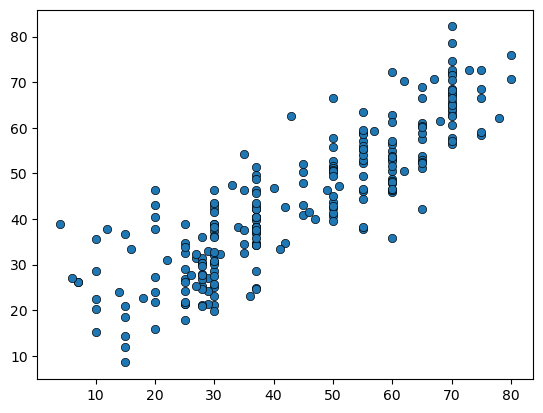

In [420]:
y_true = unscale_ogts(loaded_model['true_values'], scaler)
y_pred = unscale_ogts(loaded_model['full_predictions'][good_cols, :].mean(axis=0), scaler)
sns.scatterplot(y=y_pred,
                x=y_true,
               zorder=3, edgecolor='k')

In [421]:
unscale_ogts(loaded_model['true_values'], scaler)

array([37., 47., 20., 10., 37., 60., 55., 70., 25., 55., 49., 65., 50.,
       26., 60., 70., 68., 70., 42., 28., 75., 65., 60., 70.,  7., 67.,
       50., 50., 37., 30., 65., 37.,  7., 35., 42., 50., 75., 75., 37.,
       25., 70., 70., 45., 30., 55., 30., 50., 50., 70., 46., 30., 50.,
       30., 65., 30., 25., 60., 25., 37., 65., 55., 30., 55., 22., 37.,
       60., 29., 37., 27., 37., 25., 55., 10., 34., 37., 15., 28., 43.,
       51., 30., 30., 50., 30., 28., 33., 28., 45., 45., 25., 65., 37.,
       80., 40., 62., 50., 37., 20., 60., 50., 29., 60., 70., 35., 60.,
       29., 70., 60., 20., 37., 70., 50., 37., 35., 37., 30., 70., 37.,
       55., 70., 60., 28., 37., 35., 10., 65., 70., 50., 37., 28., 30.,
       55., 60., 12., 65., 25., 14., 30., 65., 75., 15., 16., 28., 29.,
       37., 55., 50., 37., 55., 18., 10., 28., 27., 50., 60., 36., 70.,
       31., 30., 78., 30., 37., 37., 25., 60., 37., 15.,  4., 10.,  6.,
       35., 37., 28., 60., 50., 30., 37., 37., 55., 60., 50., 55

In [808]:
leaves = [l.name for l in gtdb_pruned.get_leaves()]
sampled_leaves = gtdb_md.loc[leaves, 'gtdb_taxonomy'].apply(lambda x: x.split(';')[5]).reset_index().groupby('gtdb_taxonomy').sample(n=1, replace=True)['accession'].unique()
len(sampled_leaves)

2688

In [809]:

dist_results = []

for i, (l1, l2) in enumerate(itertools.combinations(sampled_leaves, 2)):
    if i % 1000 == 0:
        display(i)
        clear_output(wait=True)

    str1 = gtdb_md.loc[l1, 'gtdb_taxonomy'].split(';')
    str2 = gtdb_md.loc[l2, 'gtdb_taxonomy'].split(';')
    shared_tax = len(get_common_prefix(str1, str2))
    temp_diff = np.sqrt((genome2temp.loc[l1, 'mean_temp'] - genome2temp.loc[l2, 'mean_temp'])**2)
    dist_results.append([l1, l2, calculate_dist(l1, l2, dists, lca_cache), temp_diff, shared_tax])

3611000

In [810]:
plotdf = pd.DataFrame(dist_results, columns=['leaf1', 'leaf2', 'dist', 'rse', 'shared_level'])
plotdf['group'] = pd.cut(plotdf['dist'], np.linspace(0, 5, 100)).apply(lambda x: x.mid)

In [811]:
def percentile(n):
    def percentile_(x):
        return x.quantile(n)
    percentile_.__name__ = 'percentile_{:02.0f}'.format(n*100)
    return percentile_

In [813]:
idx = pd.IndexSlice

In [816]:
plotdf['group2'] = pd.cut(plotdf['dist'], np.linspace(0, 5, 10)).apply(lambda x: x.mid)

In [819]:
plotdf['group2'].value_counts().sort_index()

group2
0.278                   24922
0.8335                 133888
1.389                  300498
1.9445000000000001     443352
2.5                   1306090
3.0555000000000003    1144939
3.6109999999999998     232486
4.1665                  23097
4.7219999999999995       2055
Name: count, dtype: int64

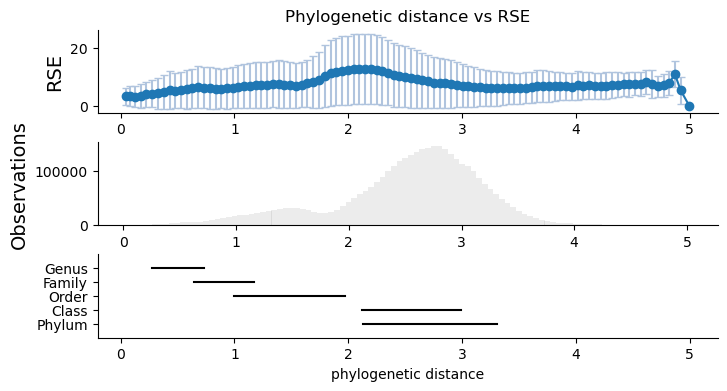

In [878]:
fig = plt.figure(figsize=(8,4))
gs = plt.GridSpec(3, 1)
ax = fig.add_subplot(gs[0])

# 1. Aggregate data by group
stats_df = plotdf.groupby('group', observed=True).agg(
    mean_dist=('dist', 'mean'),
    mean_rse=('rse', 'mean'),
    std_rse=('rse', 'std'),
    count=('rse', 'count')
).reset_index()

# Plot the RSE with Error Bars
# capsize adds the little horizontal lines to the error bars

z_score = 1.96 
stats_df['ci'] = z_score * (stats_df['std_rse'] / np.sqrt(stats_df['count']))

ax.errorbar(
    stats_df['mean_dist'], 
    stats_df['mean_rse'], 
    yerr=stats_df['std_rse'], 
    fmt='-o', 
    color='tab:blue', 
    ecolor='lightsteelblue', 
    capsize=3, 
    label='Mean RSE (95% CI)'
)

ax.set_xlabel('Distance')
ax.set_ylabel('RSE', fontsize=14)
ax.set_title('Phylogenetic distance vs RSE')

# 4. Add the 'Count' as a background histogram to show sample size drop-off
ax2 = fig.add_subplot(gs[1])
ax2.bar(
    stats_df['mean_dist'], 
    stats_df['count'], 
    alpha=0.15, 
    color='gray', 
    width=(stats_df['mean_dist'].diff().mean() or 0.1),
    label='Sample Size (n)'
)
ax2.set_ylabel('Observations', fontsize=14)

# Combined Legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left')

# ax.fill_between(temp['dist'], 
#                 temp['mean'] + temp['std'],
#                temp['mean'] - temp['std'], alpha=0.25)

# ax.set_xlabel('')
ax = fig.add_subplot(gs[2], sharex=ax)
for index, row in plotdf.groupby('shared_level').agg({'dist':[percentile(.90), percentile(.10)]}).iterrows():
    plt.plot((row.loc[idx['dist', 'percentile_10']], row.loc[idx['dist', 'percentile_90']]),
             (row.name, row.name), color='k')
sns.despine()
ax.set_xlabel('phylogenetic distance')
ax.set_yticks(range(1,6))
ax.set_ylim(0, 6)
text = ax.set_yticklabels(['Genus', 'Family', 'Order', 'Class', 'Phylum'][::-1])
fig. subplots_adjust(hspace=0.35)

In [865]:
stats_df

,group,mean_dist,mean_rse,std_rse,count
0,0.02525,0.044991,3.283333,2.896411,10
1,0.07575,0.082364,3.433677,3.317507,98
2,0.12650,0.128752,3.230113,3.633413,295
3,0.17700,0.182541,3.416050,4.052551,734
4,0.22750,0.227332,3.991876,4.435325,1387
...,...,...,...,...,...
94,4.77250,4.774663,7.112432,3.981975,122
95,4.82300,4.819605,8.008900,4.073265,103
96,4.87350,4.869272,10.986905,4.449457,35
97,4.92400,4.919611,5.428922,4.685133,17


<Axes: xlabel='rse', ylabel='Count'>

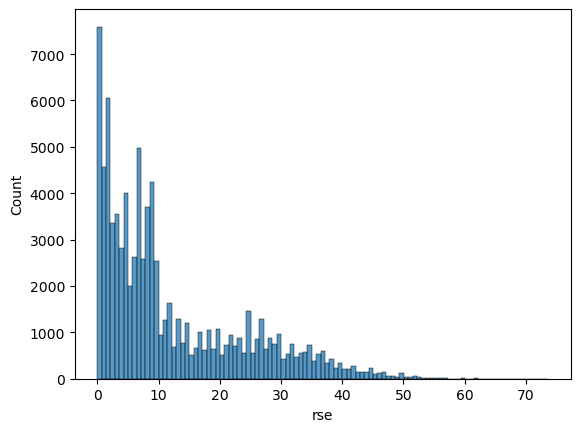

In [857]:
sns.histplot(plotdf[plotdf.group.eq(2.29800)]['rse'])

In [858]:
plotdf[plotdf.group.eq(2.29800)]['rse'].std()

11.719685071213744

In [859]:
stats_df

,group,mean_dist,mean_rse,std_rse,count,ci
0,0.02525,0.044991,3.283333,2.896411,10,1.795214
1,0.07575,0.082364,3.433677,3.317507,98,0.656833
2,0.12650,0.128752,3.230113,3.633413,295,0.414629
3,0.17700,0.182541,3.416050,4.052551,734,0.293181
4,0.22750,0.227332,3.991876,4.435325,1387,0.233423
...,...,...,...,...,...,...
94,4.77250,4.774663,7.112432,3.981975,122,0.706602
95,4.82300,4.819605,8.008900,4.073265,103,0.786648
96,4.87350,4.869272,10.986905,4.449457,35,1.474107
97,4.92400,4.919611,5.428922,4.685133,17,2.227171


/tmp/ipykernel_3157481/1529758137.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats_df = plotdf.groupby('group').agg(


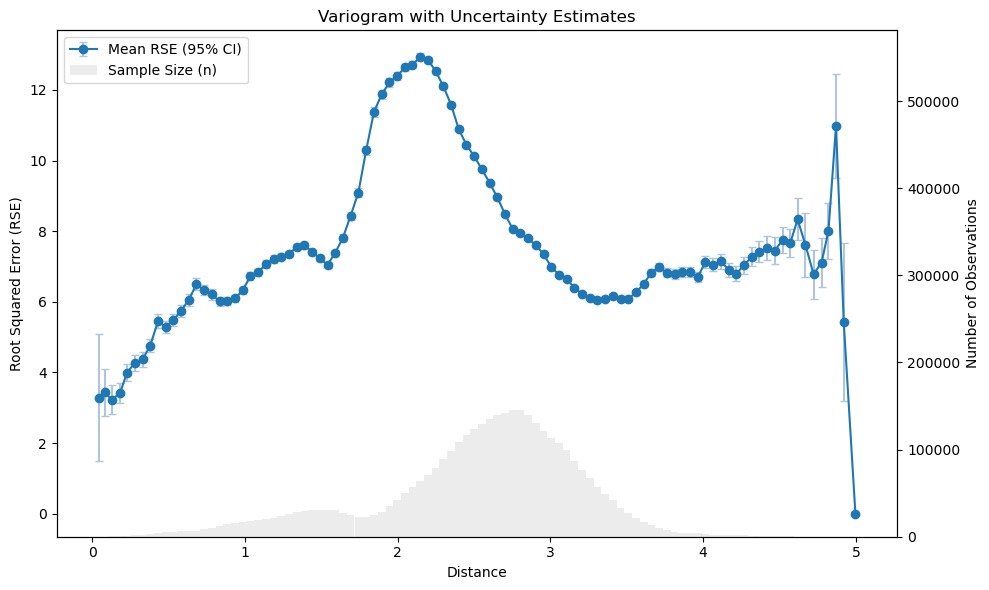

In [852]:
# Assuming your dataframe is named 'df'
# columns: 'dist' (x), 'rse' (y), 'group' (bins)


# 2. Calculate 95% Confidence Interval
# CI = z * (std / sqrt(n))
z_score = 1.96 
stats_df['ci'] = z_score * (stats_df['std_rse'] / np.sqrt(stats_df['count']))

# 3. Plotting
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot the RSE with Error Bars
# capsize adds the little horizontal lines to the error bars
ax1.errorbar(
    stats_df['mean_dist'], 
    stats_df['mean_rse'], 
    yerr=stats_df['ci'], 
    fmt='-o', 
    color='tab:blue', 
    ecolor='lightsteelblue', 
    capsize=3, 
    label='Mean RSE (95% CI)'
)

ax1.set_xlabel('Distance')
ax1.set_ylabel('Root Squared Error (RSE)')
ax1.set_title('Variogram with Uncertainty Estimates')

# 4. Add the 'Count' as a background histogram to show sample size drop-off
ax2 = ax1.twinx()
ax2.bar(
    stats_df['mean_dist'], 
    stats_df['count'], 
    alpha=0.15, 
    color='gray', 
    width=(stats_df['mean_dist'].diff().mean() or 0.1),
    label='Sample Size (n)'
)
ax2.set_ylabel('Number of Observations')
ax2.set_ylim(0, stats_df['count'].max() * 4) # Keeps bars low so they don't overlap lines

# Combined Legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left')

plt.tight_layout()
plt.show()

In [850]:
plotdf.head()

,leaf1,leaf2,dist,rse,shared_level,group,group2
0,RS_GCF_002156385.1,RS_GCF_002973605.1,1.981694,13.25,1,1.9950,1.9445
1,RS_GCF_002156385.1,RS_GCF_003725415.1,1.769640,7.00,3,1.7930,1.9445
2,RS_GCF_002156385.1,RS_GCF_003151135.1,2.388664,7.00,1,2.3990,2.5000
3,RS_GCF_002156385.1,RS_GCF_001559865.1,1.529058,0.00,1,1.5405,1.3890
4,RS_GCF_002156385.1,RS_GCF_000376245.1,2.281084,5.00,1,2.2980,2.5000


## Figure 2 Panel A

(0.0, 1.0, 0.0, 1.0)

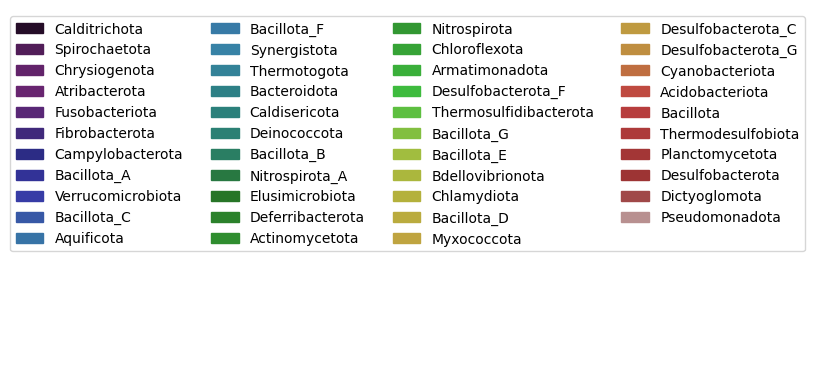

In [274]:
# make a phylum colormap
phyla = gtdb_md.loc[[l.name for l in gtdb_pruned.get_leaves()], 'gtdb_taxonomy'].apply(lambda x: x.split(';')[1]).unique()
np.random.shuffle(phyla)
phylum_cmap = dict((p.lstrip('p__'), mpl.colors.to_hex(sns.desaturate(c, 0.5))) for p, c in zip(phyla, sns.color_palette('nipy_spectral', n_colors=len(phyla))))

# and legend
handles = [mpl.patches.Patch(color=i, label=k) for k,i in phylum_cmap.items()]
plt.legend(handles=handles, ncol=4)
plt.axis('off')

In [275]:
leaf2phylum = gtdb_md.loc[[l.name for l in gtdb_pruned.get_leaves()], 'gtdb_taxonomy'].apply(lambda x: x.split(';')[1].lstrip('p_'))

In [276]:
def node_style(node):

    ns = NodeStyle()
    ns['size'] = 0

    if node.is_leaf():
        # Add a colored square (Face) and a Phylum label

        if node.name in corkrey_ids:
            color='k'
        else:
            color='white'
            
        faces.add_face_to_node(RectFace(150, 2, color, color), node, column=0, position="aligned")
        
        if node.name in corkrey_ids:
          color='white'  
        elif node.name in ogtfinder_temps.index:
            color='red'
        else:
            color='blue'

        # ns['size'] = 1
        faces.add_face_to_node(RectFace(150, 1, color, color), node, column=1, position="aligned")



    # l2p_nodeval = leaf2phylum.loc[[l.name for l in node.get_leaves()]].unique()
    # # print(len(l2p_nodeval))
    # if len(l2p_nodeval) == 1:
    #     ns['hz_line_color'] = phylum_cmap[l2p_nodeval[0]]
    #     ns['vt_line_color'] = phylum_cmap[l2p_nodeval[0]]
        # ns['size'] = 1
    #     ns['bgcolor'] = mpl.colors.to_hex(sns.desaturate(phylum_cmap[node.name.split('p__')[-1].split(';')[0]], 0.75))
    # if 'p__' in node.name:
    #     faces.add_face_to_node(TextFace(f"  {node.name.split('__')[-1]}", fgcolor='black', fsize=6), node, column=0, position="branch-right")

    node.img_style = ns
    
   
ts = TreeStyle()
ts.mode='c'
ts.show_leaf_name = False # Keep original leaf names
ts.layout_fn = node_style
ts.draw_guiding_lines = False




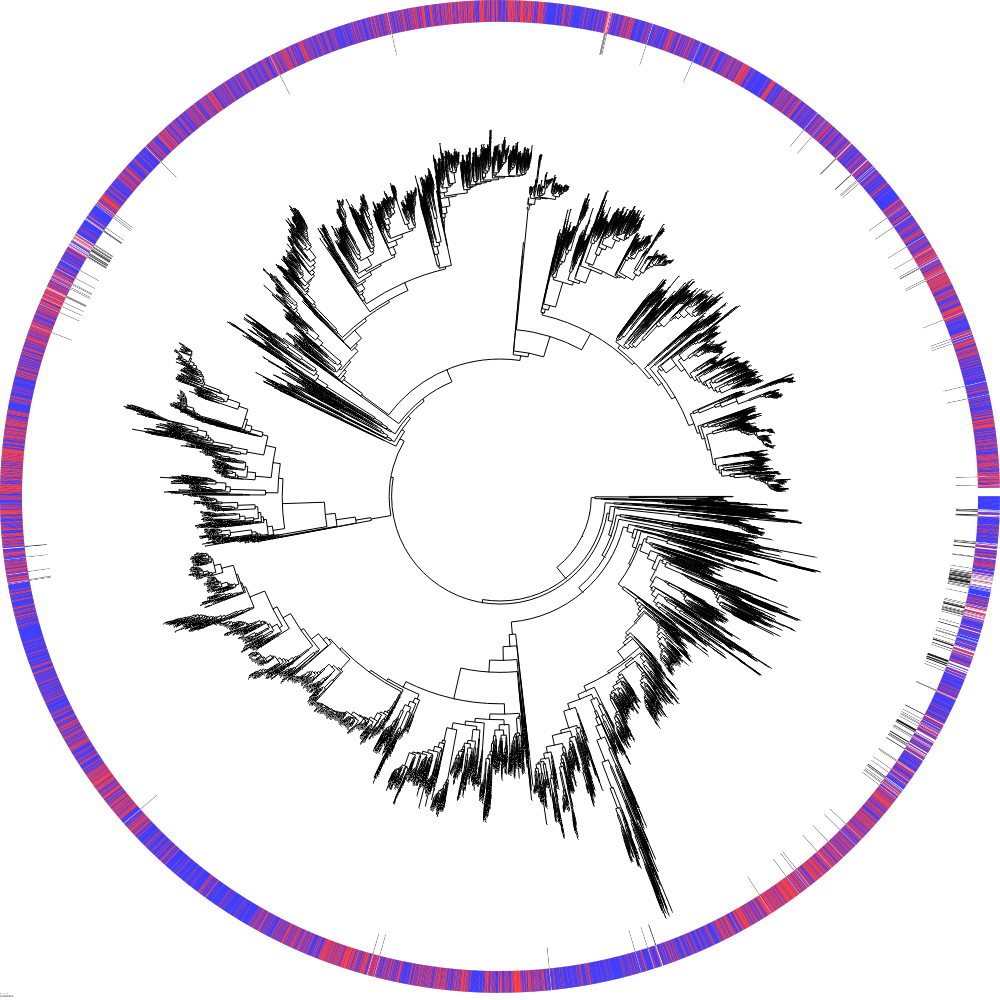

In [277]:
gtdb_pruned.render("%%inline", tree_style=ts, w=1000, h=1000) 

## Figure 2 panel B

In [78]:
from src.models.predict import run_model, per_site_predict
from src.models.utils import assess_model

# Code to run models: should be moved to /src

In [79]:
# def run_model(
#               embedding_loc : str, 
#               model_loc : str,
#               msa_loc : str,
#               predict_fn):

#     '''
#     embedding loc: location of pickled embeddings
#     model_loc: location of model to use
#     msa_loc: location of msa used to generate embeddings
#     predict_fn: function used to generate predictions
#     '''
#     loaded_model = reload_model(model_loc)
#     loaded_embeddings = reload_model(embedding_loc)
#     loaded_msa_dataset = reload_model(msa_loc)

#     assert loaded_model['metadata']['input_shape'][1:] == loaded_embeddings.shape[1:]
    
#     predictions = np.array(predict_fn(model=loaded_model['best_model'], 
#                              emb=loaded_embeddings,
#                              scalers=loaded_model['scalers'] if 'scalers' in loaded_model.keys() else None))
#     return predictions

# def per_site_predict(model, emb, scalers):

#     preds = []
#     for col in tqdm(model.keys()):
#         if scalers is not None:
#             site_emb = scalers[col].transform(emb[:, col, :])
#         else:
#             site_emb = emb[:, col, :]
            
#         preds.append(model[col].predict(site_emb))
    
#     return preds

    
    

# Mycobacteria figure

In [246]:
preds = run_model(embedding_loc='./../data/validation_datasets/Mycobacteria/embeddings/Mycobacteria_full_even.pickle',
         model_loc='./../data/predictive_models/even_enetcv_ind.pickle',
         msa_loc='./../data/validation_datasets/Mycobacteria/embeddings/Mycobacteria_msa_dataset.pickle',
         predict_fn=per_site_predict)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 215/215 [00:00<00:00, 1716.35it/s]


In [247]:
msa_dataset = reload_model('./../data/validation_datasets/Mycobacteria/embeddings/Mycobacteria_msa_dataset.pickle')
y_pred = pd.Series(data=unscale_ogts(preds.mean(axis=0), scaler),
                   index=[i[0] for i in msa_dataset])
y_pred.head()

NODE_5_length_244793_cov_26.942117|SRR32180441_215|SRR32180441_hmmsearch.tbl|XXXtemp=XXX|bitscore=187.1    30.705462
NODE_64_length_33264_cov_17.408426|SRR32180442_20|SRR32180442_hmmsearch.tbl|XXXtemp=XXX|bitscore=178.7     32.952156
NODE_8_length_214623_cov_14.510741|SRR32180443_23|SRR32180443_hmmsearch.tbl|XXXtemp=XXX|bitscore=185.9     37.488590
NODE_9_length_205973_cov_23.464231|SRR32180444_145|SRR32180444_hmmsearch.tbl|XXXtemp=XXX|bitscore=182.5    34.660988
NODE_14_length_238297_cov_7.920280|SRR32180445_180|SRR32180445_hmmsearch.tbl|XXXtemp=XXX|bitscore=178.3    33.668312
dtype: float32

In [248]:
true_temps = pd.read_csv('./../data/validation_datasets/Mycobacteria/md/Mycobacteria_env_temps.tsv', sep='\t')
y_true = true_temps.set_index('protein')['env temp']
y_true.head()

protein
NODE_5_length_244793_cov_26.942117|SRR32180441_215|SRR32180441_hmmsearch.tbl|XXXtemp=XXX|bitscore=187.1    31.6
NODE_64_length_33264_cov_17.408426|SRR32180442_20|SRR32180442_hmmsearch.tbl|XXXtemp=XXX|bitscore=178.7     38.2
NODE_8_length_214623_cov_14.510741|SRR32180443_23|SRR32180443_hmmsearch.tbl|XXXtemp=XXX|bitscore=185.9     37.4
NODE_9_length_205973_cov_23.464231|SRR32180444_145|SRR32180444_hmmsearch.tbl|XXXtemp=XXX|bitscore=182.5    32.8
NODE_14_length_238297_cov_7.920280|SRR32180445_180|SRR32180445_hmmsearch.tbl|XXXtemp=XXX|bitscore=178.3    32.0
Name: env temp, dtype: float64

In [249]:
# Comparison of our method to tomes
tomes_preds = pd.read_csv('./../data/validation_datasets/Mycobacteria/tome_predictions.tsv', sep='\t')
tomes_preds['genome'] = tomes_preds['FileName'].apply(lambda x: x.replace('_proteins.fasta',  '').replace('_consensus', ''))
tomes_plotdf = pd.merge(true_temps, tomes_preds, left_on='sample_or_genome', right_on='genome')
tomes_plotdf.head()

,Unnamed: 0,sample_or_genome,env temp,protein,FileName,predOGT (C),genome
0,0,SRR32180441,31.6,NODE_5_length_244793_cov_26.942117|SRR32180441...,SRR32180441_proteins.fasta,32.52,SRR32180441
1,1,SRR32180442,38.2,NODE_64_length_33264_cov_17.408426|SRR32180442...,SRR32180442_proteins.fasta,30.74,SRR32180442
2,2,SRR32180443,37.4,NODE_8_length_214623_cov_14.510741|SRR32180443...,SRR32180443_proteins.fasta,43.93,SRR32180443
3,3,SRR32180444,32.8,NODE_9_length_205973_cov_23.464231|SRR32180444...,SRR32180444_proteins.fasta,42.35,SRR32180444
4,4,SRR32180445,32.0,NODE_14_length_238297_cov_7.920280|SRR32180445...,SRR32180445_proteins.fasta,33.21,SRR32180445


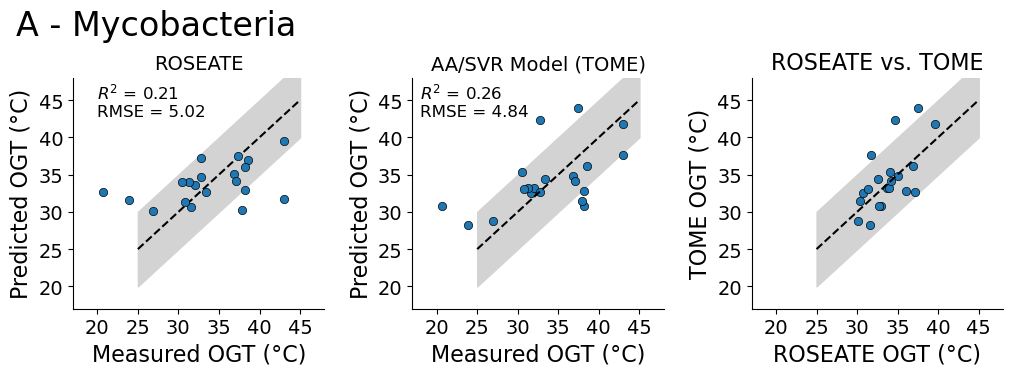

In [251]:
fig = plt.figure(figsize=(12, 3))

_lower, _upper = 17, 48

axes = []
for i in range(1,4):
    ax = fig.add_subplot(1,3,i)
    axes.append(ax)


# ----- ax 1
ax = axes[0]
sns.scatterplot(x=y_true, y=y_pred, zorder=2, 
                edgecolor='k', ax=ax)
assessment, (r2, rmse, spr) = assess_model(y_true, y_pred)
ax.set_title(f'ROSEATE', fontsize=14)

ax.annotate(f'$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}', 
            xy=(20, 45), va='center', fontsize=12)
title = ax.annotate('A - Mycobacteria', (10, 55), fontsize=24,
           annotation_clip=False, va='center')

# ----- ax 2
ax = axes[1]
sns.scatterplot(data=tomes_plotdf, y='predOGT (C)', x='env temp', 
                 edgecolor='k', ax=ax)
assessment, (r2, rmse, spr) = assess_model(tomes_plotdf['env temp'], tomes_plotdf['predOGT (C)'])
ax.set_title(f'AA/SVR Model (TOME)', fontsize=14)

ax.annotate(f'$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}', 
            xy=(18, 45), va='center', fontsize=12)

# ----- ax 3
ax = axes[2]
sns.scatterplot(x=y_pred, y=tomes_plotdf.set_index('protein')['predOGT (C)'],
               edgecolor='k', 
               # hue= (y_pred - y_true),
               # palette='PRGn'
               )
# lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_xlabel('ROSEATE OGT (°C)', fontsize=16)
ax.set_ylabel('TOME OGT (°C)', fontsize=16)
ax.set_title('ROSEATE vs. TOME', fontsize=16)

# formatting

for i, ax in enumerate(axes):
    ax.set_xlim(_lower, _upper)
    ax.set_ylim(_lower, _upper)
    ticks = list(range(20, 50, 5))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(labelsize=14, axis='both')
    line_lower, line_upper = 25, 45
    ax.plot((line_lower, line_upper), 
             (line_lower, line_upper), 
             'k--', label='x=y', zorder=1)
    
    ax.fill_between(np.linspace(line_lower, line_upper, 100), 
                     np.linspace(line_lower-5, line_upper-5, 100),
                    np.linspace(line_lower+5, line_upper+5, 100),
                    color='lightgray', zorder=0, label='+/- 5°C')

    if i < 2:
        ax.set_xlabel('Measured OGT (°C)', fontsize=16)
        ax.set_ylabel('Predicted OGT (°C)', fontsize=16)
    sns.despine()
    
fig.subplots_adjust(wspace=0.35)
plt.savefig('./../data/figures/finalized_figures/figure_2A.svg', bbox_inches='tight', bbox_extra_artists=(title,))
plt.savefig('./../data/figures/finalized_figures/figure_2A.png', bbox_inches='tight', bbox_extra_artists=(title,), dpi=400)

In [ ]:
# old code
# with open('./../data/validation_datasets/Mycobacteria/embeddings/Mycobacteria_mean_even.pickle', 'rb') as handle:
#     myco_embeddings = pickle.load(handle)

# # check
# loaded_model = reload_model('./../data/predictive_models/even_nn_means.pickle')
# y_pred = loaded_model['best_model'].predict(myco_embeddings)
# y_true = myco_temps
# fig, ax = plt.subplots(figsize=(4,4))
# sns.scatterplot(x=unscale_ogts(y_true, scaler), 
#                 y=unscale_ogts(y_pred, scaler))
# sns.despine()
# # plt.plot((25, 40), (25, 40))
# # ax.set_xlim(20, 47)
# # ax.set_ylim(20, 47)

## Embedding analysis

In [53]:
with open('./../data/validation_datasets/Mycobacteria/embeddings/Mycobacteria_full_even.pickle', 'rb') as handle:
    myco_full_embeddings = pickle.load(handle)

with open('./../data/validation_datasets/Mycobacteria/embeddings/Mycobacteria_full_tuned_even.pickle', 'rb') as handle:
    myco_full_tuned_embeddings = pickle.load(handle)

with open('./../data/validation_datasets/Mycobacteria/embeddings/Mycobacteria_temps.pickle', 'rb') as handle:
    myco_temps = pickle.load(handle)

(20, 20)


Text(0, 0.5, 'PCo2')

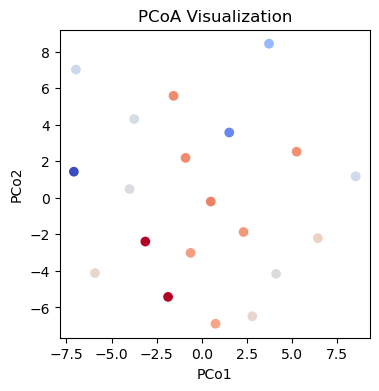

In [54]:
# PCoA
dists = scipy.spatial.distance_matrix(myco_full_embeddings[:, 50, :], 
                                      myco_full_embeddings[:, 50, :])
print(dists.shape)


# PCoA using MDS
mds = MDS(n_components=2, dissimilarity='precomputed')
coordinates = mds.fit_transform(dists)

plt.figure(figsize=(4, 4))
plt.scatter(coordinates[:, 0], coordinates[:, 1], c=myco_temps, cmap='coolwarm')
plt.title('PCoA Visualization')
plt.xlabel('PCo1')
plt.ylabel('PCo2')

In [66]:
tuned_mi = []
mi = []
for col in list(range(myco_full_embeddings.shape[1])):
    tuned_pca_comp = tuned_pca.transform(myco_full_tuned_embeddings[:, col, :])
    pca_comp = tuned_pca.transform(myco_full_embeddings[:, col, :])
    tuned_mi.append(calculate_morans_i(tuned_pca_comp[:, :2], myco_temps))
    mi.append(calculate_morans_i(pca_comp[:, :2], myco_temps))

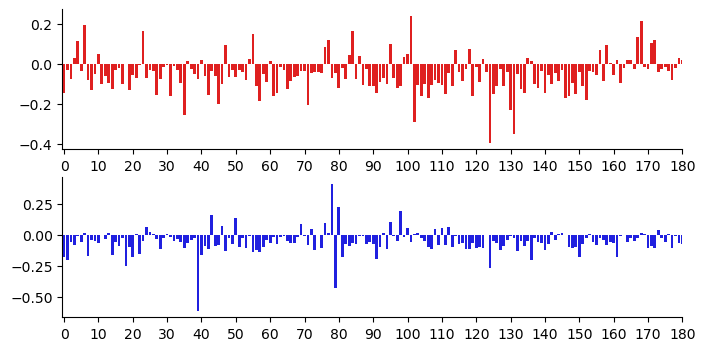

In [67]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(2, 1, 1)
sns.barplot(y=tuned_mi, x=list(range(len(tuned_mi))), color='r')
xticks = ax.set_xticks(list(range(0, len(mi), 10)))
sns.despine()

ax = fig.add_subplot(2, 1, 2, sharex=ax)
sns.barplot(y=mi, x=list(range(len(mi))), color='b')
xticks = ax.set_xticks(list(range(0, len(mi), 10)))
sns.despine()

In [68]:
print('Best site for tuned:', np.argmax(tuned_mi))
print('Best site for untuned:', np.argmax(mi))

Best site for tuned: 101
Best site for untuned: 78


In [69]:
np.argmax(tuned_mi)

101

In [70]:
tuned_mi[np.argmax(tuned_mi)], mi[np.argmax(mi)]

(0.2402474417263997, 0.41650621293439827)

Text(0, 0.5, 'PCA2')

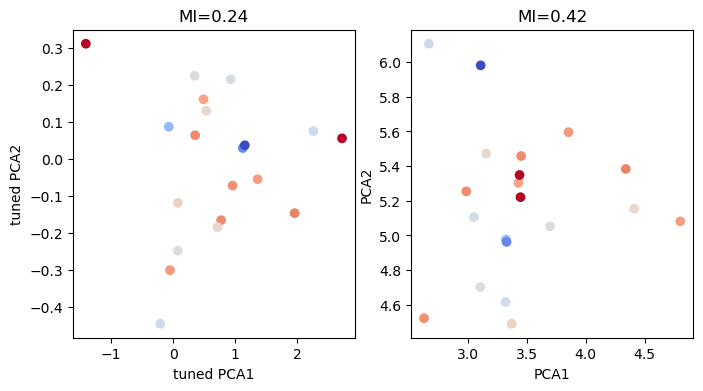

In [71]:
fig = plt.figure(figsize=(8, 4))

ax = fig.add_subplot(1, 2, 1)
pca_comp = tuned_pca.transform(myco_full_tuned_embeddings[:, np.argmax(tuned_mi), :])
plt.scatter(pca_comp[:, 0], pca_comp[:, 1], c=myco_temps, cmap='coolwarm')
_mi = calculate_morans_i(pca_comp[:, :2], myco_temps)
plt.title(f'MI={_mi:.2f}')
plt.xlabel('tuned PCA1')
plt.ylabel('tuned PCA2')

ax = fig.add_subplot(1, 2, 2)
pca_comp = tuned_pca.transform(myco_full_embeddings[:, 78, :])
plt.scatter(pca_comp[:, 0], pca_comp[:, 1], c=myco_temps, cmap='coolwarm')
_mi = calculate_morans_i(pca_comp[:, :2], myco_temps)
plt.title(f'MI={_mi:.2f}')
plt.xlabel('PCA1')
plt.ylabel('PCA2')

# Arthrobacter figure

In [252]:
# add a "isolate origin" column
arth_md = pd.read_csv('./../data/validation_datasets/Arthrobacter/md/2025_07_15-TOPT_Genomes.csv')
arth_md['genome'] = arth_md['Genome_ID'].apply(lambda x: x.replace('.fasta', '').replace('_consensus', ''))

# subset = pd.merge(subset, arth_md, left_on='sample_or_genome', right_on='genome', how='left')
arth_md.head()

,Group,Group2,Subproject,sample,EXP,Topt,Genome_ID,genome
0,Antarctica,Antarctic Isolate,Antarctica,70B,EXP10B,16,barcode29_consensus.fasta,barcode29
1,Antarctica,Antarctic Isolate,Antarctica,ASP_172-3(173-2),EXP10B,17,barcode36_consensus.fasta,barcode36
2,Antarctica,Antarctic Isolate,Antarctica,ASP_190-3,EXP13,18,barcode03_consensus.fasta,barcode03
3,Antarctica,Antarctic Isolate,Antarctica,ASP_192-5,EXP6,16,barcode38_consensus.fasta,barcode38
4,Antarctica,Antarctic Isolate,Antarctica,ASP_29-2,EXP13,17,barcode48_consensus.fasta,barcode48


In [253]:
preds = run_model(embedding_loc='./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_full_even.pickle',
         model_loc='./../data/predictive_models/even_enetcv_ind.pickle',
         msa_loc='./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_msa_dataset.pickle',
         predict_fn=per_site_predict)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 215/215 [00:00<00:00, 1410.07it/s]


In [254]:
msa_dataset = reload_model('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_msa_dataset.pickle')
y_pred = pd.Series(data=unscale_ogts(preds.mean(axis=0), scaler),
                   index=[i[0] for i in msa_dataset])
y_pred.head()

contig_4_579|8HZ65L_1_ASP410-2_hmmsearch.tbl|XXXtemp=XXX|bitscore=175.9       23.643995
contig_2_682|8HZ65L_3_24664_hmmsearch.tbl|XXXtemp=XXX|bitscore=170.5          22.311428
contig_1_351|barcode01_consensus_hmmsearch.tbl|XXXtemp=XXX|bitscore=176.1     24.919971
contig_1_2021|barcode02_consensus_hmmsearch.tbl|XXXtemp=XXX|bitscore=176.7    29.003691
contig_1_919|barcode03_consensus_hmmsearch.tbl|XXXtemp=XXX|bitscore=168.9     20.497478
dtype: float32

In [255]:
true_temps = pd.read_csv('./../data/validation_datasets/Arthrobacter/md/Arthrobacter_env_temps.tsv', sep='\t')
y_true = true_temps.set_index('protein')['env temp']
y_true.head()

protein
contig_1_3549|barcode29_consensus_hmmsearch.tbl|XXXtemp=XXX|bitscore=172.4    16
contig_1_813|barcode36_consensus_hmmsearch.tbl|XXXtemp=XXX|bitscore=170.7     17
contig_1_919|barcode03_consensus_hmmsearch.tbl|XXXtemp=XXX|bitscore=168.9     18
contig_1_678|barcode38_consensus_hmmsearch.tbl|XXXtemp=XXX|bitscore=169.6     16
contig_1_3312|barcode48_consensus_hmmsearch.tbl|XXXtemp=XXX|bitscore=170.7    17
Name: env temp, dtype: int64

In [256]:
# Comparison of our method to tomes
tomes_preds = pd.read_csv('./../data/validation_datasets/Arthrobacter/tome_predictions.tsv', sep='\t')
tomes_preds['genome'] = tomes_preds['FileName'].apply(lambda x: x.replace('_proteins.fasta',  '').replace('_consensus', ''))
tomes_plotdf = pd.merge(true_temps, tomes_preds, left_on='sample_or_genome', right_on='genome')
tomes_plotdf.head()

,Unnamed: 0,sample_or_genome,env temp,protein,FileName,predOGT (C),genome
0,0,barcode29,16,contig_1_3549|barcode29_consensus_hmmsearch.tb...,barcode29_consensus_proteins.fasta,24.88,barcode29
1,1,barcode36,17,contig_1_813|barcode36_consensus_hmmsearch.tbl...,barcode36_consensus_proteins.fasta,20.05,barcode36
2,2,barcode03,18,contig_1_919|barcode03_consensus_hmmsearch.tbl...,barcode03_consensus_proteins.fasta,20.35,barcode03
3,3,barcode38,16,contig_1_678|barcode38_consensus_hmmsearch.tbl...,barcode38_consensus_proteins.fasta,19.93,barcode38
4,4,barcode48,17,contig_1_3312|barcode48_consensus_hmmsearch.tb...,barcode48_consensus_proteins.fasta,20.06,barcode48


In [257]:
print(tomes_plotdf.shape)
tomes_plotdf = pd.merge(arth_md, tomes_plotdf, how='inner',
                        left_on='genome', right_on='genome')
print(tomes_plotdf.shape)

(48, 7)
(48, 14)


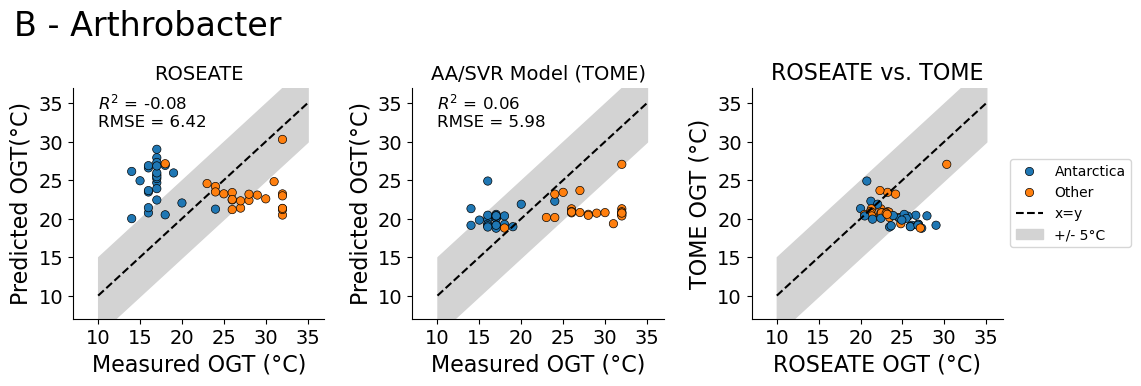

In [258]:
fig = plt.figure(figsize=(12, 3))



axes = []
for i in range(1,4):
    ax = fig.add_subplot(1,3,i)
    axes.append(ax)


# ----- ax 1
ax = axes[0]
sns.scatterplot(x=y_true, y=y_pred, zorder=2, 
                edgecolor='k', ax=ax, 
                hue=tomes_plotdf.set_index('protein')['Group'], 
                palette='tab10',
               hue_order=['Antarctica', 'Other'], legend=False)
assessment, (r2, rmse, spr) = assess_model(y_true, y_pred)
ax.set_title(f'ROSEATE', fontsize=14)

ax.annotate(f'$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}', 
            xy=(10, 34), va='center', fontsize=12)
title = ax.annotate('B - Arthrobacter', (0, 45), fontsize=24,
           annotation_clip=False, va='center')

# ----- ax 2
ax = axes[1]
sns.scatterplot(data=tomes_plotdf, y='predOGT (C)', x='env temp', 
                 edgecolor='k', ax=ax, 
                hue='Group', palette='tab10',
               hue_order=['Antarctica', 'Other'], legend=False)

assessment, (r2, rmse, spr) = assess_model(tomes_plotdf['env temp'], tomes_plotdf['predOGT (C)'])
ax.set_title(f'AA/SVR Model (TOME)', fontsize=14)

ax.annotate(f'$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}', 
            xy=(10, 34), va='center', fontsize=12)

# ----- ax 3
ax = axes[2]
sns.scatterplot(x=y_pred, y=tomes_plotdf.set_index('protein')['predOGT (C)'],
               edgecolor='k', 
                hue=tomes_plotdf.set_index('protein')['Group'],
                palette='tab10',
                hue_order=['Antarctica', 'Other']
               # hue= (y_pred - y_true),
               # palette='PRGn'
               )

ax.set_xlabel('ROSEATE OGT (°C)', fontsize=16)
ax.set_ylabel('TOME OGT (°C)', fontsize=16)
ax.set_title('ROSEATE vs. TOME', fontsize=16)

# formatting

_lower, _upper = 7, 37

for i, ax in enumerate(axes):
    ax.set_xlim(_lower, _upper)
    ax.set_ylim(_lower, _upper)
    ticks = list(range(10, 40, 5))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(labelsize=14, axis='both')
    line_lower, line_upper = 10, 35
    ax.plot((line_lower, line_upper), 
             (line_lower, line_upper), 
             'k--', label='x=y', zorder=1)
    
    ax.fill_between(np.linspace(line_lower, line_upper, 100), 
                     np.linspace(line_lower-5, line_upper-5, 100),
                    np.linspace(line_lower+5, line_upper+5, 100),
                    color='lightgray', zorder=0, label='+/- 5°C')

    if i < 2:
        ax.set_xlabel('Measured OGT (°C)', fontsize=16)
        ax.set_ylabel('Predicted OGT(°C)', fontsize=16)
    sns.despine()
    
ax = axes[2]
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    
fig.subplots_adjust(wspace=0.35)
plt.savefig('./../data/figures/finalized_figures/figure_2B.svg', bbox_inches='tight', bbox_extra_artists=(lgd,title))
plt.savefig('./../data/figures/finalized_figures/figure_2B.png', bbox_inches='tight', bbox_extra_artists=(lgd,title), dpi=400)

In [295]:
# which arthrobacter have worse predictions?
temp = pd.merge(arth_md, true_temps, left_on='genome', right_on='sample_or_genome')
temp.set_index(['sample'])['protein'].map((y_true - y_pred)).sort_values().head(15)

sample
ASP_410-4   -13.148745
ASP_293-2   -12.127052
ASP_414-1   -12.003691
ASP_414-5   -10.920359
ASP_402-3   -10.876421
ASP_418-1   -10.630671
ASP_290-4   -10.587749
ASP_412-1   -10.297287
ASP_412-2    -9.919971
ASP_404-1    -9.843258
D_22274      -9.128725
ASP_410-1    -8.944098
ASP_413-8    -8.914509
ASP_296-2    -8.663849
ASP_29-3     -8.444712
Name: protein, dtype: float64

In [291]:
even_species = genome2tax.loc[even_ids, 'species']
even_species[even_species.str.contains('Arthro')]

accession
RS_GCF_004803505.1           Arthrobacter_D echini
RS_GCF_016907875.1           Arthrobacter_J roseus
RS_GCF_009911795.1    Arthrobacter psychrotolerans
RS_GCF_900099975.1         Arthrobacter_G cupressi
Name: species, dtype: object

## Embedding analysis

In [1148]:
with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_full.pickle', 'rb') as handle:
    arth_full_embeddings = pickle.load(handle)

with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_full_tuned.pickle', 'rb') as handle:
    arth_full_tuned_embeddings = pickle.load(handle)

with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_temps.pickle', 'rb') as handle:
    arth_temps = pickle.load(handle)

In [1134]:
with open('./../data/predictive_models/tuned_pca.pickle', 'rb') as handle:
    tuned_pca = pickle.load(handle)

(53, 53)


Text(0, 0.5, 'PCo2')

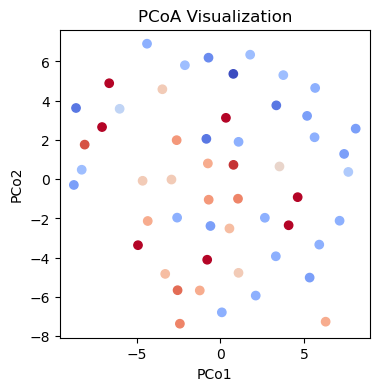

In [1147]:
# PCoA
dists = scipy.spatial.distance_matrix(arth_full_embeddings[:, 50, :], 
                                      arth_full_embeddings[:, 50, :])
print(dists.shape)


# PCoA using MDS
mds = MDS(n_components=2, dissimilarity='precomputed')
coordinates = mds.fit_transform(dists)

plt.figure(figsize=(4, 4))
plt.scatter(coordinates[:, 0], coordinates[:, 1], c=arth_temps, cmap='coolwarm')
plt.title('PCoA Visualization')
plt.xlabel('PCo1')
plt.ylabel('PCo2')

In [1544]:
tuned_mi = []
mi = []
for col in list(range(arth_full_embeddings.shape[1])):
    tuned_pca_comp = tuned_pca.transform(arth_full_tuned_embeddings[:, col, :])
    pca_comp = tuned_pca.transform(arth_full_embeddings[:, col, :])
    tuned_mi.append(calculate_morans_i(tuned_pca_comp[:, :2], arth_temps))
    mi.append(calculate_morans_i(pca_comp[:, :2], arth_temps))

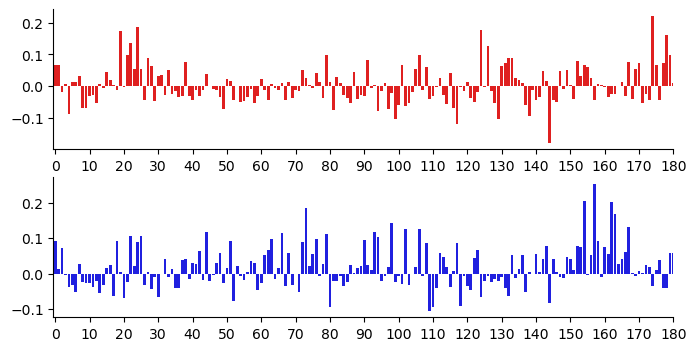

In [1545]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(2, 1, 1)
sns.barplot(y=tuned_mi, x=list(range(len(tuned_mi))), color='r')
xticks = ax.set_xticks(list(range(0, len(mi), 10)))
sns.despine()

ax = fig.add_subplot(2, 1, 2, sharex=ax)
sns.barplot(y=mi, x=list(range(len(mi))), color='b')
xticks = ax.set_xticks(list(range(0, len(mi), 10)))
sns.despine()

In [1546]:
print('Best site for tuned:', np.argmax(tuned_mi))
print('Best site for untuned:', np.argmax(mi))

Best site for tuned: 174
Best site for untuned: 157


Text(0, 0.5, 'tuned PCA2')

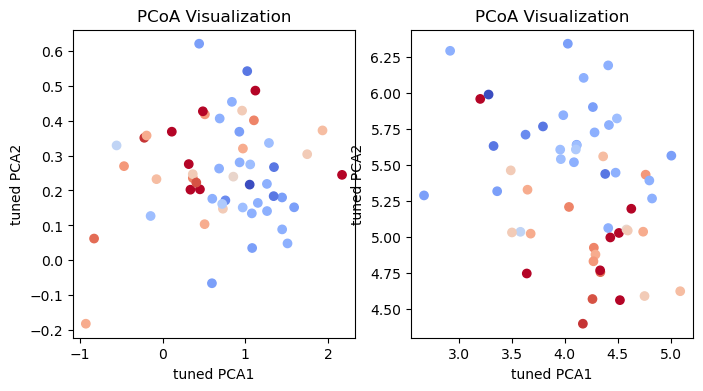

In [1547]:
fig = plt.figure(figsize=(8, 4))

ax = fig.add_subplot(1, 2, 1)
pca_comp = tuned_pca.transform(arth_full_tuned_embeddings[:, 174, :])
plt.scatter(pca_comp[:, 0], pca_comp[:, 1], c=arth_temps, cmap='coolwarm')
plt.title('PCoA Visualization')
plt.xlabel('tuned PCA1')
plt.ylabel('tuned PCA2')

ax = fig.add_subplot(1, 2, 2)
pca_comp = tuned_pca.transform(arth_full_embeddings[:, 157, :])
plt.scatter(pca_comp[:, 0], pca_comp[:, 1], c=arth_temps, cmap='coolwarm')
plt.title('PCoA Visualization')
plt.xlabel('tuned PCA1')
plt.ylabel('tuned PCA2')

In [1561]:
from sklearn.model_selection import train_test_split, cross_val_score

In [1565]:
yt.shape

(14, 5)

In [1575]:
xt,  xte, yt, yte = train_test_split(tuned_pca.transform(arth_full_embeddings[:, 157, :]), arth_temps)
svr = SVR()
svr.fit(xt, yt)

SVR()

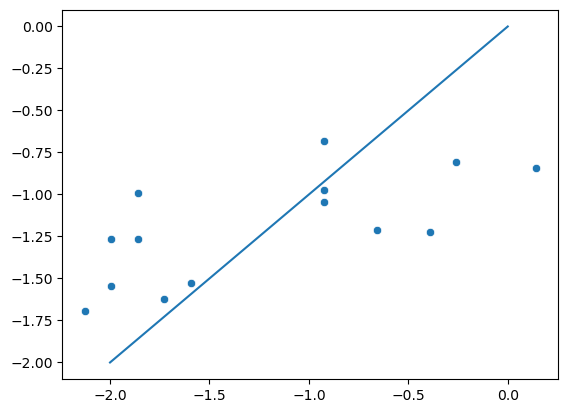

In [1576]:
sns.scatterplot(y=svr.predict(xte), x=yte)
plt.plot((-2, 0), (-2, 0))

In [1556]:
loaded_model = reload_model('./../data/predictive_models/corkrey_svr_ind_tuned_pca.pickle')

In [1552]:
good_cols = [i for i, _mi in enumerate(tuned_mi) if _mi > 0.1]

In [1553]:
good_cols

[19, 22, 24, 124, 126, 174, 178, 181]

<Axes: >

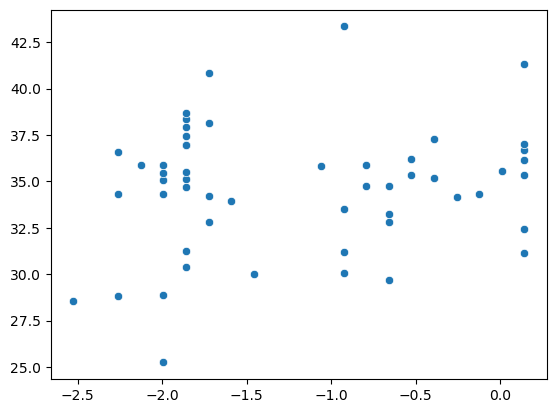

In [1560]:
sns.scatterplot(y=unscale_ogts(loaded_model['best_model'][157].predict(tuned_pca.transform(arth_full_tuned_embeddings[:, 157, :])), scaler),
                x=arth_temps)

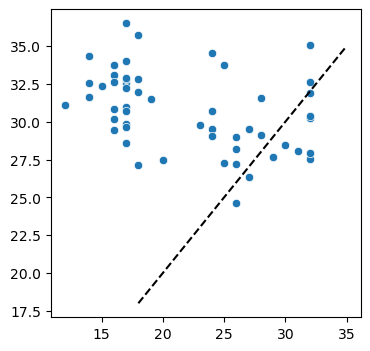

In [1557]:
extra_preds = np.array([loaded_model['best_model'][i].predict(tuned_pca.transform(arth_full_tuned_embeddings[:, i, :])) for i in good_cols]).mean(0)
fig, ax = plt.subplots(figsize=(4,4))

sns.scatterplot(y=unscale_ogts(extra_preds, scaler), 
                x=unscale_ogts(arth_temps, scaler))

plt.plot((18, 35), (18, 35), 'k--')

                

# What's the best model?

In [ ]:
# plots of model accuracies in training data

In [131]:
models = glob.glob('./../data/predictive_models/*.pickle')
for model in models:
    print(model)
    try: 
        loaded_model = reload_model(model)
    except AttributeError:
        print('failed')
    label = loaded_model['metadata']['label']
    if 'even_' in label:
        row_ind = 1
    else:
        row_ind = 0
    

./../data/predictive_models/corkrey_rf_means.pickle
corkrey_rf_means
./../data/predictive_models/even_rf_means.pickle
even_rf_means
./../data/predictive_models/corkrey_svr_means.pickle
corkrey_svr_means
./../data/predictive_models/even_svr_means.pickle
even_svr_means
./../data/predictive_models/corkrey_lm_means.pickle
corkrey_lm_means
./../data/predictive_models/even_lm_means.pickle
even_lm_means
./../data/predictive_models/even_nn_means.pickle


AttributeError: Can't get attribute 'MLPRegressor' on <module '__main__'>

In [127]:
loaded_model['metadata'].keys()

dict_keys(['type', 'input_shape', 'title', 'label'])

In [160]:
all_scores = [pd.read_csv(scores, sep='\t') for scores in glob.glob(f'./../data/validation_datasets/prediction_results/*_full_test_scores.tsv') if any(s in scores for s in['Arthro', 'Myco'])]
all_scores_plotdf = pd.concat(all_scores).reset_index(drop=True)
all_scores_plotdf.head()

,dataset,model_label,SpearmanR,MSE
0,Arthrobacter,corkrey_lm_ind,-0.049859,11.565650
1,Arthrobacter,corkrey_lm_ind_tuned_means,0.197853,7.847446
2,Arthrobacter,corkrey_lm_ind_tuned_pca,0.062243,6.595845
3,Arthrobacter,corkrey_lm_means,-0.236587,28.663765
4,Arthrobacter,corkrey_lm_tuned_means,-0.147263,21.042883


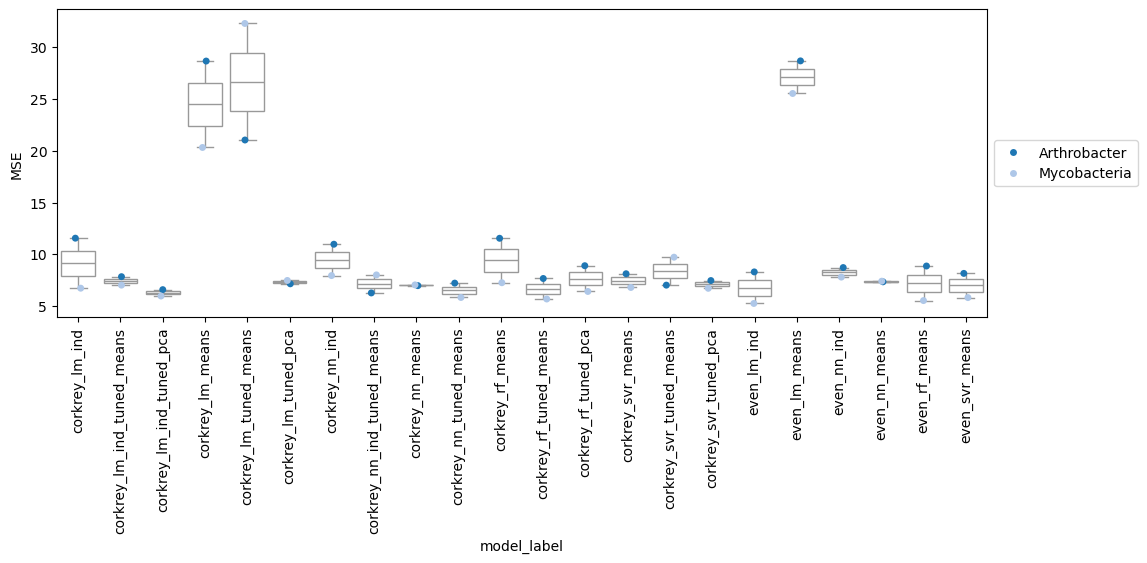

In [161]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.stripplot(data=all_scores_plotdf, x='model_label', y='MSE', hue='dataset', palette='tab20')
sns.boxplot(data=all_scores_plotdf, x='model_label', y='MSE', color='white', zorder=0)
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tick_params(rotation=90, axis='x')

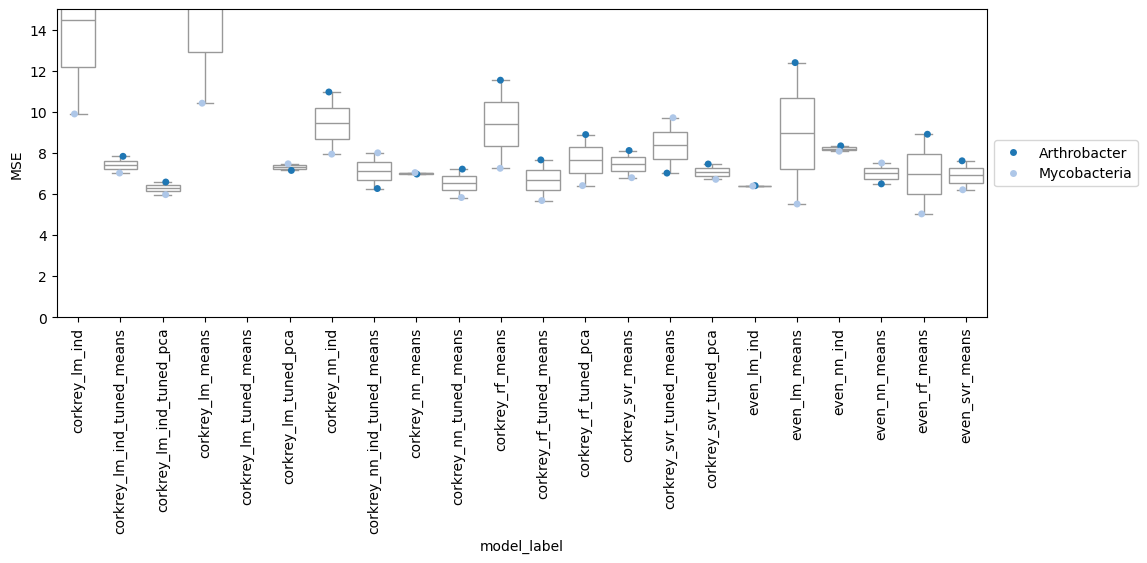

In [135]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.stripplot(data=all_scores_plotdf, x='model_label', y='MSE', hue='dataset', palette='tab20')
sns.boxplot(data=all_scores_plotdf, x='model_label', y='MSE', color='white', zorder=0)
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_ylim(0, 15)
plt.tick_params(rotation=90, axis='x')

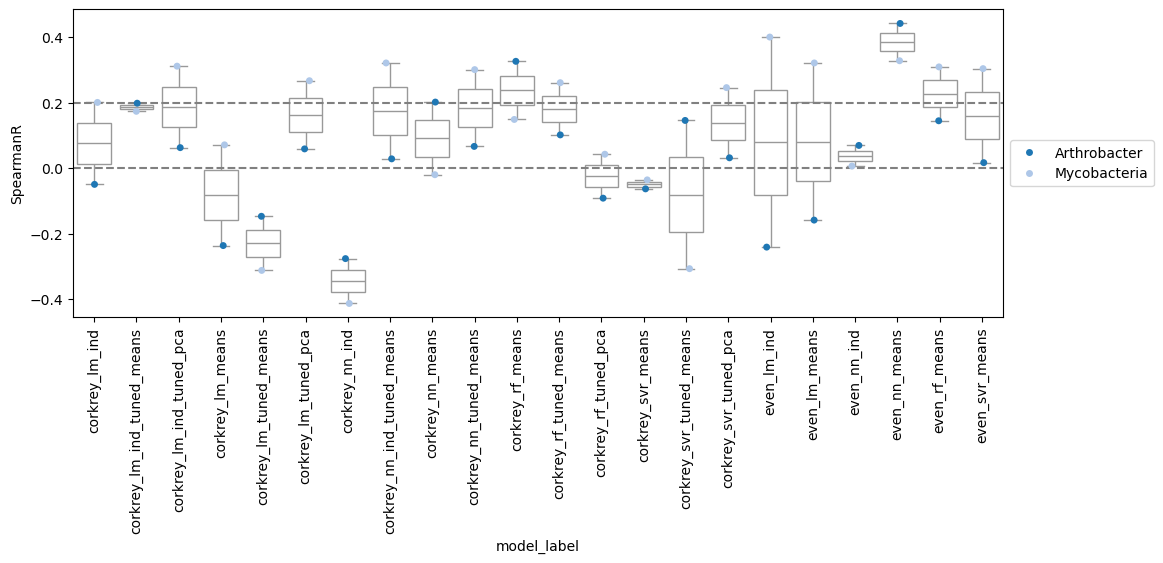

In [168]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.stripplot(data=all_scores_plotdf, x='model_label', y='SpearmanR', hue='dataset', palette='tab20')
sns.boxplot(data=all_scores_plotdf, x='model_label', y='SpearmanR', color='white', zorder=0)
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
# ax.set_ylim(0, 15)
plt.tick_params(rotation=90, axis='x')
ax.axhline(0.2, color='gray', zorder=0, linestyle='--')
ax.axhline(0, color='gray', zorder=0, linestyle='--')

In [82]:
best_models = ['corkrey_lm_ind_tuned_means', 
               'corkrey_nn_ind', 'corkrey_rf_means',
               'even_nn_means', 'even_rf_means', 'even_svr_means', 'even_lm_ind', 'even_nn_means']

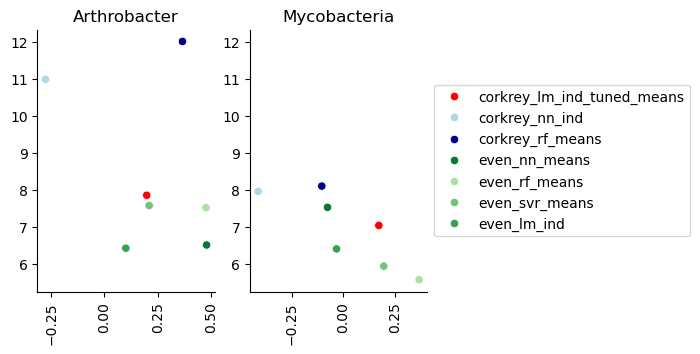

In [85]:
fig = plt.figure(figsize=(16, 8))
i = 1
axes = []
for dataset in all_scores_plotdf.dataset.unique():
    if i == 1:
        ax = fig.add_subplot(2, 6, i)
        axes.append(ax)
    else:
        ax = fig.add_subplot(2, 6, i, sharey=axes[0])
        axes.append(ax)

    sns.scatterplot(data=all_scores_plotdf[all_scores_plotdf['dataset'].eq(dataset) & all_scores_plotdf.model_label.isin(best_models)], x='SpearmanR', y='MSE', 
                    hue='model_label', palette=['r', 'lightblue', 'darkblue']+list(sns.color_palette('Greens', 5)), hue_order=best_models)
    # sns.boxplot(data=all_scores_plotdf, x='model_label', y='MSE', color='white', zorder=0)
    
    if i == len(all_scores_plotdf.dataset.unique()):
        lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    else:
        if ax.get_legend() is not None:
            ax.get_legend().remove()
    ax.set_title(dataset)
    ax.set_xlabel('')
    ax.set_ylabel('')
    # ax.set_xlim(0, 0.5)
    # ax.set_ylim(0, 20)
    plt.tick_params(rotation=90, axis='x')
    sns.despine()
    i += 1
fig.subplots_adjust(hspace=0.35)

In [86]:
spearman_ranks = all_scores_plotdf[all_scores_plotdf.model_label.isin(best_models)].set_index(['dataset', 'model_label'])['SpearmanR'].unstack().T.rank(ascending=False)
mse_ranks = all_scores_plotdf[all_scores_plotdf.model_label.isin(best_models)].set_index(['dataset', 'model_label'])['MSE'].unstack().T.rank(ascending=True)

In [87]:
all_scores_plotdf[all_scores_plotdf.model_label.isin(best_models)].set_index(['dataset', 'model_label'])['SpearmanR'].unstack().T.rank(ascending=False)

dataset,Arthrobacter,Mycobacteria
model_label,,
corkrey_lm_ind_tuned_means,5.0,3.0
corkrey_nn_ind,7.0,7.0
corkrey_rf_means,3.0,6.0
even_lm_ind,6.0,4.0
even_nn_means,1.0,5.0
even_rf_means,2.0,1.0
even_svr_means,4.0,2.0


<Axes: xlabel='dataset', ylabel='model_label'>

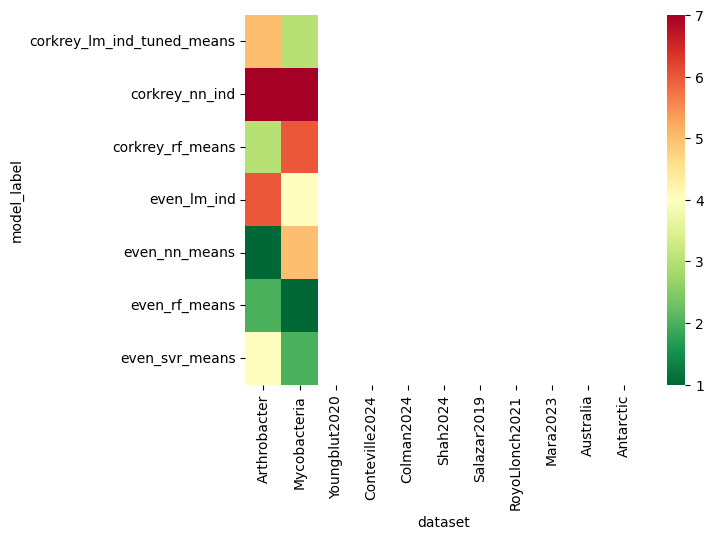

In [88]:
new_order = ['Arthrobacter', 'Mycobacteria', 'Youngblut2020', 'Conteville2024', 'Colman2024', 
 'Shah2024', 'Salazar2019', 'RoyoLlonch2021', 'Mara2023', 'Australia', 'Antarctic' ]
sns.heatmap(spearman_ranks.reindex(columns=new_order), cmap='RdYlGn_r')

<Axes: xlabel='dataset', ylabel='model_label'>

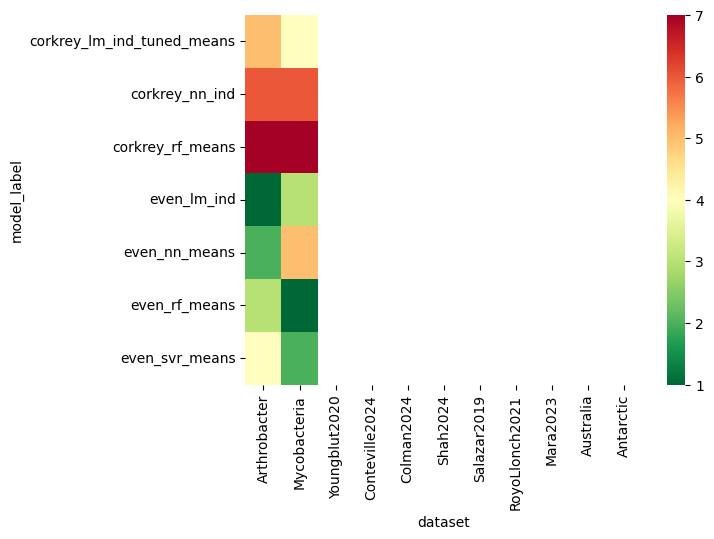

In [89]:
new_order = ['Arthrobacter', 'Mycobacteria', 'Youngblut2020', 'Conteville2024', 'Colman2024', 
 'Shah2024', 'Salazar2019', 'RoyoLlonch2021', 'Mara2023', 'Australia', 'Antarctic' ]
sns.heatmap(mse_ranks.reindex(columns=new_order), cmap='RdYlGn_r')

# Importance of particular sites (Figure 8)

In [311]:
per_res_data = pd.read_csv('./../data/metric_tables/20251012_per_residue_data.tsv.gz',
             sep='\t', compression='gzip', index_col=[0,1])

In [312]:
col_rs = pd.read_csv('./../data/predictive_models/supporting_data/even_enetcv_ind_spearmans.tsv', sep='\t').rename(columns={'Unnamed: 0':'loc', '0':'SpearmanR'})

col_rs.head()

,loc,SpearmanR
0,0,0.873344
1,1,0.852110
2,2,0.835021
3,3,0.848443
4,4,0.827654


In [345]:
# aggegrate per res data, mean for numerics, mode for objects (categories)

type2func = {'object':pd.Series.mode, 'float64':'mean'}
col2agg = dict((col,type2func[str(per_res_data[col].dtype)]) for col in per_res_data.columns)
grouped = per_res_data.groupby('aln_res').agg(col2agg)

# Map secondary structure to colors
ss_color_map = {'H': '#d7191c',  # Helix - red
                'E': '#2c7bb6',  # Sheet - blue
                'C': '#fdae61',
                'L':'gray'}  # Coil/other - orange

grouped['ss_color'] = grouped['secondary_structure'].fillna('L').map(ss_color_map)

grouped.head()

,resname,sasa,delta_sasa,normalized_delta_sasa,fa_sol,fa_atr,fa_elec,secondary_structure,contacts_at_4.5,aln_res,ss_color
aln_res,,,,,,,,,,,
0.0,MET,58.133135,156.929681,0.734529,2.715504,-6.165960,-3.064958,L,11.294717,0.0,gray
1.0,ARG,33.055434,206.917434,0.874035,5.846805,-8.296620,-3.972916,E,13.804322,1.0,#2c7bb6
2.0,LEU,0.271003,197.212917,0.998682,1.451245,-8.172922,-2.524830,E,15.781705,2.0,#2c7bb6
3.0,ILE,0.335021,189.469742,0.998253,1.380892,-8.232019,-2.042698,E,14.692840,3.0,#2c7bb6
4.0,LEU,2.419798,201.310940,0.988122,1.141256,-7.464156,-1.523013,E,15.991904,4.0,#2c7bb6


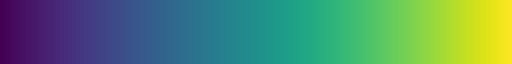

In [524]:
cmap = sns.color_palette('viridis', as_cmap=True)


In [534]:
# code to color protein by importance
idx = pd.IndexSlice
stat = 'SpearmanR'
norm = mpl.colors.Normalize(col_rs[stat].min(), col_rs[stat].max())
cmap.set_bad(color='lightgray')

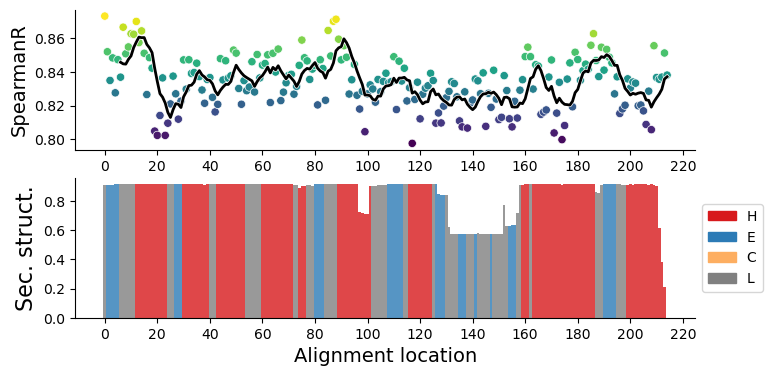

In [605]:
fig = plt.figure(figsize=(8, 4))
gs = fig.add_gridspec(2, 1, height_ratios=[1,1])

# plot 1
# --------------------------------------------
ax = fig.add_subplot(gs[0])
sns.scatterplot(data=col_rs.reset_index(),
               x='loc', y='SpearmanR', 
                palette='viridis', hue='SpearmanR', legend=False)

window_size = 7
moving_average = col_rs['SpearmanR'].rolling(window=window_size).mean()

sns.lineplot(data=col_rs.reset_index(),
               x='loc', y=moving_average, color='w', linewidth=3)

sns.lineplot(data=col_rs.reset_index(),
               x='loc', y=moving_average, color='k', linewidth=2)



ax.set_ylabel('SpearmanR', fontsize=14)

sns.despine()

# for col in col_rs.sort_values('SpearmanR', ascending=False).head(10).index:
#     ax.axvline(col, color='gray', zorder=0)

ax.set_xticks(list(range(0, 240, 20)))

# plot 2
# --------------------------------------------
ax = fig.add_subplot(gs[1], sharex=ax)
ax.bar(grouped['aln_res'], (per_res_data['aln_res'].value_counts() / len(per_res_data.index.get_level_values(0).unique())).sort_index(),
       color=grouped['ss_color'], width=1, alpha=0.8, zorder=1)
ax.set_ylabel('Sec. struct.', fontsize=16)
handles = [mpl.patches.Patch(color=v, label=k) for k,v in ss_color_map.items()]
lgd = ax.legend(handles=handles, # labels=list(ss_color_map.keys()),
                loc='center left', 
                bbox_to_anchor=(1, 0.5))
# # plot 3 
# # --------------------------------------------
# ax = fig.add_subplot(gs[2], sharex=ax)

# window_size = 7
# moving_average = grouped['normalized_delta_sasa'].rolling(window=window_size).mean()

# sns.lineplot(data=grouped,
#                x='aln_res', y=moving_average)
# ax.set_xlabel('Alignment location', fontsize=14)
# ax.set_ylabel('Delta SASA', fontsize=14)

# sns.despine()
ax.set_xlabel('Alignment location', fontsize=14)
sns.despine()
# for col in col_rs.sort_values('SpearmanR', ascending=False).head(10).index:
#     ax.axvline(col, color='gray', zorder=0)

plt.savefig('./../data/figures/finalized_figures/Figure3_model_vs_structure.svg', bbox_inches='tight', bbox_extra_artists=(lgd, ))

In [547]:
importance_plotdf = pd.merge(grouped, col_rs, left_index=True, right_index=True)
importance_plotdf.head()

,resname,sasa,delta_sasa,normalized_delta_sasa,fa_sol,fa_atr,fa_elec,secondary_structure,contacts_at_4.5,aln_res,ss_color,loc,SpearmanR
0.0,MET,58.133135,156.929681,0.734529,2.715504,-6.165960,-3.064958,L,11.294717,0.0,gray,0,0.873344
1.0,ARG,33.055434,206.917434,0.874035,5.846805,-8.296620,-3.972916,E,13.804322,1.0,#2c7bb6,1,0.852110
2.0,LEU,0.271003,197.212917,0.998682,1.451245,-8.172922,-2.524830,E,15.781705,2.0,#2c7bb6,2,0.835021
3.0,ILE,0.335021,189.469742,0.998253,1.380892,-8.232019,-2.042698,E,14.692840,3.0,#2c7bb6,3,0.848443
4.0,LEU,2.419798,201.310940,0.988122,1.141256,-7.464156,-1.523013,E,15.991904,4.0,#2c7bb6,4,0.827654


In [559]:
def classify_domain(loc):
    if loc < 31 or loc > 158:
        return "Core"
   
    if loc < 77:
        return "NMP"

    if loc > 117:
        return "Lid"

    return "Core"

        
importance_plotdf['domain'] = importance_plotdf['loc'].apply(lambda x: classify_domain(x))

<Axes: xlabel='loc', ylabel='SpearmanR'>

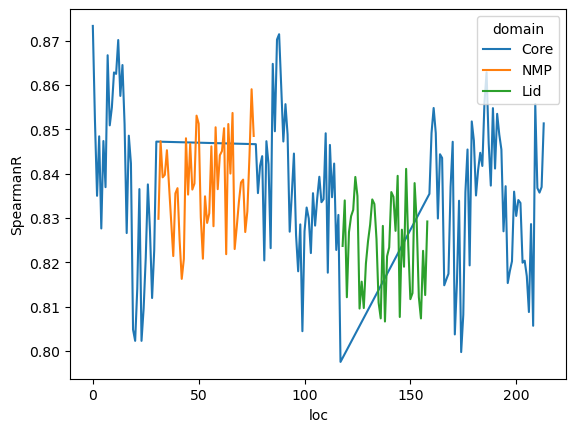

In [560]:
sns.lineplot(importance_plotdf, x='loc', y='SpearmanR', hue='domain')

#### Notes
Could do correlation of negatively associated components with negatively associated features across the length of the protein.

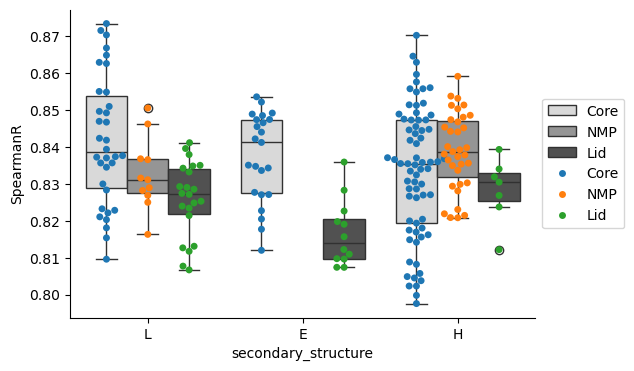

In [602]:
fig, ax = plt.subplots(figsize=(6,4))
sns.boxplot(data=importance_plotdf, x='secondary_structure', y='SpearmanR', hue='domain', palette='Grays')
sns.swarmplot(data=importance_plotdf, x='secondary_structure', y='SpearmanR', hue='domain', palette='tab10', dodge=True)
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
# ax.set_ylim(0.8, 0.9)


In [574]:
subset = importance_plotdf[importance_plotdf.domain.eq('Core') & importance_plotdf['secondary_structure'].eq('H')]

<Axes: xlabel='SpearmanR', ylabel='Count'>

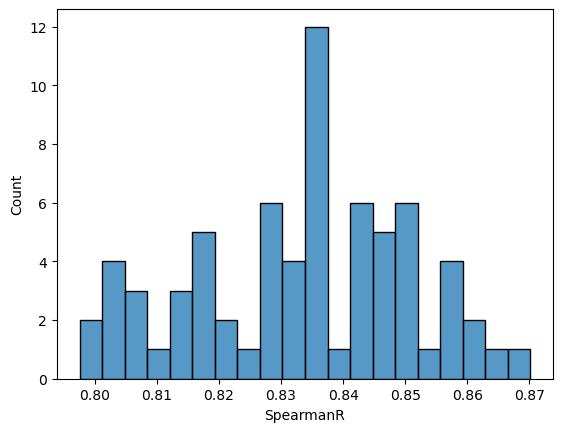

In [584]:
sns.histplot(data=subset,
                x='SpearmanR', bins=20)

<Axes: xlabel='resname', ylabel='SpearmanR'>

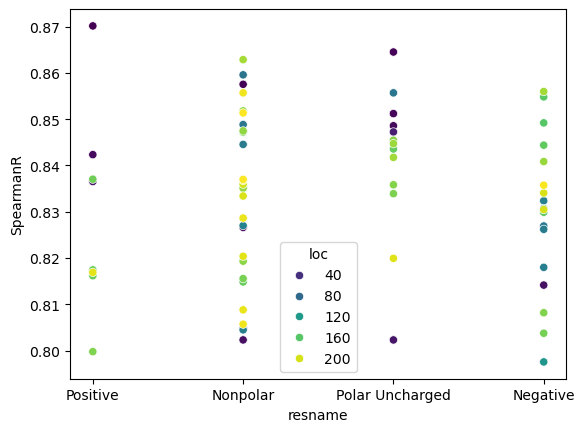

In [607]:
residue_to_class = {
    # Nonpolar (Hydrophobic)
    "ALA": "Nonpolar", "VAL": "Nonpolar", "LEU": "Nonpolar", 
    "ILE": "Nonpolar", "MET": "Nonpolar", "PHE": "Nonpolar", 
    "TRP": "Nonpolar", "PRO": "Nonpolar", "GLY": "Nonpolar",

    # Polar Uncharged
    "SER": "Polar Uncharged", "THR": "Polar Uncharged", "CYS": "Polar Uncharged", 
    "TYR": "Polar Uncharged", "ASN": "Polar Uncharged", "GLN": "Polar Uncharged",

    # Positively Charged (Basic)
    "LYS": "Positive", "ARG": "Positive", "HIS": "Positive",

    # Negatively Charged (Acidic)
    "ASP": "Negative", "GLU": "Negative"
}

sns.scatterplot(data=subset,
                x=subset['resname'].map(residue_to_class), y='SpearmanR',
               hue='loc', palette='viridis')

<Axes: xlabel='secondary_structure', ylabel='SpearmanR'>

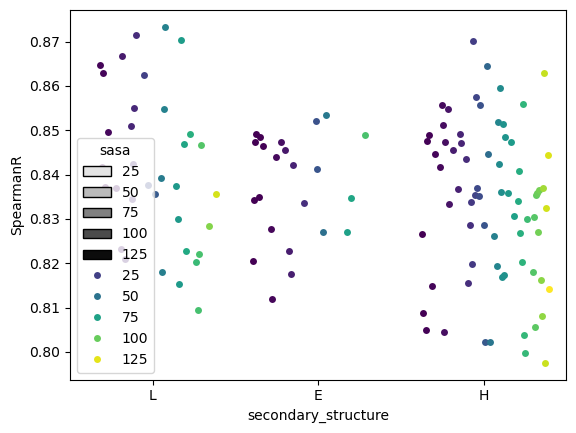

In [572]:
sns.boxplot(data=importance_plotdf[importance_plotdf.domain.eq('Core')], 
            x='secondary_structure', y='SpearmanR', 
            hue='sasa', palette='Grays')
sns.swarmplot(data=importance_plotdf[importance_plotdf.domain.eq('Core')], 
              x='secondary_structure', y='SpearmanR', 
              hue='sasa', palette='viridis', dodge=True, legend=False)


In [624]:

from Bio.PDB import PDBParser, Selection, Polypeptide
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio import SeqIO
from scipy.spatial.distance import cdist

def get_center_of_mass(atoms):
    coords = np.array([atom.get_coord() for atom in atoms])
    return np.mean(coords, axis=0)

# 1. Parse Structure
parser = PDBParser(QUIET=True)
structure = parser.get_structure("1ake", "./../data/pdb/1ake.pdb")
model = structure[0]

# 2. Extract specific Ligand (AP5) Atoms
target_atom_names = ['P1', 'P2', 'P3', 'P4', 'P5'] # Example: Phosphorus backbone

ligand_res = [res for res in Selection.unfold_entities(model, 'R') if res.get_resname() == 'AP5']

# Filter atoms by name
ligand_atoms = [
    a for a in Selection.unfold_entities(ligand_res, 'A') 
    if 'P' in a.get_name() #in target_atom_names
]

# Re-calculate coordinates and Center of Mass for the specific atom subset
ligand_coords = np.array([a.get_coord() for a in ligand_atoms])
ligand_com = get_center_of_mass(ligand_atoms)

# 3. Process Residues
data = []
protein_residues = []

for residue in model.get_residues():
    # Only process standard protein residues
    if Polypeptide.is_aa(residue, standard=True):
        res_id = f"{residue.get_resname()}{residue.id[1]}"
        protein_residues.append(residue)
        
        # --- Center of Mass Heuristic ---
        side_chain = [a for a in residue.get_atoms() if a.get_name() not in ['N', 'CA', 'C', 'O']]
        if not side_chain: side_chain = [residue['CA']] # For Glycine
        res_com = get_center_of_mass(side_chain)
        com_dist = np.linalg.norm(res_com - ligand_com)
        
        # --- Minimum Atom-to-Atom Distance ---
        res_coords = np.array([a.get_coord() for a in residue.get_atoms()])
        # Compute distance between every residue atom and every ligand atom
        dist_matrix = cdist(res_coords, ligand_coords)
        min_dist = np.min(dist_matrix)
        
        data.append({
            "Residue": res_id,
            "Res_Num": residue.id[1],
            "CoM_Dist": com_dist,
            "Min_Dist": min_dist
        })

# 4. Create DataFrame
df = pd.DataFrame(data)
df.to_csv("./../data/pdb/1ake_distances.csv", index=False)
print("DataFrame created and saved to '1ake_distances.csv'.")
print(df.head(10))

# 5. Extract Sequence and Save to FASTA
ppb = Polypeptide.PPBuilder()
seq_list = []
for i, pp in enumerate(ppb.build_peptides(model)):
    sequence = pp.get_sequence()
    record = SeqRecord(sequence, id=f"1ake_chain_{i}", description="Adenylate Kinase Chain")
    seq_list.append(record)

SeqIO.write(seq_list, "./../data/pdb/1ake_sequence.fasta", "fasta")
print("\nSequence written to '1ake_sequence.fasta'.")

DataFrame created and saved to '1ake_distances.csv'.
  Residue  Res_Num   CoM_Dist   Min_Dist
0    MET1        1  34.309505  18.642498
1    ARG2        2  33.664589  17.490634
2    ILE3        3  29.348606  13.594586
3    ILE4        4  23.895002  11.749255
4    LEU5        5  24.504070   7.915883
5    LEU6        6  18.482988   8.467976
6    GLY7        7  16.486103   6.697921
7    ALA8        8  13.032182   5.120459
8    PRO9        9  13.555841   4.481334
9   GLY10       10  18.253096   3.831766

Sequence written to '1ake_sequence.fasta'.


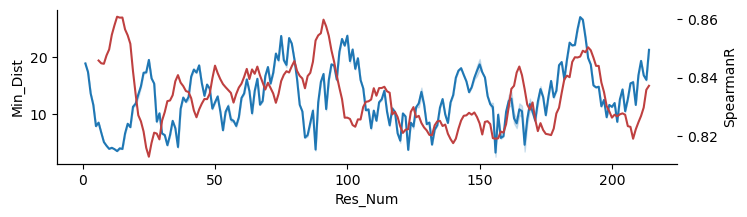

In [1167]:
fig, ax = plt.subplots(figsize=(8,2))
sns.lineplot(data=df,
             x='Res_Num',
             #y=df['Min_Dist'].max() - df['Min_Dist'])
             y=df['Min_Dist'])
tax = ax.twinx()
sns.lineplot(data=col_rs.reset_index(),
               x='loc', y=moving_average, color=sns.desaturate('r', 0.5), zorder=3, ax=tax)
sns.despine()

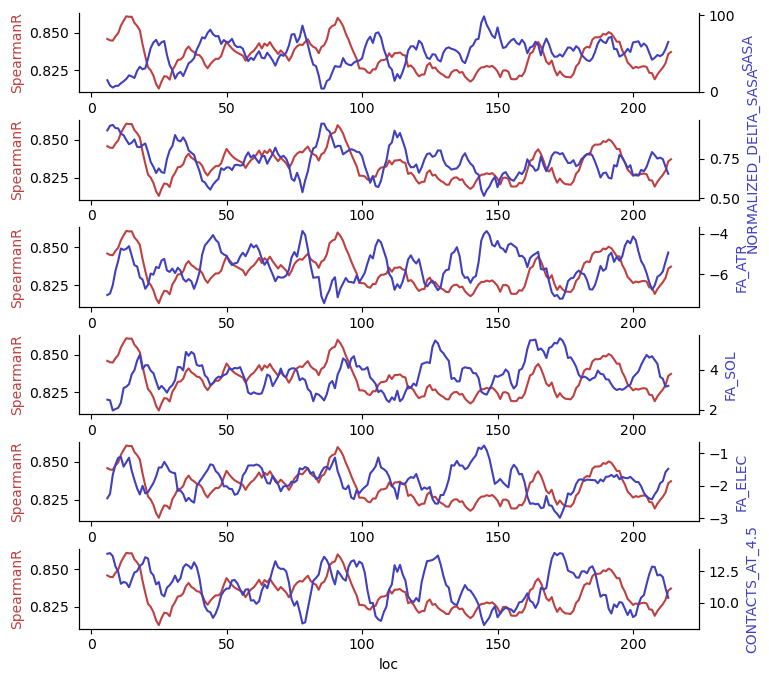

In [368]:


fig = plt.figure(figsize=(8,8))
window_size = 7
cols = ['sasa', 'normalized_delta_sasa', 'fa_atr', 'fa_sol', 'fa_elec', 'contacts_at_4.5']
for i, right_col in enumerate(cols):
    # sns.scatterplot(x=col_rs.index, y=col_rs['SpearmanR'], color='salmon', zorder=0)
    
    ax = fig.add_subplot(len(cols), 1, i+1)
    moving_average = col_rs['SpearmanR'].rolling(window=window_size).mean()
    
    sns.lineplot(data=col_rs.reset_index(),
                   x='loc', y=moving_average, color=sns.desaturate('r', 0.5), zorder=3, ax=ax)
    ax.set_ylabel('SpearmanR', color=sns.desaturate('r', 0.5),)
    
    tax = ax.twinx()
    # sns.scatterplot(x=grouped.index, y=grouped[right_col], 
    #                 ax=tax, zorder=0,
    #                linewidth=0, color='aliceblue')
    
    moving_average = grouped[right_col].rolling(window=window_size).mean()
    sns.lineplot(data=grouped, color=sns.desaturate('b', 0.5),
                   x='aln_res', y=moving_average, zorder=2)
    tax.set_ylabel(right_col.upper(), color=sns.desaturate('b', 0.5),)
    sns.despine(right=False)
fig.subplots_adjust(hspace=0.35)

<Axes: xlabel='SpearmanR', ylabel='None'>

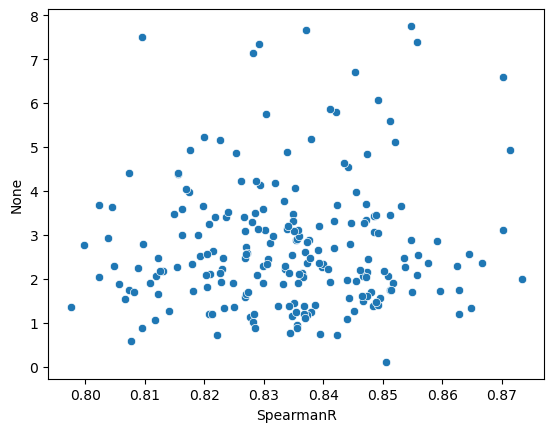

In [370]:
sns.scatterplot(x=col_rs['SpearmanR'], y=grouped['normalized_delta_sasa'] * grouped['fa_sol'])

In [373]:
from matplotlib.colors import to_hex

In [374]:
from __future__ import print_function
import warnings
warnings.filterwarnings('ignore') # make the notebook nicer


# import os
# os.environ['QT_QPA_PLATFORM']='offscreen'

import nglview as nv
import pytraj as pt

print("nglview version = {}".format(nv.__version__))
print("pytraj version = {}".format(pt.__version__))

from Bio.PDB import PDBParser, Select, PDBIO, Polypeptide
from Bio.SeqUtils import seq1

nglview version = 3.1.1
pytraj version = 2.0.6


In [375]:
import sys

In [376]:
sys.path.append('/data/mhoffert/fiererlab/adenylate_kinase_ogt/')

In [377]:
from src.protein_utils.adk_drawer import get_guiding_structures, ss_to_domains, draw_adk, compute_domains, nw

In [378]:
nglview_list = lambda cmap, residue_vals: [[to_hex(cmap[r]), str(i)] if isinstance(cmap, dict) else [to_hex(cmap(r)), str(i)] for i, r in enumerate(residue_vals)]

In [523]:
def color_protein_by_importance(pdb, site2val, cmap_val2color, label):
    '''
    pdb (str) : a pdb file
    site2val (pd.Series) a Series mapping sites (index) to values for coloring (values)
    cmap_val2color: a dict mapping values from site2val to hex colors
    OR
    a colormap instance (in which case site2val should be scaled with mpl.colors.Normalize)
    '''
    
    # load pdb
    traj = pt.load(pdb)
    w = nv.show_pytraj(traj, default_representation=False)
    # w.add_cartoon(color='gray')
    
    colors = nglview_list(cmap_val2color, list(site2val.values))
    print(colors[:5])
    scheme = nv.color._ColorScheme(colors, label=label)
    
    w.add_cartoon(color=scheme, selection='not 118-158')
    
    w.center()
    
    return w

In [380]:
# # original example code
# seq = ''.join(list(trim_aln_df.loc['RS_GCF_003550175.1', :].values))
# n_subs = bcs.groupby('site').count()['to'].reindex(list(range(len(seq)))).fillna(0).astype(int)

pdb = './../data/processed_structures/RS_GCF_003550175.1_A_processed.pdb'
# convergence_cmap = dict((c, to_hex(_color)) for c, _color in zip(range(1, n_subs.max()+1), 
#                                                                  # ['red'] * int(bcs.groupby('site').count()['to'].max()+1)))
#                                                           sns.color_palette('inferno', n_colors=bcs.groupby('site').count()['to'].max()+1)))
# convergence_cmap[0] = 'lightgray'

# color_protein_by_importance(pdb, n_subs, convergence_cmap, 'blah')

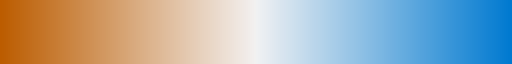

In [381]:
cmap = sns.diverging_palette(30, 250, s=100, l=50, sep=1, center="light", as_cmap=True)
cmap

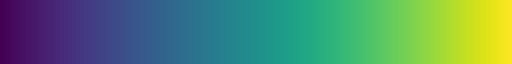

In [524]:
cmap = sns.color_palette('viridis', as_cmap=True)
cmap

In [527]:
# code to color protein by importance
idx = pd.IndexSlice
stat = 'SpearmanR'
norm = mpl.colors.Normalize(col_rs[stat].min(), col_rs[stat].max())
cmap.set_bad(color='lightgray')
importances = per_res_data.loc[idx['RS_GCF_003550175.1', :], 'aln_res'].map(col_rs[stat]).map(norm)
importances = importances.droplevel(level=0)
importances.index = importances.index.astype(str)

view = color_protein_by_importance(pdb, importances, cmap, 'blah')
# view = pt.rotate(view, 'x 90')
# view.control.spin([1, 0, 0], np.radians(200))
# view.control.spin([0, 0, 1], np.radians(100))
# view.control.spin([0, 1, 0], np.radians(120))
view._camera_orientation = [37.421705076881224,
 55.27602891677746,
 0.6331241719251035,
 0,
 -29.744772468427637,
 19.490042769921462,
 56.49434461532244,
 0,
 46.594943178707936,
 -31.951887110228906,
 35.555764794964,
 0,
 2.9601847082841855,
 -3.266889180259631,
 0.8666225032636867,
 1]
view

[['#fde725', '0'], ['#4ec36b', '1'], ['#218f8d', '2'], ['#37b878', '3'], ['#2a778e', '4']]


NGLWidget()

In [526]:
view._camera_orientation

[37.421705076881224,
 55.27602891677746,
 0.6331241719251035,
 0,
 -29.744772468427637,
 19.490042769921462,
 56.49434461532244,
 0,
 46.594943178707936,
 -31.951887110228906,
 35.555764794964,
 0,
 2.9601847082841855,
 -3.266889180259631,
 0.8666225032636867,
 1]

In [530]:
view.download_image(filename='./../data/figures/finalized_figures/figure3C_high_res_structure.png', transparent=True, factor=4)

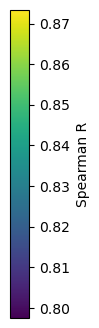

In [543]:
fig, ax = plt.subplots(figsize=(0.25,4))
plt.colorbar(mpl.cm.ScalarMappable(norm, cmap), cax=ax, label='Spearman R')
plt.savefig('./../data/figures/finalized_figures/figure_3_colorbar.svg', bbox_inches='tight')

In [511]:
genome2temp.loc['RS_GCF_003550175.1']

45.0

In [512]:
genome2tax.loc['RS_GCF_003550175.1']

domain                              Bacteria
phylum                        Pseudomonadota
class                    Alphaproteobacteria
order                            Rhizobiales
family                     Rhodomicrobiaceae
genus                       Dichotomicrobium
species    Dichotomicrobium thermohalophilum
Name: RS_GCF_003550175.1, dtype: object

In [176]:
ss_pdb_colors = per_res_data.loc[idx['RS_GCF_003550175.1', :], 'secondary_structure']
ss_pdb_colors = ss_pdb_colors.droplevel(level=0)
color_protein_by_importance(pdb, ss_pdb_colors, ss_color_map, 'blah')


[['#808080', '0'], ['#2c7bb6', '1'], ['#2c7bb6', '2'], ['#2c7bb6', '3'], ['#2c7bb6', '4']]


NGLWidget()

In [ ]:
# additional plots

In [1085]:
per_res_means = per_res_data.reset_index().dropna(axis=0).drop(['resname', 'uid', 'secondary_structure'], axis=1).groupby('aln_res').mean().reset_index()

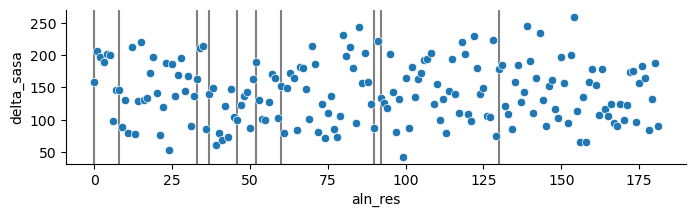

In [1090]:
fig, ax = plt.subplots(figsize=(8,2))
sns.scatterplot(data=per_res_means,
                x='aln_res', y='delta_sasa')

for col in col_rs.sort_values('SpearmanR', ascending=False).head(10).index:
    ax.axvline(col, color='gray', zorder=0)
    
sns.despine()

In [1097]:
per_res_means

,aln_res,loc,sasa,delta_sasa,normalized_delta_sasa,fa_sol,fa_atr,fa_elec,contacts_at_4.5
0,0.0,4.253364,30.942544,159.053744,0.842865,2.655660,-6.275425,-1.891635,11.292807
1,1.0,2.910853,33.052584,206.893740,0.874063,5.847607,-8.296203,-3.974030,13.803030
2,2.0,3.932010,0.264305,197.207160,0.998712,1.450398,-8.173504,-2.524454,15.781940
3,3.0,4.930986,0.329219,189.469372,0.998281,1.380532,-8.231968,-2.042402,14.692840
4,4.0,5.929720,2.412384,201.308840,0.988155,1.140614,-7.464308,-1.522417,15.991904
...,...,...,...,...,...,...,...,...,...
177,177.0,200.235854,34.403885,164.474516,0.832975,5.084129,-6.765558,-2.521077,12.450758
178,178.0,201.193072,97.698967,84.380127,0.473607,3.943742,-3.967652,-1.459241,8.756904
179,179.0,202.123169,32.896612,131.325556,0.804889,2.578637,-5.254491,-1.205050,11.763428
180,180.0,203.112304,11.890992,187.334603,0.940533,1.277613,-7.131261,-1.025835,13.986548


<Axes: xlabel='SpearmanR', ylabel='delta_sasa'>

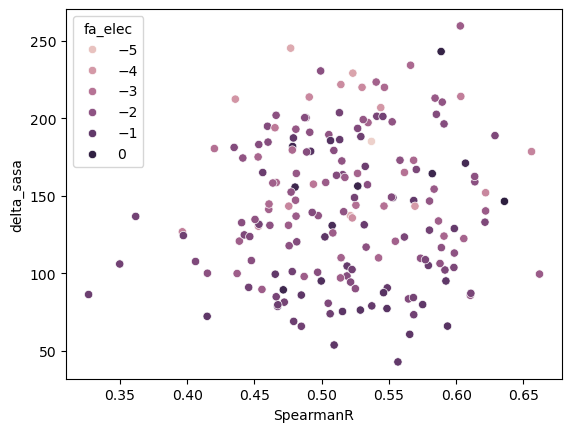

In [1094]:
sns.scatterplot(x=col_rs['SpearmanR'],
               y=per_res_means['delta_sasa'],
               hue=per_res_means['fa_elec'])

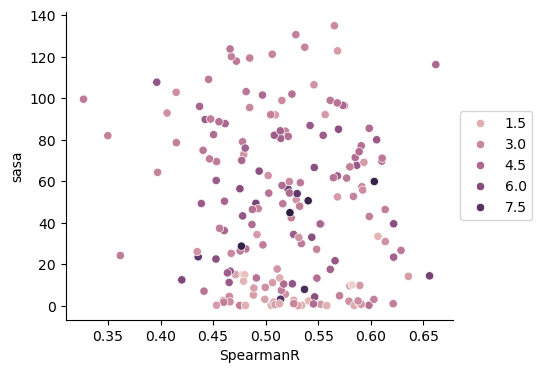

In [1102]:
fig, ax = plt.subplots(figsize=(5,4))
sns.scatterplot(x=col_rs['SpearmanR'],
               y=per_res_means['sasa'],
               hue=per_res_means['fa_sol'])
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()

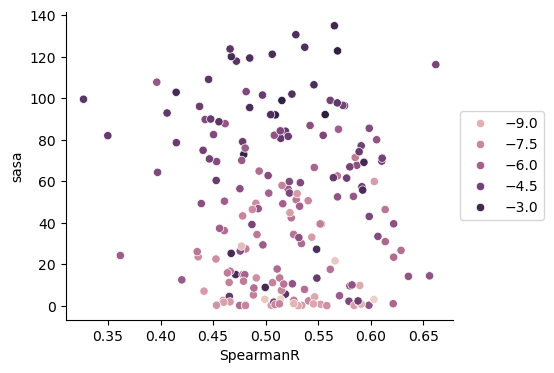

In [1103]:
fig, ax = plt.subplots(figsize=(5,4))
sns.scatterplot(x=col_rs['SpearmanR'],
               y=per_res_means['sasa'],
               hue=per_res_means['fa_atr'])
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()

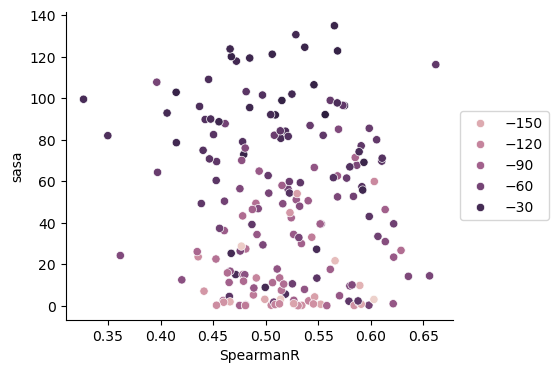

In [1107]:
fig, ax = plt.subplots(figsize=(5,4))
sns.scatterplot(x=col_rs['SpearmanR'],
               y=per_res_means['sasa'],
               hue=per_res_means['contacts_at_4.5'] * per_res_means['fa_atr']
               ) 
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()

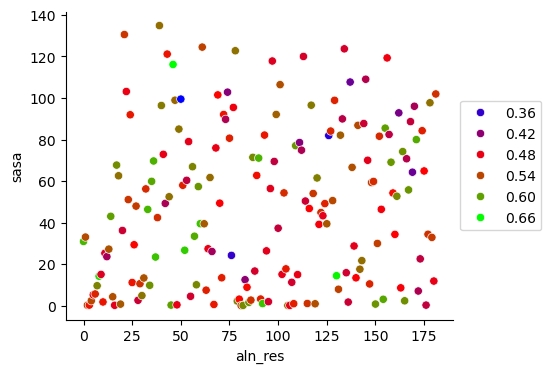

In [1383]:
fig, ax = plt.subplots(figsize=(5,4))
sns.scatterplot(x=per_res_means['aln_res'],
               y=per_res_means['sasa'],
               hue=col_rs['SpearmanR'], palette='brg'
               ) 
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()

In [1092]:
per_res_means

,aln_res,loc,sasa,delta_sasa,normalized_delta_sasa,fa_sol,fa_atr,fa_elec,contacts_at_4.5
0,0.0,4.253364,30.942544,159.053744,0.842865,2.655660,-6.275425,-1.891635,11.292807
1,1.0,2.910853,33.052584,206.893740,0.874063,5.847607,-8.296203,-3.974030,13.803030
2,2.0,3.932010,0.264305,197.207160,0.998712,1.450398,-8.173504,-2.524454,15.781940
3,3.0,4.930986,0.329219,189.469372,0.998281,1.380532,-8.231968,-2.042402,14.692840
4,4.0,5.929720,2.412384,201.308840,0.988155,1.140614,-7.464308,-1.522417,15.991904
...,...,...,...,...,...,...,...,...,...
177,177.0,200.235854,34.403885,164.474516,0.832975,5.084129,-6.765558,-2.521077,12.450758
178,178.0,201.193072,97.698967,84.380127,0.473607,3.943742,-3.967652,-1.459241,8.756904
179,179.0,202.123169,32.896612,131.325556,0.804889,2.578637,-5.254491,-1.205050,11.763428
180,180.0,203.112304,11.890992,187.334603,0.940533,1.277613,-7.131261,-1.025835,13.986548


In [222]:
per_res_data.head()

resname       sasa  delta_sasa  normalized_delta_sasa  \
uid                loc                                                         
GB_GCA_001054945.1 1       MET  75.315752  148.684248               0.663769   
                   2       ARG  41.959943  232.040057               0.846862   
                   3       LEU   0.000000  201.000000               1.000000   
                   4       VAL   0.125247  173.874753               0.999280   
                   5       LEU   3.253464  197.746536               0.983814   

                          fa_sol    fa_atr   fa_elec secondary_structure  \
uid                loc                                                     
GB_GCA_001054945.1 1    2.886560 -6.134512 -3.269996                   L   
                   2    7.630707 -9.452707 -6.076714                   E   
                   3    1.217929 -8.927249 -2.658222                   E   
                   4    0.905438 -7.462143 -1.721541                   E   
                   5    0.664696 -8.006336 -1.481625                   E   

                        contacts_at_4.5  aln_res  
uid                loc                            
GB_GCA_001054945.1 1                NaN      0.0  
                   2               14.0      1.0  
                   3               16.0      2.0  
                   4               16.0      3.0  
                   5               16.0      4.0

<Axes: xlabel='fa_atr', ylabel='mean_temp'>

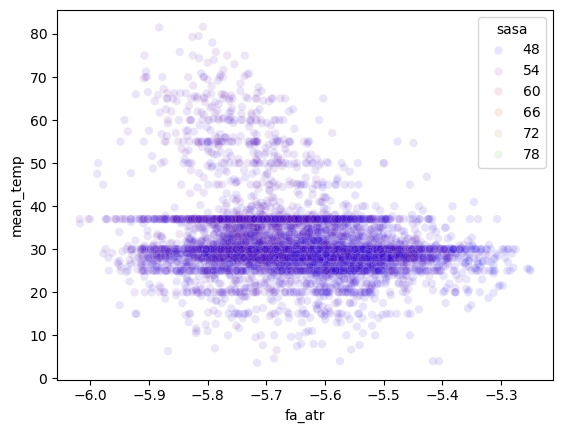

In [231]:
stat = 'fa_atr'
sns.scatterplot(x=per_res_data.reset_index().groupby('uid').agg({stat:'mean'})[stat],
                y=genome2temp['mean_temp'],
               hue=per_res_data.reset_index().groupby('uid').agg({'sasa':'mean'})['sasa'], 
               palette='brg', alpha=0.1)

## Conceptual plot, figure 3

In [629]:
embedding_rs = pd.Series()
for e in range(even_full_embeddings.shape[2]):
    embedding_rs.loc[e] = spearmanr(even_temps, even_full_embeddings[:, 0, e]).statistic


In [630]:
embedding_rs.sort_values()

63    -0.490489
34    -0.490250
146   -0.480195
22    -0.472527
287   -0.454788
         ...   
590    0.521642
243    0.529356
523    0.530051
232    0.543555
18     0.566930
Length: 768, dtype: float64

In [633]:
cmap = mpl.colormaps['coolwarm']
norm = mpl.colors.Normalize(embedding_rs.min(), embedding_rs.max())

In [641]:
unscale_ogts(list(even_temps), scaler)

array([30.07342989, 20.04016266, 40.10669712, ..., 15.02352904,
       22.0468161 , 27.06344972])

0.5435549204916479
0.566930175931459
0.5300505871708815
-0.49048876484092074
-0.49025007689375916


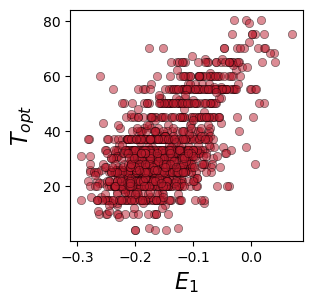

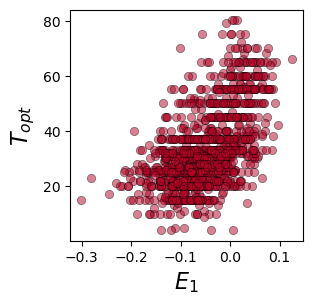

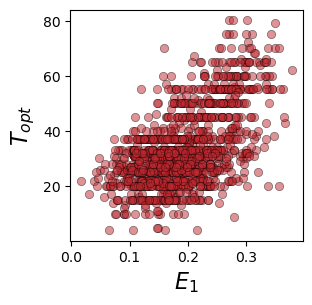

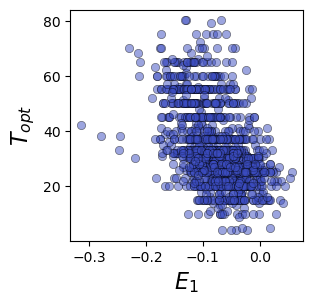

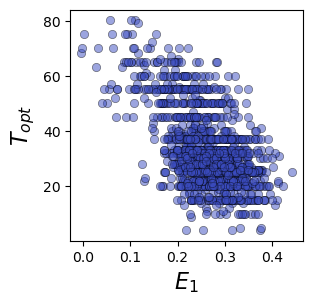

In [646]:
top = [232, 18, 523, 63, 34]
for t in top:
    print(embedding_rs.loc[t])
    fig, ax = plt.subplots(figsize=(3,3))
    sns.scatterplot(x=even_full_embeddings[:, 0, t], 
                    y=unscale_ogts(even_temps, scaler), 
                    c=cmap(norm(embedding_rs.loc[t])),
                    linewidth=0.5, edgecolor='k', alpha=0.5)
    ax.set_ylabel("$T_{opt}$", fontsize=16)
    ax.set_xlabel('$E_{1}$', fontsize=16)
    plt.savefig(f'./../data/figures/finalized_figures/figure_3A_plot{t}.svg', bbox_inches='tight')

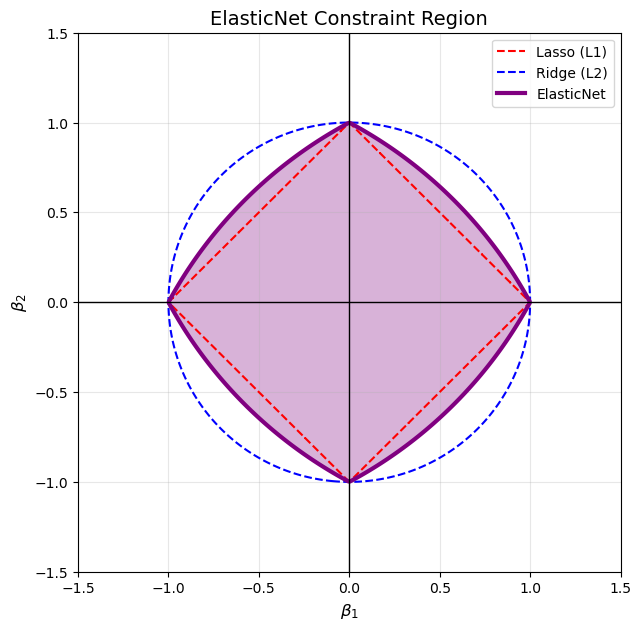

In [649]:
import numpy as np
import matplotlib.pyplot as plt

def plot_elastic_net_geometry():
    # Create a grid
    x = np.linspace(-1.5, 1.5, 400)
    y = np.linspace(-1.5, 1.5, 400)
    X, Y = np.meshgrid(x, y)

    # L1 (Lasso) Constraint: |w1| + |w2| <= 1
    L1 = np.abs(X) + np.abs(Y)
    
    # L2 (Ridge) Constraint: w1^2 + w2^2 <= 1
    L2 = X**2 + Y**2
    
    # Elastic Net (Combination): 0.5*L1 + 0.5*L2 <= 1
    EN = 0.7 * L1 + 0.3 * L2  # Adjusted ratio for visual clarity

    plt.figure(figsize=(7, 7))
    
    # Plot contours
    plt.contour(X, Y, L1, levels=[1], colors='red', linestyles='dashed')
    plt.contour(X, Y, L2, levels=[1], colors='blue', linestyles='dashed')
    plt.contourf(X, Y, EN, levels=[0, 1], colors='purple', alpha=0.3)
    plt.contour(X, Y, EN, levels=[1], colors='purple', linewidths=3)

    # Labels and Legend
    plt.axhline(0, color='black', lw=1)
    plt.axvline(0, color='black', lw=1)
    plt.title("ElasticNet Constraint Region", fontsize=14)
    plt.xlabel(r'$\beta_1$', fontsize=12)
    plt.ylabel(r'$\beta_2$', fontsize=12)
    
    # Custom Legend
    from matplotlib.lines import Line2D
    custom_lines = [Line2D([0], [0], color='red', linestyle='--'),
                    Line2D([0], [0], color='blue', linestyle='--'),
                    Line2D([0], [0], color='purple', lw=3)]
    plt.legend(custom_lines, ['Lasso (L1)', 'Ridge (L2)', 'ElasticNet'])
    
    plt.grid(alpha=0.3)
    plt.show()

plot_elastic_net_geometry()

# Figure 4 - embedding interpretations

## plot 1: protein-wide embeddings vs protein-wide structural features

In [276]:
ind_lm_model = reload_model('./../data/predictive_models/even_enetcv_ind.pickle')

In [277]:
with open('./../data/esm_msa/even_full_embeddings.pickle', 'rb') as handle:
    even_full_embeddings = pickle.load(handle)

with open('./../data/esm_msa/even_temps.pickle', 'rb') as handle:
    even_temps = pickle.load(handle)
    
print(even_full_embeddings.shape)

(1227, 215, 768)


In [356]:
# structural_data = pd.read_csv('./../data/metric_tables/20240327_metrics_df_full.tsv.gz', 
#                              sep='\t', compression='gzip')
# structural_data = structural_data.set_index('uid')

structural_data = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/metric_tables/20260513_full_metrics.tsv.gz', 
                         compression='gzip', sep='\t', index_col=0)

In [357]:
structural_data.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res', 'temp',
       'aligned_structure_len'],
      dtype='object')

In [359]:
structure_columns = ['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res']

In [358]:
# structure_columns = [
#     ('fa_atr_per_res'                 , -0.668085),
#     ('fa_sol_per_res'                 , -0.558903),
#     ('fa_elec_per_res'                , -0.276014),
#     ('p_aa_pp'                        , -0.210744),
#     ('bbsc_internal_hbonds_per_res'   , -0.107043),
#     ('packstat_per_res'               , -0.106018),
#     ('fa_dun_per_res'                 , -0.098650),
#     ('fa_intra_sol_xover4_per_res'    , -0.093837),
#     ('total_cc_contacts_per_res'      , -0.092636),
#     ('hbond_bb_sc_per_res'            , -0.085417),
#     ('avg_sc_nbrs_res_summary'        , -0.082998),
#     ('avg_cc_contacts_per_res'        , -0.078524),
#     ('nonpolar_sasa_per_res'          , -0.074757),
#     ('internal_hbonds'                , -0.073913),
#     ('ref'                            , -0.069218),
#     ('fa_rep_per_res'                 , -0.055021),
#     ('rama_prepro'                    , -0.019764),
#     ('omega_per_res'                  , -0.017834),
#     ('avg_deg_8'                      , -0.003190),
#     ('hbond_lr_bb_per_res'             , 0.001196),
#     ('cav_vol_per_res'                 , 0.001301),
#     ('yhh_planarity'                   , 0.017566),
#     ('pro_close_per_res'               , 0.030395),
#     ('avg_deg_4_5'                     , 0.030762),
#     ('sc_internal_hbonds_per_res'      , 0.039203),
#     ('polar_sasa_per_res'              , 0.040059),
#     ('hbond_sc_per_res'                , 0.046170),
#     ('length'                          , 0.052811),
#     ('fa_intra_rep_per_res'            , 0.067444),
#     ('lk_ball_wtd_per_res'             , 0.076668),
#     ('hbond_sr_bb_per_res'             , 0.081829),
#     ('Contacts at 4.5 Å'               , 0.138889),
#     ('SASA'                            , 0.21861)
# ]

# structure_columns = pd.Series(dict((i[0], i[1]) for i in structure_columns))

In [361]:
all_corrs = []
for col in tqdm(structure_columns):
    
    # if '_per_res' in col and not 'avg_cc_contacts' in col:
    #     data = structural_data.loc[even_ids, col.replace('_per_res', '')] / structural_data.loc[even_ids, 'length']
    # else:
    data = structural_data.loc[even_ids, col]
    structural_val = data.values.reshape(-1, 1)
    struct_rs = spearmanr(structural_val, 
                    even_full_embeddings[:, 0, :], axis=0)
    structure_corrs = struct_rs[0][0, 1:]
    all_corrs.append(structure_corrs)
    

100%|███████████████████████████████████████████| 39/39 [00:18<00:00,  2.16it/s]


In [362]:
all_scaled_params = []
for col in tqdm(ind_lm_model['best_model'].keys()):
    # scaler = StandardScaler()
    # scaled_params = scaler.fit_transform(ind_lm_model['best_model'][col].params.reshape(-1, 1)).reshape(1, -1)[0]
    all_scaled_params.append(ind_lm_model['best_model'][col].coef_)
all_scaled_params = np.array(all_scaled_params)

100%|█████████████████████████████████████| 215/215 [00:00<00:00, 361433.01it/s]


In [363]:
emb_dim_params = pd.DataFrame(np.array(all_scaled_params))
emb_importance_plotdf = emb_dim_params.stack().reset_index().rename(columns={'level_0':'site', 'level_1':'emb_dim', 0:'scaled_param'})
emb_dim_order = emb_importance_plotdf.groupby('emb_dim')['scaled_param'].mean().sort_values().index

Text(0.5, 1.0, 'Full protein coefs')

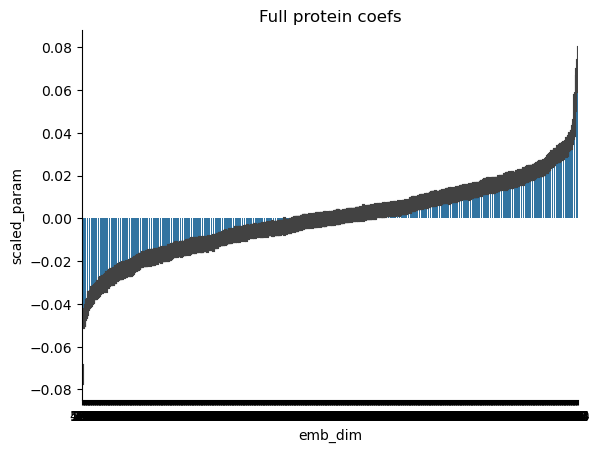

In [364]:
fig, ax = plt.subplots()
sns.barplot(data=emb_importance_plotdf, 
           x='emb_dim', y='scaled_param', order=emb_dim_order)
sns.despine()
ax.set_title('Full protein coefs')

<Axes: >

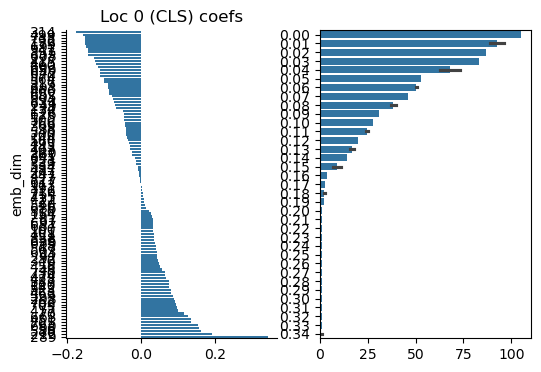

In [365]:
# series of coefficients at site 0 (the CLS)
# block 1
fig = plt.figure(figsize=(6,4))
emb_series = emb_importance_plotdf[emb_importance_plotdf['site'].eq(0)].groupby('emb_dim')['scaled_param'].mean().sort_values()
emb_series.index = emb_series.index.astype(str)

ax = fig.add_subplot(1,2,1)
sns.barplot(x=emb_series[~emb_series.eq(0)].values, 
            y=emb_series[~emb_series.eq(0)].index)
sns.despine()
ax.set_title('Loc 0 (CLS) coefs')

n_kept = [len(emb_series[emb_series.abs() > i]) for i in np.linspace(0, emb_series.abs().max(), 50)]
labels = [f'{i:.2f}' for i in np.linspace(0, emb_series.abs().max(), 50)]
ax = fig.add_subplot(1,2,2)
sns.barplot(x=n_kept, 
            y=labels)

In [366]:
# emb_series = emb_series[emb_series.abs() > 0.05]
emb_series.shape

(768,)

In [367]:
# trying with bootstrapped coefficients
# block 2
# boot_coeffs = pd.read_csv('./../data/predictive_models/supporting_data/enet_col0_boostrap_coefs.tsv', 
#                           sep='\t', index_col=0)
# boot_coeffs.index = boot_coeffs.index.astype(str)
# emb_series = boot_coeffs[boot_coeffs['n_nonzero'] >= 70]['mean_coef']
# boot_coeffs.head()

In [368]:
# fig, ax = plt.subplots(figsize=(8,3))
# sns.barplot(data=boot_coeffs,
#            x='component',
#            y='mean_coef', hue=((boot_coeffs['mean_coef'].abs() - boot_coeffs['std_coef']) < 0))
# sns.despine()

<Axes: >

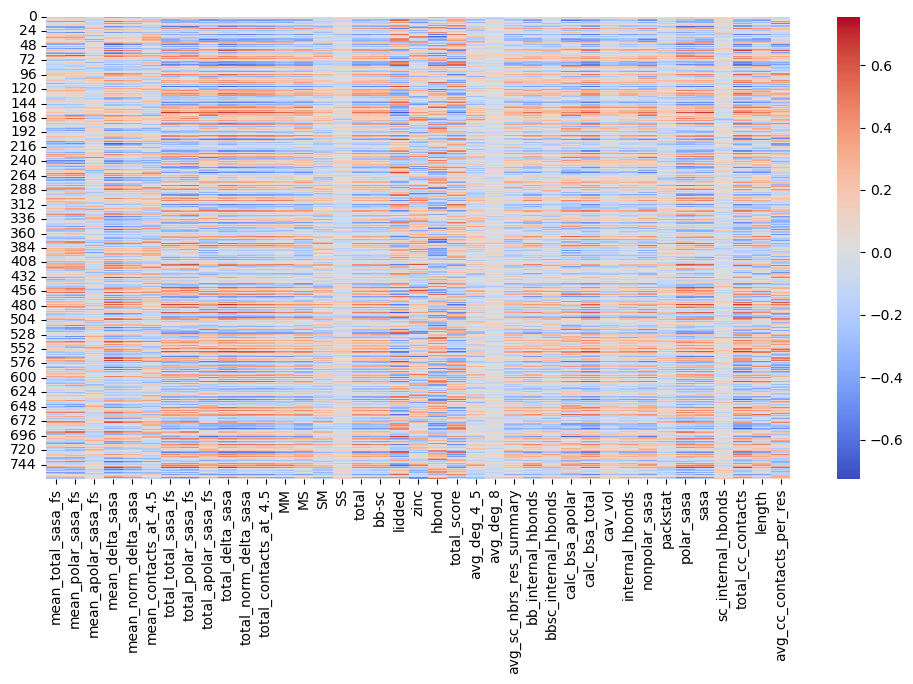

In [369]:
emb_vs_struct_corrs = pd.DataFrame(all_corrs, index=structure_columns).T
emb_vs_struct_corrs.index = emb_vs_struct_corrs.index.astype(str)
# if using block 1
# emb_vs_struct_corrs = emb_vs_struct_corrs.reindex(index=emb_series[~emb_series.eq(0)].index)

# if using block 2
# emb_vs_struct_corrs = emb_vs_struct_corrs.reindex(index=emb_series.index)

corr_scaler  = StandardScaler()
scaled_emb_vs_struct_corrs = corr_scaler.fit_transform(emb_vs_struct_corrs)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(emb_vs_struct_corrs, cmap='coolwarm', ax=ax)

<Axes: >

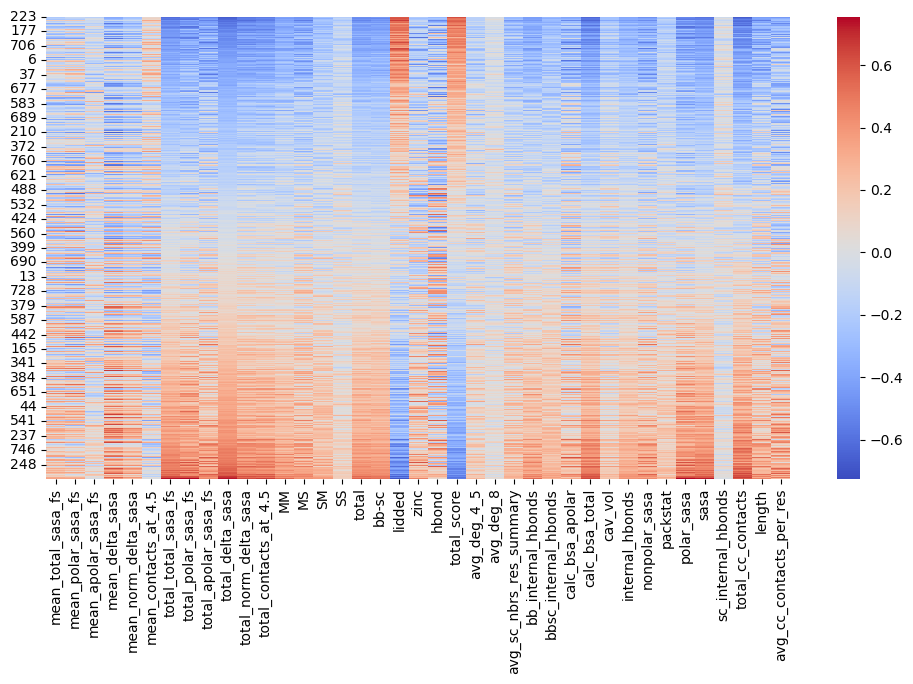

In [370]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(emb_vs_struct_corrs.reindex(index=emb_vs_struct_corrs.mean(axis=1).sort_values().index), cmap='coolwarm', ax=ax)

/data/mhoffert/miniforge3/envs/adenylate_kinase_ogt/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/data/mhoffert/miniforge3/envs/adenylate_kinase_ogt/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


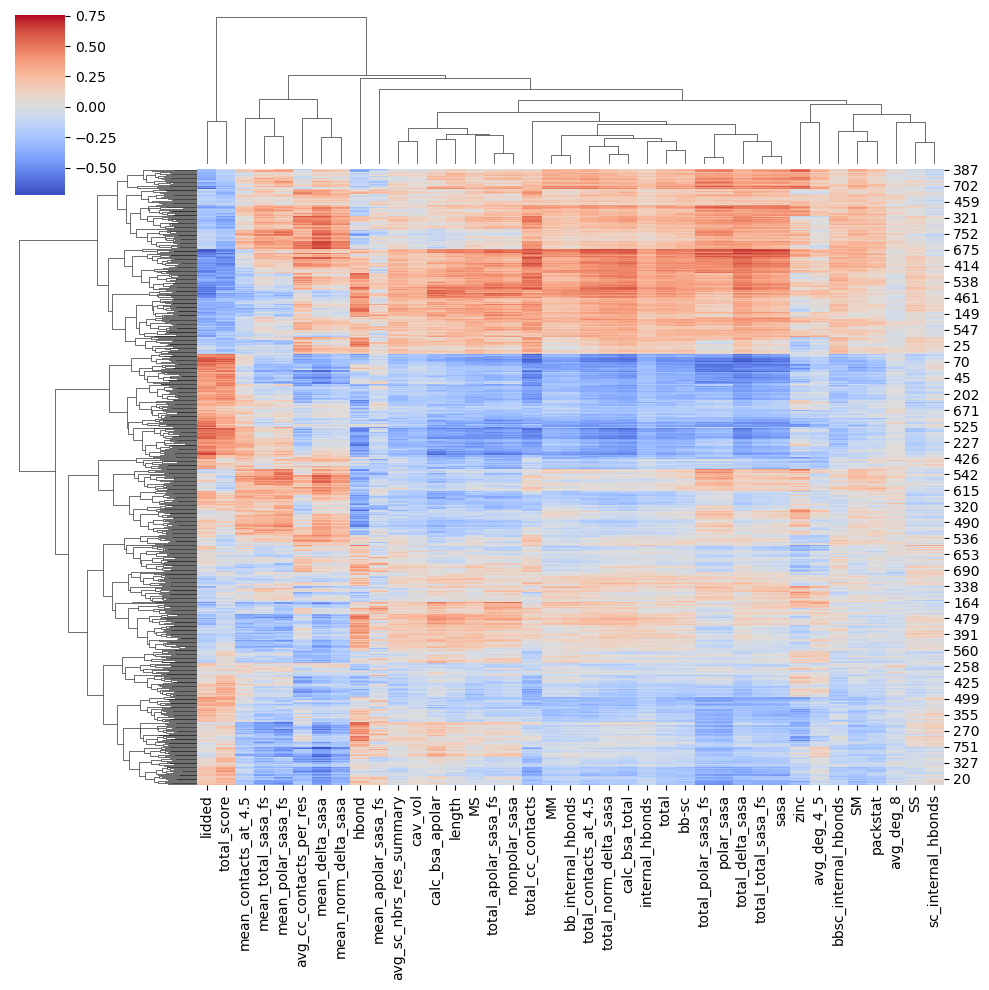

In [371]:
g = sns.clustermap(emb_vs_struct_corrs, cmap='coolwarm')

In [372]:
hue_min, hue_max = structure_columns.iloc[g.dendrogram_col.reordered_ind].min(), structure_columns.iloc[g.dendrogram_col.reordered_ind].max()

AttributeError: 'list' object has no attribute 'iloc'

In [ ]:
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(3, 3, width_ratios = [2, 10, 1], height_ratios = [2, 10, 1])
# ax = fig.add_subplot(gs[0, 0])

# heatmap
ax3 = fig.add_subplot(gs[1, 1])
cax = fig.add_subplot(gs[1, 2])
# rows = embedding, cols = structure
# sort by average correlation across all structures
heatmap_x_order = emb_vs_struct_corrs.mean(axis=1).sort_values().index
heatmap_x_order = emb_series.sort_values().index #emb_vs_struct_corrs.mean(axis=1).sort_values().index
# sort by 1 column
# heatmap_x_order = emb_vs_struct_corrs['fa_atr_per_res'].sort_values().index
sns.heatmap(emb_vs_struct_corrs.loc[heatmap_x_order, :].iloc[:, g.dendrogram_col.reordered_ind],
                #emb_vs_struct_corrs.iloc[g.dendrogram_row.reordered_ind, 
                #emb_vs_struct_corrs.iloc[g.dendrogram_col.reordered_ind], 
            ax=ax3, cbar_ax=cax, 
           cmap='coolwarm')
ax3.tick_params(labelleft=False)
sns.despine()

# top plot
ax1 = fig.add_subplot(gs[0, 1])
tsnorm = mpl.colors.TwoSlopeNorm(vcenter=0, vmin=hue_min, vmax=hue_max)
sns.pointplot(y=structure_columns.iloc[g.dendrogram_col.reordered_ind].values, 
              x=structure_columns.iloc[g.dendrogram_col.reordered_ind].index, 
              hue=structure_columns.iloc[g.dendrogram_col.reordered_ind], 
              palette='coolwarm', 
              hue_norm=tsnorm,
              # color='r', #['r'] * n_colors,
              ax=ax1)

ax1.set_ylim(-0.75, 0.75)
ax1.axhline(0, color='gray', linestyle='--', zorder=0)
ax1.set_title('Association of structural features with temperature')
lgd = ax1.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncols=2)
ax1.tick_params(axis='x', labelbottom=False)
sns.despine()

# left plot
ax2 = fig.add_subplot(gs[1, 0])                        
# sns.barplot(x=enet_boot_series.loc[heatmap_x_order].values,
#             y=enet_boot_series.loc[heatmap_x_order].index,
#             ax=ax2)

# v this code to align with dendrogram v
# x=[~emb_series.eq(0)].iloc[g.dendrogram_row.reordered_ind].values,
# y=[~emb_series.eq(0)].iloc[g.dendrogram_row.reordered_ind].index,
sns.barplot(x=emb_series.loc[heatmap_x_order].values,         
            y=emb_series.loc[heatmap_x_order].index,         
            ax=ax2, hue=emb_series.loc[heatmap_x_order].values, 
            palette='coolwarm', legend=False)
ax2.set_yticks(list(range(0, len(emb_series[~emb_series.eq(0)]), 50)))
# ax2.set_xlim(-5, 5)
sns.despine()

plt.savefig('./../data/figures/Figure4_esm_vs_struct.png', dpi=400, bbox_inches='tight')

### Comparing predictions of structure and temp

In [ ]:
# for col in ['fa_intra_sol_xover4_per_res']:
    
#     if '_per_res' in col and not 'avg_cc_contacts' in col:
#         data = structural_data.loc[even_ids, col.replace('_per_res', '')] / structural_data.loc[even_ids, 'length']
#     else:
#         data = structural_data.loc[even_ids, col]
#     structural_val = data.values.reshape(-1, 1)

# sns.scatterplot(x=data, y=structural_data.loc[even_ids, 'temp'])

In [373]:
import statsmodels.api as sm
from glmnet import ElasticNet

In [374]:
emb_scaler = StandardScaler()
emb = emb_scaler.fit_transform(even_full_embeddings[:, 0, :])

model = ElasticNet(alpha=0.25).fit( emb, data)

In [375]:
emb_series_temp = emb_importance_plotdf[emb_importance_plotdf['site'].eq(0)].groupby('emb_dim')['scaled_param'].mean().sort_values()
emb_series_temp.index = emb_series_temp.index.astype(str)

Text(0.5, 0, 'coefficient (predicting structure)')

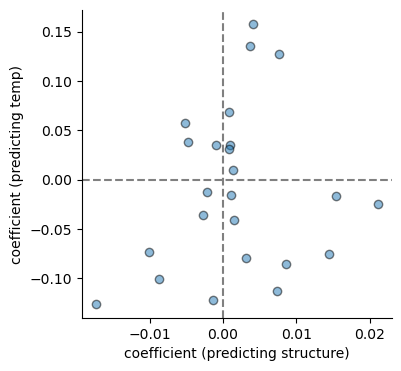

In [376]:
fig, ax = plt.subplots(figsize=(4,4))
struct_series_temp = pd.Series(data=model.coef_, index=[str(i) for i in list(range(768))])
temp_shared = set(struct_series_temp[~struct_series_temp.eq(0)].index).intersection(emb_series_temp[~emb_series_temp.eq(0)].index)
                
sns.scatterplot(x=struct_series_temp.reindex(temp_shared),
                y=emb_series_temp.reindex(temp_shared), 
            **{'linewidths':1, 'edgecolor':'k', 'alpha':0.5})
ax.axvline(0, color='gray', linestyle='--', zorder=0)
ax.axhline(0, color='gray', linestyle='--', zorder=0)
sns.despine()
ax.set_ylabel('coefficient (predicting temp)')
ax.set_xlabel('coefficient (predicting structure)')

In [378]:
# model.summary()

<Axes: xlabel='None', ylabel='temp'>

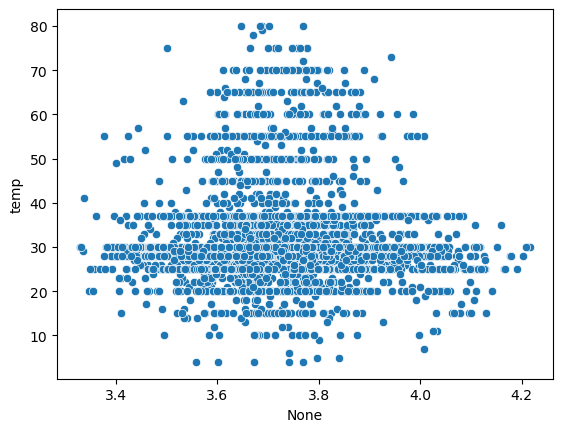

In [676]:
plotdf = structural_data[(structural_data['length'] < 220) & (structural_data['length'] > 180)]
sns.scatterplot(data=plotdf,
                x=plotdf['fa_sol'] / plotdf['length'],
                y='temp')

<Axes: xlabel='None', ylabel='temp'>

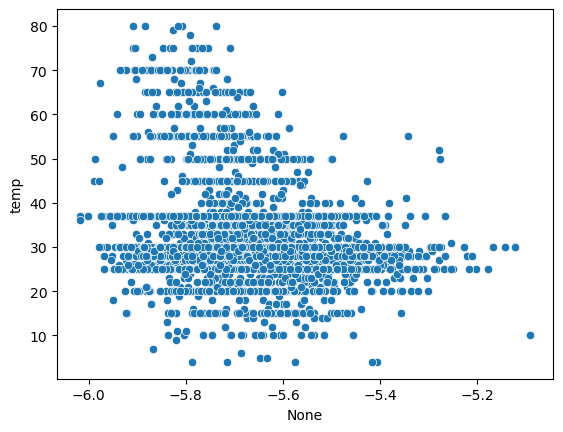

In [677]:
plotdf = structural_data[(structural_data['length'] < 220) & (structural_data['length'] > 180)]
sns.scatterplot(data=plotdf,
                x=plotdf['fa_atr'] / plotdf['length'],
                y='temp')

# New version of Figure 4

In [379]:
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

In [380]:
emb_scaler = StandardScaler()
embs_scaled = scaler.fit_transform(even_full_embeddings[:, 0, :])

###  need to normalize this to length

100%|████████████████████████████████████████| 768/768 [00:02<00:00, 266.31it/s]


Text(0.5, 1.0, 'colored by corr')

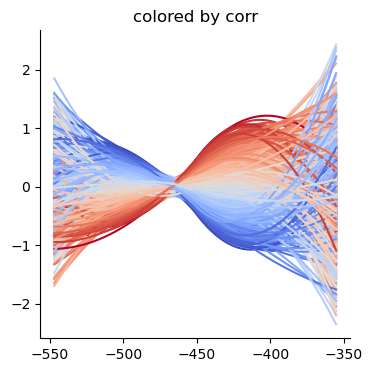

In [381]:
fig, ax = plt.subplots(figsize=(4,4))
struct_val = 'total_score'

norm = mpl.colors.TwoSlopeNorm(vmin=emb_vs_struct_corrs.loc[:, struct_val].min(),
                              vcenter=0, vmax=emb_vs_struct_corrs.loc[:, struct_val].max())
cmap = mpl.colormaps['coolwarm']



# main points
# sns.scatterplot(x=structural_data.loc[inds, "SASA"],
#                y=single_emb.loc[inds], linewidth=1, edgecolor='k', 
#                 alpha=0.25, color='gray')

X = structural_data.loc[even_ids, struct_val.replace('_per_res', '')]
X = X[X <= 56]
inds = X.index
X = X.values.reshape(-1, 1)

for emb_col in tqdm([str(i) for i in list(range(768))]):
    
    single_emb = pd.Series(data=embs_scaled[:, int(emb_col)], index=even_ids)
    y = single_emb.loc[inds].values
    
    model = make_pipeline(SplineTransformer(n_knots=3, degree=2), Ridge(alpha=1e-4))
    model.fit(X, y)
    X_plot = np.linspace(X.min(), X.max(), 500).reshape(-1, 1)
    y_plot = model.predict(X_plot)
    ax.plot(X_plot, y_plot, color=cmap(norm(emb_vs_struct_corrs.loc[emb_col, struct_val])))


# ax.set_xlim(45, 55)
sns.despine()
ax.set_title('colored by corr')

In [382]:
norm = mpl.colors.TwoSlopeNorm(vmin=emb_series.min(),
                              vcenter=0, vmax=emb_series.max())
cmap = mpl.colormaps['coolwarm']

In [384]:
vals_name_map = {
                 'mean_total_sasa_fs':'Solvent accessible surface area ($Å^{2}$)',
                'mean_contacts_at_4.5':'Contacts at 4.5 Å', 
                 'total_score':'Rosetta energy',
                'mean_delta_sasa':'Delta SASA'}

# struct_corrs_names = {'SASA':'SASA',
#                  'cav_vol':'cav_vol_per_res', 
#                  'fa_atr':'fa_atr_per_res',
#                 'Contacts at 4.5 Å':'Contacts at 4.5 Å'}

In [385]:
structural_data.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res', 'temp',
       'aligned_structure_len'],
      dtype='object')

In [386]:
emb_vs_struct_corrs.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res'],
      dtype='object')

100%|████████████████████████████████████████| 100/100 [00:00<00:00, 332.14it/s]


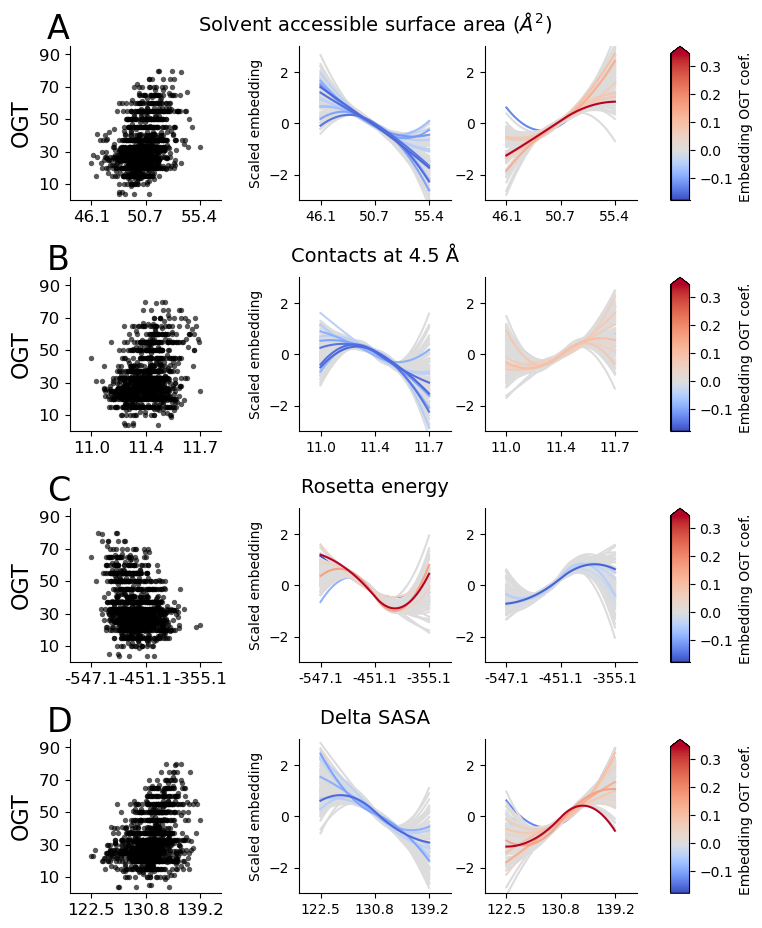

In [391]:
# fig, ax = plt.subplots(figsize=(4,4))
struct_vals = list(vals_name_map.keys())
subplot_labels = ['A', 'B', 'C', 'D']

fig = plt.figure(figsize=(8, 11))
gs = fig.add_gridspec(4, 5, width_ratios=[8,0.5,8,8,1])

for i, struct_val in enumerate(struct_vals):
    
    X = structural_data.loc[even_ids, struct_val]
    inds = X.index
    X = X.values.reshape(-1, 1)
    
    n_features = 100
    

    # -------------------------
    # plot 1
    
    ax = fig.add_subplot(gs[i, 0]) #fig.add_subplot(1,3,1)
    
    
    subset = structural_data.loc[even_ids]
    # if 'per_res' in struct_corrs_names[struct_val] or struct_val == 'sasa':
    #     scatter_x = subset[struct_val] / subset['length']
    # else:
        
    scatter_x = subset[struct_val]
        
    sns.scatterplot(data=subset,
                    x=scatter_x, 
                    y='temp', 
                    color='k', linewidth=0, s=15, alpha=0.65)
                    # color='lightgray', edgecolor='k')
    direction = spearmanr(scatter_x, subset['temp']).statistic

    # ----- formatting 
    plt.tick_params(labelsize=12)
    ax.set_ylabel('OGT', fontsize=16)
    ax.set_xlabel('')

    ax.annotate(text=subplot_labels[i], fontsize=24, xy=(-0.15, 1.05), annotation_clip=False, xycoords='axes fraction')
    ax.set_ylim(0, 95)
    ax.set_yticks(np.linspace(10, 90, 5).astype(int))
    sns.despine()
    _range = np.abs(scatter_x.max() - scatter_x.min())
    lim_extend = 0.2
    xticks = [scatter_x.min(),
               scatter_x.min()+(_range/2),
              scatter_x.max()]
    
    ax.set_xlim(scatter_x.min()-_range*lim_extend, 
                scatter_x.max()+_range*lim_extend)
    ax.set_xticks(xticks)
    ax.set_xticklabels([f'{i:.1f}' for i in xticks])
    # -------------------------
    # plot 2
                  
    
    
    # two lists: 
    # [n_features, n_features-1, ..., 0]
    # [-n_features, -n_features+1]
    # indeces for the first / last n_features elements of a list

    reverse = True if direction > 0 else False
    
    for j, indeces in enumerate([list(range(n_features, -1, -1)), 
                                 list(range(-n_features, -1, 1)) + [-1]]):
        
        # fig.add_subplot(1,3,2)
        ax = fig.add_subplot(gs[i, j+2]) 
        if j == 0:
            ax.set_title(vals_name_map[struct_val], fontsize=14, y=1.05)
            ax.set_ylabel('Scaled embedding')
            
        # list of splines to plot
        plotters = []

        # for column in either n_features most correlated / anti-correlated embedding components
        for emb_col in tqdm(emb_vs_struct_corrs.loc[:, struct_val].sort_values().iloc[indeces].index):
            
            single_emb = pd.Series(data=embs_scaled[:, int(emb_col)], index=even_ids)
            y = single_emb.loc[inds].values
            
            model = make_pipeline(SplineTransformer(n_knots=3, degree=2), Ridge(alpha=1e-4))
            model.fit(scatter_x.values.reshape(-1, 1), y)
            X_plot = np.linspace(scatter_x.values.min(), scatter_x.values.max(), 500).reshape(-1, 1)
            y_plot = model.predict(X_plot)
            plotters.append((emb_series.loc[emb_col], X_plot, y_plot, cmap(norm(emb_series.loc[emb_col]))))
        

        #     reverse=True
        # else:
        #     reverse=False
        for p in sorted(plotters, key=lambda x: x[0], reverse=reverse):
            _val, _x, _y, _c = p
            ax.plot(_x, _y,
                    color=_c)

        reverse = not reverse

        
        # ----- formatting 
        ax.set_xlabel('')
        sns.despine()
        ax.set_xlim(scatter_x.min()-_range*lim_extend, 
                    scatter_x.max()+_range*lim_extend)
        ax.set_xticks(xticks)
        ax.set_xticklabels([f'{i:.1f}' for i in xticks])
        ax.set_ylim(-3, 3)
        ax.set_yticks([-2, 0, 2])
        

    # ----- cbar
    ax = fig.add_subplot(gs[i, 4])
    cb = plt.colorbar(cax=ax, 
                     mappable=mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
                     extend='max',
                     spacing='proportional')
    cb.ax.set_yscale('linear')
    cb.ax.set_yticks(list(np.arange(-0.1, 0.4, 0.1)))
    cb.ax.set_ylabel('Embedding OGT coef.')
    

fig.subplots_adjust(hspace=0.5, wspace=0.35)
plt.savefig('./../data/figures/finalized_figures/Fig4.svg', bbox_inches='tight')
plt.savefig('./../data/figures/finalized_figures/Fig4.png', bbox_inches='tight', dpi=400)

In [ ]:
# I wonder if differences in zinc lids are present as well 

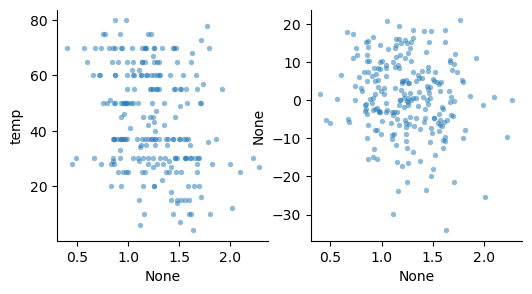

In [936]:
# is cavity volume explaining errors?
corkrey_preds = pd.Series(data=unscale_ogts(loaded_model['predictions'], scaler),
          index=[i.split('|')[1] for i in loaded_model['true_labels']])
corkrey_trues = pd.Series(data=unscale_ogts(loaded_model['true_values'], scaler),
          index=[i.split('|')[1] for i in loaded_model['true_labels']])

#
fig = plt.figure(figsize=(6,3)) 
ax = fig.add_subplot(1,2,1)
sns.scatterplot(x=structural_data.loc[corkrey_ids, 'cav_vol'] / structural_data.loc[corkrey_ids, 'length'],
                y=structural_data.loc[corkrey_ids, 'temp'], s=15, linewidth=0, alpha=0.5)
sns.despine()
ax = fig.add_subplot(1,2,2)
sns.scatterplot(x=structural_data.loc[corkrey_ids, 'cav_vol'] / structural_data.loc[corkrey_ids, 'length'],
                y=corkrey_trues - corkrey_preds, s=15, linewidth=0, alpha=0.5)
sns.despine()

In [1020]:
len(even_ids)

1227

In [933]:
loaded_model.keys()

dict_keys(['best_model', 'best_params', 'predictions', 'full_predictions', 'true_values', 'true_labels', 'statsmodels_version', 'metadata', 'scalers'])

In [990]:
delta = 0.01
x = np.arange(0, 4.001, delta)
y = np.arange(0.0, 4.001, delta)
X, Y = np.meshgrid(x, y)
Z = X**2 + Y**2

In [991]:
Z

array([[0.00000e+00, 1.00000e-04, 4.00000e-04, ..., 1.58404e+01,
        1.59201e+01, 1.60000e+01],
       [1.00000e-04, 2.00000e-04, 5.00000e-04, ..., 1.58405e+01,
        1.59202e+01, 1.60001e+01],
       [4.00000e-04, 5.00000e-04, 8.00000e-04, ..., 1.58408e+01,
        1.59205e+01, 1.60004e+01],
       ...,
       [1.58404e+01, 1.58405e+01, 1.58408e+01, ..., 3.16808e+01,
        3.17605e+01, 3.18404e+01],
       [1.59201e+01, 1.59202e+01, 1.59205e+01, ..., 3.17605e+01,
        3.18402e+01, 3.19201e+01],
       [1.60000e+01, 1.60001e+01, 1.60004e+01, ..., 3.18404e+01,
        3.19201e+01, 3.20000e+01]])

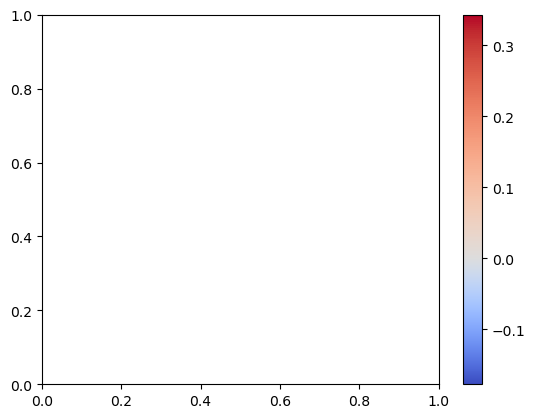

In [1006]:
fig, ax = plt.subplots()
norm = mpl.colors.TwoSlopeNorm(vmin=emb_series.min(),
                              vcenter=0, vmax=emb_series.max())
cmap = mpl.colormaps['coolwarm']
cb = plt.colorbar(ax=ax,
                 mappable=mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
             # extend='max', 
                  # spacing='proportional'
                )
cb.ax.set_yscale('linear')
# m1 = plt.pcolormesh(emb_series, cmap=cmap, norm=norm)
# cb = plt.colorbar(m1, extend='max', spacing='proportional')
# cb.ax.set_yscale('linear')

In [713]:
emb_series.max()

0.34311122

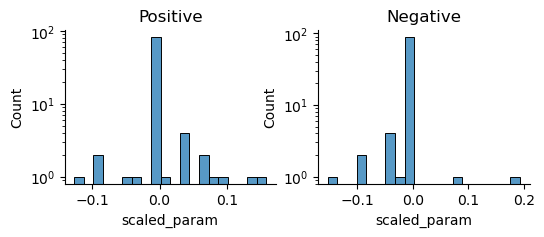

In [654]:
fig = plt.figure(figsize=(6, 2))
ax = fig.add_subplot(1, 2, 1)
sns.histplot(emb_series.loc[emb_vs_struct_corrs.loc[:, 'fa_atr_per_res'].sort_values().head(n_features).index], bins=20)
sns.despine()
ax.set_yscale('log')
ax.set_title('Positive')

ax = fig.add_subplot(1, 2, 2)
ax.set_title('Negative')
sns.histplot(emb_series.loc[emb_vs_struct_corrs.loc[:, 'fa_atr_per_res'].sort_values().tail(n_features).index], bins=20)
sns.despine()
ax.set_yscale('log')

<Axes: xlabel='scaled_param', ylabel='Count'>

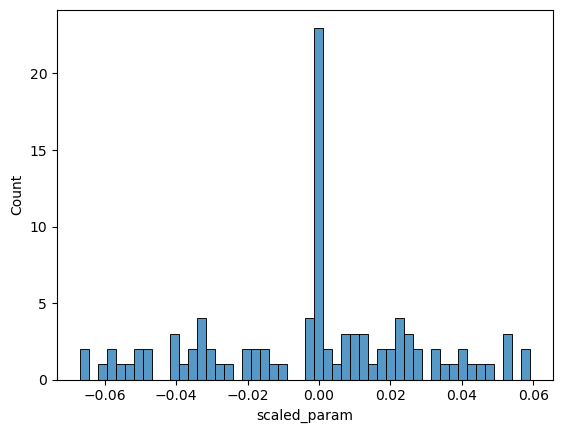

In [877]:
X.reshape(1, -1)[0]

array([51.74701557, 47.83439557, 52.18718469, ..., 51.69941865,
       49.54460307, 50.059659  ])

<Axes: >

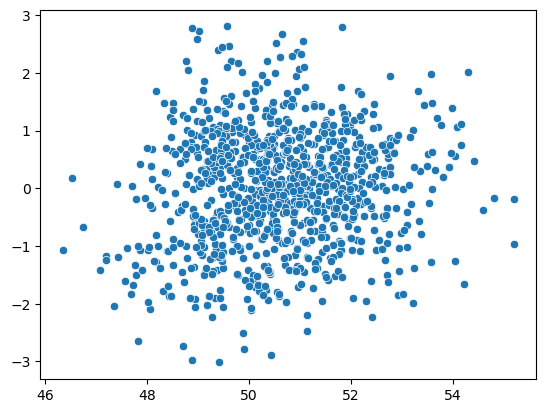

In [878]:
sns.scatterplot(x=X.reshape(1, -1)[0], y=y)

In [780]:
emb_vs_struct_corrs['SASA'].sort_values()

emb_dim
645   -0.500605
469   -0.461540
749   -0.432380
348   -0.414858
158   -0.408706
         ...   
296    0.413193
451    0.413682
513    0.414271
18     0.463075
709    0.495919
Name: SASA, Length: 130, dtype: float64

In [777]:
structure_corrs

array([ 0.03656686,  0.20593245, -0.03459251, ...,  0.11221397,
       -0.26343833, -0.22749093])

# Figure "5": per-site embeddings vs per-site structural features

## Tools

In [24]:
import scipy
from sklearn.manifold import MDS
from scipy.spatial.distance import pdist, squareform

In [25]:
def calculate_morans_i(coords, values):
    """
    Calculates Moran's I statistic for continuous data.
    coords: Nx2 array of (x, y) positions
    values: N array of continuous color/data values
    """
    n = len(values)
    # 1. Standardize the values (z-scores)
    z = values - np.mean(values)
    
    # 2. Create the weight matrix (Inverse Distance Weighting)
    # This assumes closer points should have more similar colors
    dist_matrix = squareform(pdist(coords))
    with np.errstate(divide='ignore'):
        weights = 1.0 / dist_matrix
    np.fill_diagonal(weights, 0) # Remove self-distance
    
    # Global sum of weights
    w_sum = np.sum(weights)
    
    # 3. Calculate Moran's I
    # Numerator: Cross-product of neighbors weighted by distance
    numerator = np.sum(weights * np.outer(z, z))
    # Denominator: Variance of the values
    denominator = np.sum(z**2)
    
    return (n / w_sum) * (numerator / denominator)

In [26]:
with open('./../data/esm_msa/corkrey_full_embeddings.pickle', 'rb') as handle:
    corkrey_full_embeddings = pickle.load(handle)

## Explore pca loadings

In [14]:
from sklearn.decomposition import PCA

In [15]:
from tqdm import tqdm

In [16]:
with open('./../data/esm_msa/even_temps.pickle', 'rb') as handle:
    even_temps = pickle.load(handle)

In [17]:
with open('./../data/esm_msa/tuned_even_full_embeddings.pickle', 'rb') as handle:
    tuned_even_full_embeddings = pickle.load(handle)

In [18]:
with open('./../data/esm_msa/tuned_even_full_embeddings.pickle', 'rb') as handle:
    even_full_embeddings = pickle.load(handle)

In [19]:
with open('./../data/esm_msa/even_embeddings.pickle', 'rb') as handle:
    even_embeddings = pickle.load(handle)

In [20]:
with open('./../data/esm_msa/tuned_even_embeddings.pickle', 'rb') as handle:
    tuned_even_embeddings = pickle.load(handle)

In [21]:
with open('./../data/predictive_models/tuned_pca.pickle', 'rb') as handle:
    tuned_pca = pickle.load(handle)

In [22]:
with open('./../data/predictive_models/pca.pickle', 'rb') as handle:
    pca = pickle.load(handle)

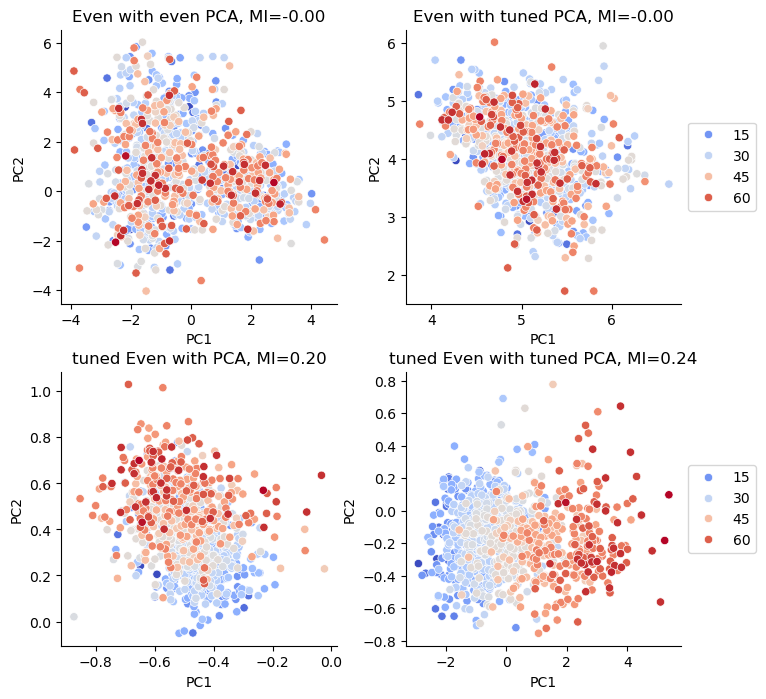

In [28]:
fig = plt.figure(figsize=(8, 8))
# plot 1
# ------------------------------------------
ax = fig.add_subplot(2,2,1)
pca_comp = pca.transform(even_embeddings)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, 6)])
plotdf['temp'] = unscale_ogts(even_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
mi = calculate_morans_i(pca_comp, even_temps)
ax.set_title(f'Even with even PCA, MI={mi:.2f}')
ax.get_legend().remove()
# plot 2
# ------------------------------------------
ax = fig.add_subplot(2,2,2)
pca_comp = tuned_pca.transform(even_embeddings)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, 6)])
plotdf['temp'] = unscale_ogts(even_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
mi = calculate_morans_i(pca_comp, even_temps)
ax.set_title(f'Even with tuned PCA, MI={mi:.2f}')

# plot 3
# ------------------------------------------
ax = fig.add_subplot(2,2,3)
pca_comp = pca.transform(tuned_even_embeddings)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, 6)])
plotdf['temp'] = unscale_ogts(even_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.get_legend().remove()
sns.despine()
mi = calculate_morans_i(pca_comp, even_temps)
ax.set_title(f'tuned Even with PCA, MI={mi:.2f}')

# plot 4
# ------------------------------------------
ax = fig.add_subplot(2,2,4)
pca_comp = tuned_pca.transform(tuned_even_embeddings)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, 6)])
plotdf['temp'] = unscale_ogts(even_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
mi = calculate_morans_i(pca_comp, even_temps)
ax.set_title(f'tuned Even with tuned PCA, MI={mi:.2f}')

fig.subplots_adjust(wspace=0.25,hspace=0.25)

In [101]:
with open('./../data/validation_datasets/Mycobacteria/embeddings/Mycobacteria_full_tuned_even.pickle', 'rb') as handle:
    myco_full_tuned_embeddings = pickle.load(handle)

In [102]:
with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_full_tuned_even.pickle', 'rb') as handle:
    arth_full_tuned_embeddings = pickle.load(handle)

In [103]:
with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_full_even.pickle', 'rb') as handle:
    arth_full_embeddings = pickle.load(handle)

In [104]:
with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_mean_tuned_even.pickle', 'rb') as handle:
    arth_tuned_embeddings = pickle.load(handle)

In [105]:
with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_mean_even.pickle', 'rb') as handle:
    arth_embeddings = pickle.load(handle)

In [106]:
with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_temps.pickle', 'rb') as handle:
    arth_temps = pickle.load(handle)

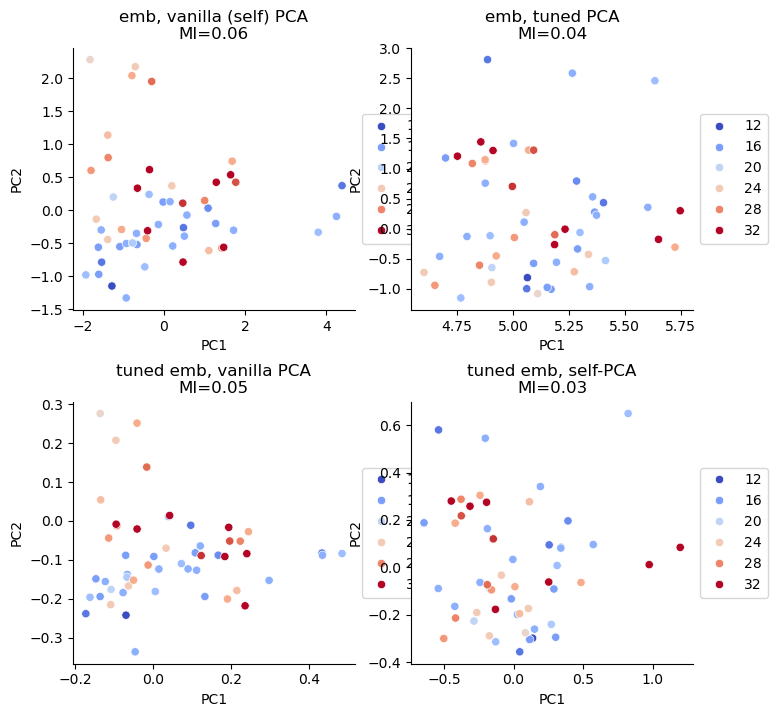

In [107]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(2,2,1)
arth_diff = arth_embeddings #(arth_full_embeddings - arth_full_tuned_embeddings)
diff_pca = PCA(n_components=5)
X = pd.DataFrame(arth_diff)
pca_comp = diff_pca.fit_transform(X)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, pca_comp.shape[1]+1)])
plotdf['temp'] = unscale_ogts(arth_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
mi = calculate_morans_i(pca_comp, arth_temps)
ax.set_title(f'emb, vanilla (self) PCA\nMI={mi:.2f}')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

ax = fig.add_subplot(2,2,3)
arth_diff = arth_tuned_embeddings #(arth_full_embeddings - arth_full_tuned_embeddings)
# diff_pca = PCA(n_components=5)
X = pd.DataFrame(arth_diff)
pca_comp = diff_pca.transform(X)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, pca_comp.shape[1]+1)])
plotdf['temp'] = unscale_ogts(arth_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
mi = calculate_morans_i(pca_comp, arth_temps)
ax.set_title(f'tuned emb, vanilla PCA\nMI={mi:.2f}')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

ax = fig.add_subplot(2,2,4)
arth_diff = arth_tuned_embeddings #(arth_full_embeddings - arth_full_tuned_embeddings)
diff_pca = PCA(n_components=5)
X = pd.DataFrame(arth_diff)
pca_comp = diff_pca.fit_transform(X)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, pca_comp.shape[1]+1)])
plotdf['temp'] = unscale_ogts(arth_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
mi = calculate_morans_i(pca_comp, arth_temps)
ax.set_title(f'tuned emb, self-PCA\nMI={mi:.2f}')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))


ax = fig.add_subplot(2,2,2)
arth_diff = arth_embeddings #(arth_full_embeddings - arth_full_tuned_embeddings)
# diff_pca = PCA(n_components=5)
X = pd.DataFrame(arth_diff)
pca_comp = diff_pca.transform(X)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, pca_comp.shape[1]+1)])
plotdf['temp'] = unscale_ogts(arth_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
mi = calculate_morans_i(pca_comp, arth_temps)
ax.set_title(f'emb, tuned PCA\nMI={mi:.2f}')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))


# # 4. Draw the Biplot Components (Loadings)
# features = X.columns
# loadings = diff_pca.components_.T * np.sqrt(diff_pca.explained_variance_)
# feature_df = pd.DataFrame(loadings, index=features)

# for i, feature in enumerate(features):
#     # Draw arrow
#     ax.arrow(0, 0, loadings[i, 0], loadings[i, 1], 
#              color='red', alpha=0.8, head_width=0.01)
#     # Add text labels
#     ax.text(loadings[i, 0] * 1.2, loadings[i, 1] * 1.2, 
#             feature, color='red', fontsize=12)
sns.despine()
fig.subplots_adjust(hspace=0.35)

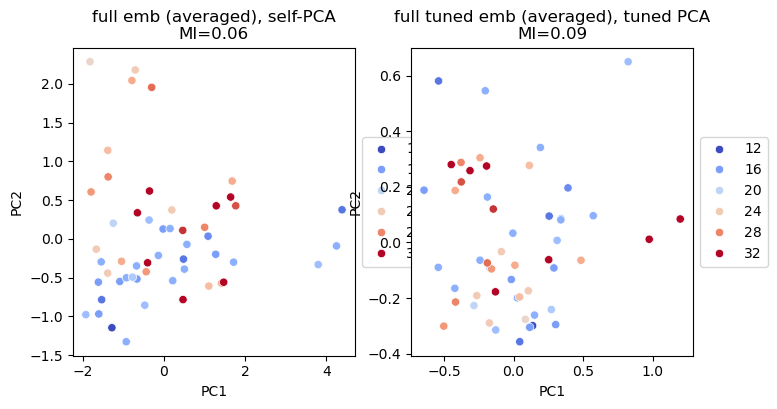

In [108]:
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(1,2,1)
arth_diff = arth_full_embeddings #(arth_full_embeddings - arth_full_tuned_embeddings)
diff_pca = PCA(n_components=5)
X = pd.DataFrame(arth_diff.mean(axis=1))
pca_comp = diff_pca.fit_transform(X)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, pca_comp.shape[1]+1)])
plotdf['temp'] = unscale_ogts(arth_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
mi = calculate_morans_i(pca_comp, arth_temps)
ax.set_title(f'full emb (averaged), self-PCA\nMI={mi:.2f}')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

ax = fig.add_subplot(1,2,2)
arth_diff = arth_full_tuned_embeddings #(arth_full_embeddings - arth_full_tuned_embeddings)
diff_pca = PCA(n_components=5)
X = pd.DataFrame(arth_diff.mean(axis=1))
pca_comp = diff_pca.fit_transform(X)
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, pca_comp.shape[1]+1)])
plotdf['temp'] = unscale_ogts(arth_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
mi = calculate_morans_i(pca_comp[:, :2], arth_temps)
ax.set_title(f'full tuned emb (averaged), tuned PCA\nMI={mi:.2f}')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

In [1657]:
pca_comp[:, :2].shape

(53, 2)

In [1320]:
per_col_pca = []
per_col_mi = []
for col in tqdm(range(1, even_full_embeddings.shape[1])):
    
    _pca = PCA(n_components=5)
    pca_results = _pca.fit_transform(np.array(tuned_even_full_embeddings[:, col, :]))
    per_col_pca.append(_pca)
    per_col_mi.append(calculate_morans_i(pca_results[:, :2], even_temps))
    

100%|█████████████████████████████████████████| 182/182 [00:41<00:00,  4.35it/s]


In [1409]:
myco_per_col, arth_per_col = [], []
for col in tqdm(range(even_full_embeddings.shape[1]-1)):
    
    myco_per_col.append(calculate_morans_i(per_col_pca[col].transform(myco_full_tuned_embeddings[:, col+1, :])[:, :2], myco_temps))
    arth_per_col.append(calculate_morans_i(per_col_pca[col].transform(arth_full_tuned_embeddings[:, col+1, :])[:, :2], arth_temps))

100%|████████████████████████████████████████| 182/182 [00:00<00:00, 924.92it/s]


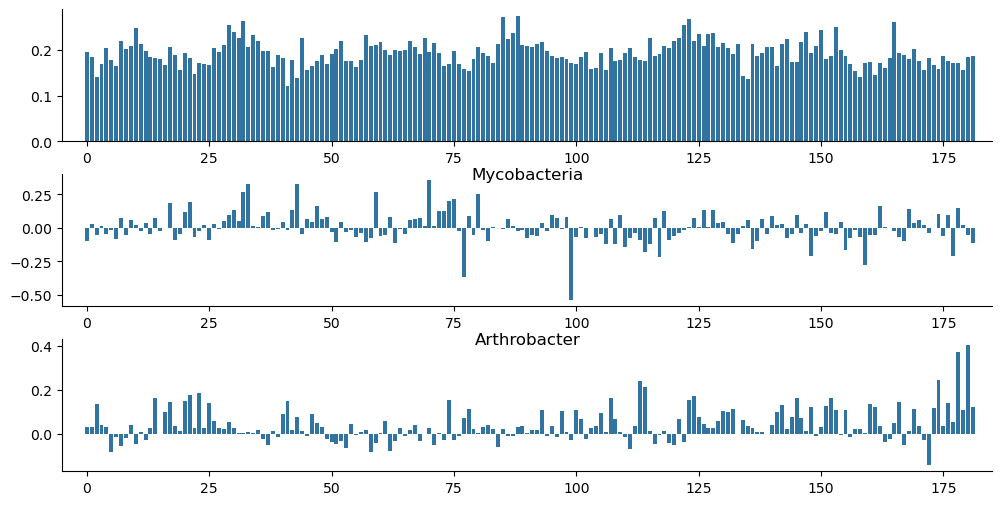

In [1410]:
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(3,1,1)
sns.barplot(per_col_mi)
xticks = ax.set_xticks(list(range(0, 185, 25)))

sns.despine()

ax = fig.add_subplot(3,1,2, sharex=ax)
sns.barplot(myco_per_col)
xticks = ax.set_xticks(list(range(0, 185, 25)))
sns.despine()
ax.set_title('Mycobacteria', y=0.9)

ax = fig.add_subplot(3,1,3, sharex=ax)
sns.barplot(arth_per_col)
xticks = ax.set_xticks(list(range(0, 185, 25)))
sns.despine()
ax.set_title('Arthrobacter', y=0.9)
xlims = ax.set_xlim(-5, 185)
fig.subplots_adjust(hspace=0.25)

#### Notes
It does not appear that the separation is enhanced at the same locations

In [1411]:
np.argmax(myco_per_col)

70

In [1416]:
myco_per_col[70]

0.3555975613302574

In [1376]:
pca_comp.shape[1]

2

Text(0.5, 1.0, 'site 34, tuned w/ tuned PCA, MI=0.36')

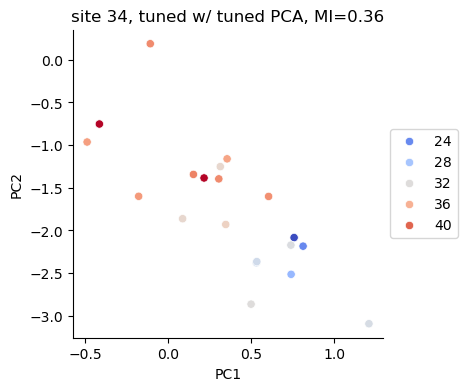

In [1415]:
fig, ax = plt.subplots(figsize=(4,4))
pca_comp = per_col_pca[70].transform(myco_full_tuned_embeddings[:, 71, :])[:, :2]
plotdf = pd.DataFrame(pca_comp, columns=[f'PC{i}' for i in range(1, pca_comp.shape[1]+1)])
plotdf['temp'] = unscale_ogts(myco_temps, scaler)
plotdf = plotdf.sort_values('temp')
sns.scatterplot(data=plotdf, x='PC1', y='PC2', hue='temp', palette='coolwarm')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
mi = calculate_morans_i(pca_comp, myco_temps)
ax.set_title(f'site 34, tuned w/ tuned PCA, MI={mi:.2f}')

In [1417]:
pc1_loadings = []
for curr_pca in per_col_pca:
    loadings = curr_pca.components_.T * np.sqrt(curr_pca.explained_variance_)
    pc1_loadings.append(loadings[:, 0])

pc1_loadings = np.array(pc1_loadings)

pc1_loadings.shape

(182, 768)

In [1418]:
per_res_ss = per_res_data.reset_index().groupby('aln_res').apply(lambda x: x['secondary_structure'].value_counts()).unstack()
per_res_ss.loc[:, 'E'].fillna(0)

aln_res
0.0      1320.0
1.0      7445.0
2.0      8132.0
3.0      8082.0
4.0      7993.0
          ...  
177.0       0.0
178.0       0.0
179.0       0.0
180.0       0.0
181.0       0.0
Name: E, Length: 182, dtype: float64

In [1418]:
per_res_ss = per_res_data.reset_index().groupby('aln_res').apply(lambda x: x['secondary_structure'].value_counts()).unstack()
per_res_ss.loc[:, 'E'].fillna(0)

aln_res
0.0      1320.0
1.0      7445.0
2.0      8132.0
3.0      8082.0
4.0      7993.0
          ...  
177.0       0.0
178.0       0.0
179.0       0.0
180.0       0.0
181.0       0.0
Name: E, Length: 182, dtype: float64

In [1419]:
stat = 'sasa'
cmap = mpl.colormaps['Blues']
norm = mpl.colors.Normalize(per_res_means[stat].min(), per_res_means[stat].max())
row_colors = per_res_means[stat].apply(norm).apply(cmap).apply(to_hex)

In [1420]:
# stat = 'fa_sol'
# cmap = mpl.colormaps['Blues']
# e_counts =  per_res_ss.loc[:, 'E'].fillna(0)
# norm = mpl.colors.Normalize(e_counts.min(), e_counts.max())
# row_colors = e_counts.apply(norm).apply(cmap).apply(to_hex)

In [1446]:
from scipy.cluster.hierarchy import dendrogram, fcluster

Cluster assignments for each row: 
[2 1 1 ... 2 2 2]


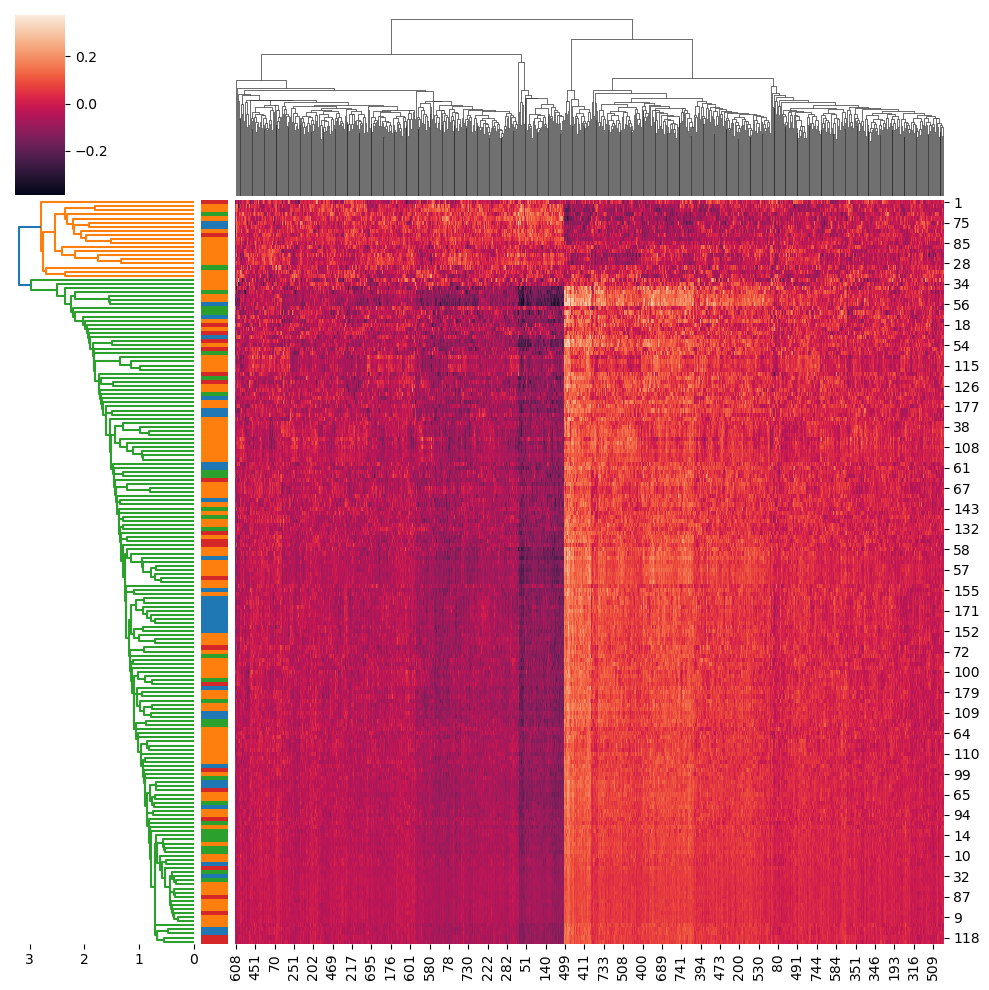

In [1460]:
g = sns.clustermap(pc1_loadings, row_colors=row_colors.values)

# 2. Define your distance cutoff
cutoff = 3

# 3. Get the linkage matrix from the clustermap object
linkage = g.dendrogram_row.linkage

# 4. Draw the cutoff line on the row dendrogram ax
g.ax_row_dendrogram.axvline(x=cutoff, color='red', linestyle='--')

# 5. Recolor the dendrogram
# We use dendrogram() with color_threshold to get the new colors
# then we must clear and re-plot on the existing axis
g.ax_row_dendrogram.clear()
dendrogram(linkage, color_threshold=cutoff, orientation='left', 
           ax=g.ax_row_dendrogram, no_labels=True)

g.ax_row_dendrogram.set_ylim(g.ax_row_dendrogram.get_ylim()[::-1])

# 6. Get cluster assignments for the rows
clusters = fcluster(linkage, t=cutoff, criterion='distance')
print(f"Cluster assignments for each row: \n{clusters}")

plt.show()

In [1462]:
len(clusters)

182

In [1465]:
pos_group = [i for i in range(len(clusters)) if clusters[i] == 1]

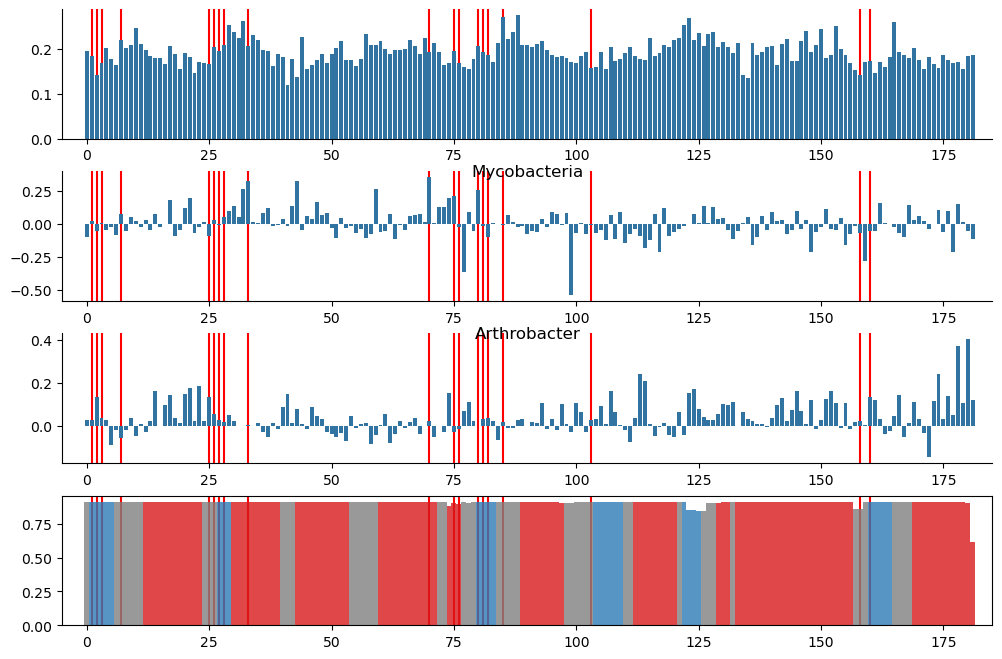

In [1466]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(4,1,1)
sns.barplot(per_col_mi)
xticks = ax.set_xticks(list(range(0, 185, 25)))
for p in pos_group:
    ax.axvline(p, color='r', zorder=0)
sns.despine()

ax = fig.add_subplot(4,1,2, sharex=ax)
sns.barplot(myco_per_col)
xticks = ax.set_xticks(list(range(0, 185, 25)))
for p in pos_group:
    ax.axvline(p, color='r', zorder=0)
sns.despine()
ax.set_title('Mycobacteria', y=0.9)

ax = fig.add_subplot(4,1,3, sharex=ax)
sns.barplot(arth_per_col)
xticks = ax.set_xticks(list(range(0, 185, 25)))
sns.despine()
ax.set_title('Arthrobacter', y=0.9)
xlims = ax.set_xlim(-5, 185)
for p in pos_group:
    ax.axvline(p, color='r', zorder=0)

ax = fig.add_subplot(4,1,4, sharex=ax)
ax.bar(grouped['aln_res'], (per_res_data['aln_res'].value_counts() / len(per_res_data.index.get_level_values(0).unique())).sort_index(),
       color=grouped['ss_color'], width=1, alpha=0.8, zorder=1)
for p in pos_group:
    ax.axvline(p, color='r', zorder=0)

    
fig.subplots_adjust(hspace=0.25)

In [1422]:
pc2_loadings = []
for curr_pca in per_col_pca:
    loadings = curr_pca.components_.T * np.sqrt(curr_pca.explained_variance_)
    pc2_loadings.append(loadings[:, 1])

pc2_loadings = np.array(pc2_loadings)

pc2_loadings.shape

(182, 768)

In [1434]:
per_res_aa = per_res_data.reset_index().groupby('aln_res').apply(lambda x: x['resname'].value_counts().head(1)).reset_index()
per_res_aa.head()

aa_properties = {
    # Nonpolar / Hydrophobic
    'MET': 'Nonpolar', 'LEU': 'Nonpolar', 'ILE': 'Nonpolar', 
    'GLY': 'Nonpolar', 'PRO': 'Nonpolar', 'ALA': 'Nonpolar', 
    'VAL': 'Nonpolar', 'PHE': 'Nonpolar',
    
    # Polar Uncharged
    'THR': 'Polar', 'GLN': 'Polar', 'TYR': 'Polar', 
    'SER': 'Polar', 'CYS': 'Polar', 'ASN': 'Polar',
    
    # Charged
    'ARG': 'Positive', 'LYS': 'Positive', 'HIS': 'Positive',
    'GLU': 'Negative', 'ASP': 'Negative'
}

In [1442]:
stat = 'fa_sol'
cmap = mpl.colormaps['tab20']
# e_counts =  per_res_ss.loc[:, 'E'].fillna(0)
mapper = dict((a, to_hex(c)) for a, c in zip(set(aa_properties.values()), sns.color_palette('tab10', n_colors=len(set(aa_properties.values())))))
# norm = mpl.colors.Normalize(e_counts.min(), e_counts.max())

row_colors = per_res_aa.sort_values('aln_res')['resname'].map(aa_properties).map(mapper)

In [1443]:
row_colors

0      #ff7f0e
1      #d62728
2      #ff7f0e
3      #ff7f0e
4      #ff7f0e
        ...   
177    #ff7f0e
178    #ff7f0e
179    #ff7f0e
180    #ff7f0e
181    #1f77b4
Name: resname, Length: 182, dtype: object

Cluster assignments for each row: 
[17 22 22 ... 17 17 17]


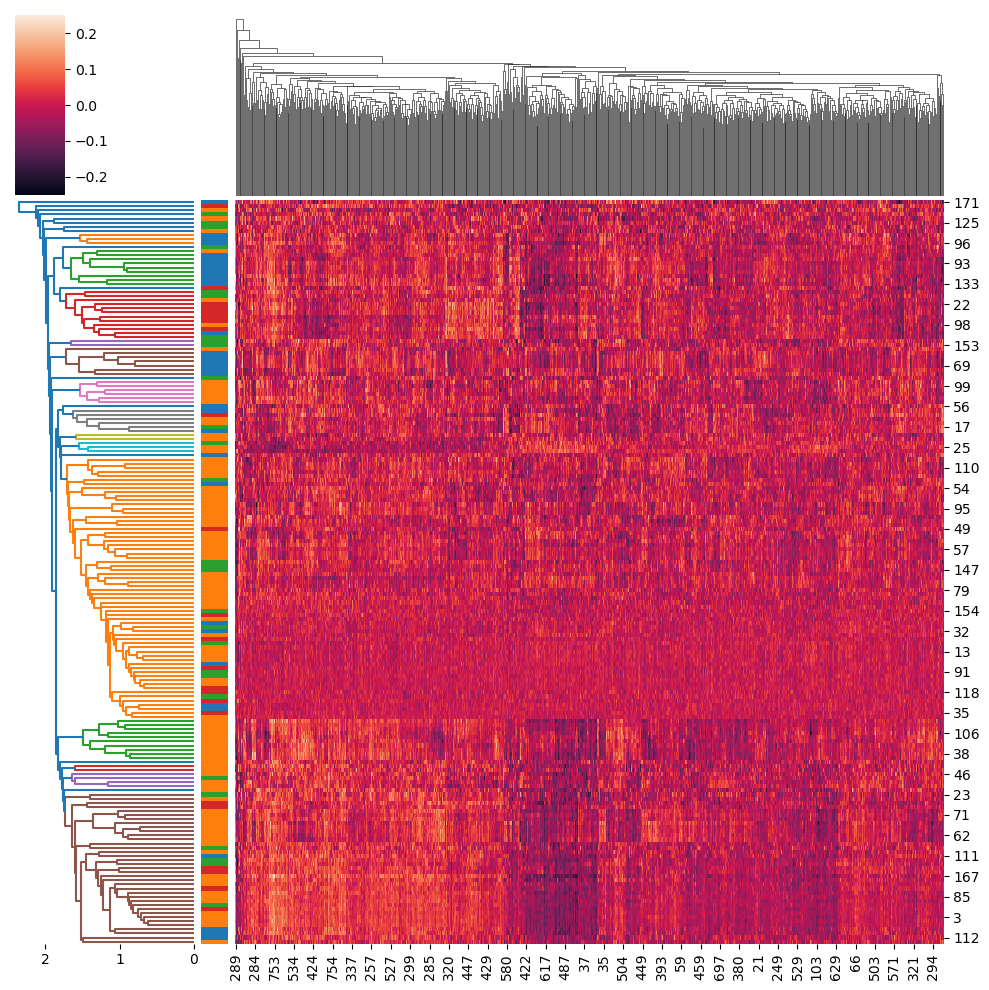

In [1470]:
g = sns.clustermap(pc2_loadings, row_colors=row_colors.values)

# 2. Define your distance cutoff
cutoff = 1.75

# 3. Get the linkage matrix from the clustermap object
linkage = g.dendrogram_row.linkage

# 4. Draw the cutoff line on the row dendrogram ax
g.ax_row_dendrogram.axvline(x=cutoff, color='red', linestyle='--')

# 5. Recolor the dendrogram
# We use dendrogram() with color_threshold to get the new colors
# then we must clear and re-plot on the existing axis
g.ax_row_dendrogram.clear()
dendrogram(linkage, color_threshold=cutoff, orientation='left', 
           ax=g.ax_row_dendrogram, no_labels=True)

g.ax_row_dendrogram.set_ylim(g.ax_row_dendrogram.get_ylim()[::-1])

# 6. Get cluster assignments for the rows
clusters = fcluster(linkage, t=cutoff, criterion='distance')
print(f"Cluster assignments for each row: \n{clusters}")

plt.show()

In [1484]:
pos_colors = dict((c, co) for c, co in zip(np.unique(clusters), sns.color_palette('gist_rainbow', n_colors=len(np.unique(clusters)))))

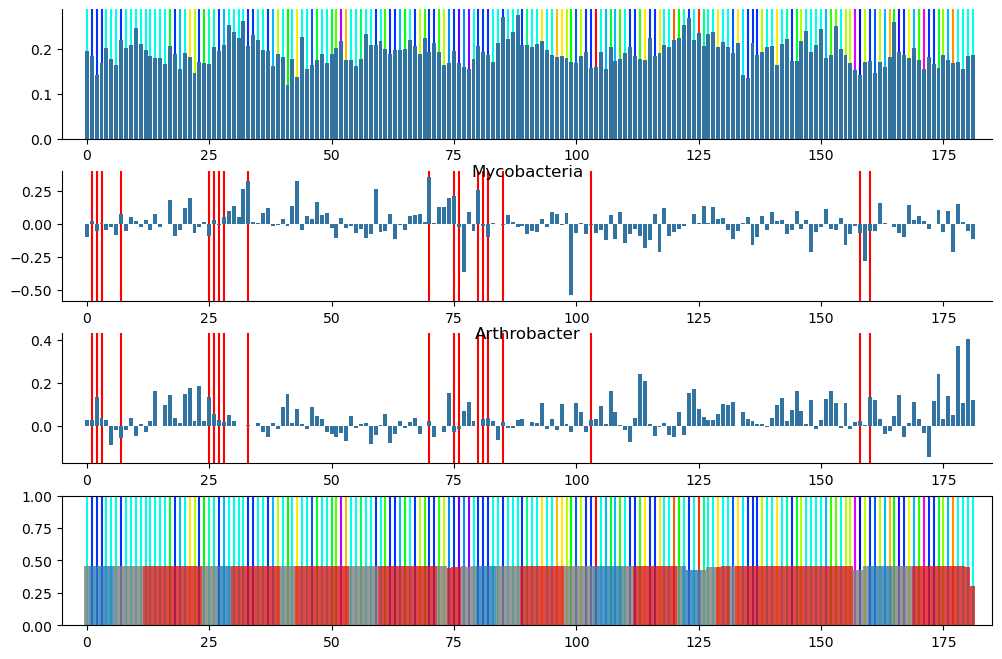

In [1486]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(4,1,1)
sns.barplot(per_col_mi)
xticks = ax.set_xticks(list(range(0, 185, 25)))
for i, c in enumerate(clusters):
    ax.axvline(i, color=pos_colors[c], zorder=0)
sns.despine()

ax = fig.add_subplot(4,1,2, sharex=ax)
sns.barplot(myco_per_col)
xticks = ax.set_xticks(list(range(0, 185, 25)))
for p in pos_group:
    ax.axvline(p, color='r', zorder=0)
sns.despine()
ax.set_title('Mycobacteria', y=0.9)

ax = fig.add_subplot(4,1,3, sharex=ax)
sns.barplot(arth_per_col)
xticks = ax.set_xticks(list(range(0, 185, 25)))
sns.despine()
ax.set_title('Arthrobacter', y=0.9)
xlims = ax.set_xlim(-5, 185)
for p in pos_group:
    ax.axvline(p, color='r', zorder=0)

ax = fig.add_subplot(4,1,4, sharex=ax)
ax.bar(grouped['aln_res'], (per_res_data['aln_res'].value_counts() / len(per_res_data.index.get_level_values(0).unique())).sort_index() / 2,
       color=grouped['ss_color'], width=1, alpha=0.8, zorder=1)
for i, c in enumerate(clusters):
    ax.axvline(i, color=pos_colors[c], zorder=0)
ax.set_ylim(0, 1)

    
fig.subplots_adjust(hspace=0.25)

In [ ]:
for col in tqdm(range(1, even_full_embeddings.shape[1])):
    
    
    pca_results = per_col_pca[col].transform(np.array(tuned_even_full_embeddings[:, col, :]))

# Mara2023 figure

In [654]:
dataset = 'Mara2023'

(25, 6)

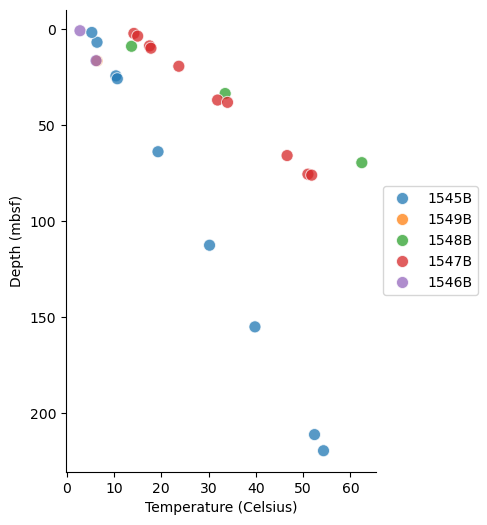

In [655]:
# plot of depth vs temp
collated_md = pd.read_csv('./../data/validation_datasets/Mara2023/md/collated_md.tsv', sep='\t')

collated_md.head()

collated_md['site'] = collated_md['sample'].apply(lambda x: x.split('_')[0])

fig, ax = plt.subplots(figsize=(4,6))
sns.scatterplot(data=collated_md, x='Temperature (Celsius)', y='Depth (mbsf)', 
                hue='site', s=75, alpha=0.75)
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_yticks(list(range(200, -1, -50)))
ax.invert_yaxis()
sns.despine()

collated_md.shape

In [656]:
adk_files = glob.glob(f'./../data/validation_datasets/{dataset}/genomes/*_final/*_adk.faa')
seq2sample = pd.Series()
for f in adk_files:
    with open(f, 'r') as handle:
        records = [r for r in SeqIO.parse(handle, format='fasta')]
    for r in records:
        seq2sample.loc[r.id] = f.split('/')[-2].replace('_final', '')

In [657]:
# get unique sequences
derep = pd.read_csv(f'./../data/validation_datasets/{dataset}/derep_adks_cluster.tsv', sep='\t', header=None, names=['rep', 'member'])
full_derep = pd.merge(derep, seq2sample.rename('member_sample'), left_on='member', right_index=True, how='left')

unique_reps = list(full_derep['rep'].unique())
rep_map = dict((rep, unique_reps.index(rep)) for rep in full_derep['rep'].values)

full_derep.head()

full_derep['cluster'] = full_derep['rep'].map(rep_map)
full_derep.head()

,rep,member,member_sample,cluster
0,NODE_11_length_95317_cov_33.719636_52|scaffold...,NODE_11_length_95317_cov_33.719636_52|scaffold...,SRR22580794,0
1,NODE_11_length_95317_cov_33.719636_52|scaffold...,NODE_2012_length_9813_cov_7.741033_12|scaffold...,SRR22580799,0
2,NODE_11_length_95317_cov_33.719636_52|scaffold...,NODE_25_length_102551_cov_25.271981_55|scaffol...,SRR22580806,0
3,NODE_11_length_95317_cov_33.719636_52|scaffold...,NODE_36_length_54866_cov_19.285454_44|scaffold...,SRR23614670,0
4,NODE_161_length_35626_cov_13.930140_44|scaffol...,NODE_161_length_35626_cov_13.930140_44|scaffol...,SRR22580794,1


In [658]:
model = 'even_lm_ind'

curr_scores = pd.read_csv(f'./../data/validation_datasets/prediction_results/{dataset}_full_test_scores.tsv', sep='\t')
curr_preds = pd.read_csv(f'./../data/validation_datasets/prediction_results/{dataset}_full_test_preds.tsv', sep='\t', index_col=0)
subset = curr_preds[curr_preds['model_label'].eq(model)]

In [659]:
plotdf = pd.merge(subset, full_derep, 
         left_on='protein', right_on='member', how='left')

In [660]:
plotdf_grouped = plotdf.groupby('cluster').agg({'actual':'first', 'prediction':'mean', 'env temp':'first', 'sample_or_genome':'first'})
plotdf_grouped.head()

,actual,prediction,env temp,sample_or_genome
cluster,,,,
0,10.4,24.328998,10.4,SRR22580794
1,10.4,44.076091,10.4,SRR22580794
2,10.4,50.612708,10.4,SRR22580794
3,10.4,38.278439,10.4,SRR22580794
4,10.4,47.443389,10.4,SRR22580794


In [661]:
per_sample = plotdf_grouped.groupby('sample_or_genome').agg(mean_predicted=('prediction', 'mean'),
                                       std_predicted=('prediction', 'std'),
                                       actual=('env temp', 'first'))

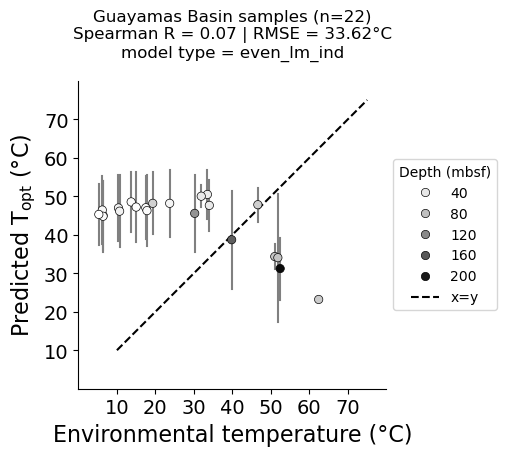

In [662]:
fig, ax = plt.subplots(figsize=(4,4))
sns.scatterplot(data=per_sample, x='actual', y='mean_predicted', edgecolor='k',
                hue=collated_md.set_index('Run')['Depth (mbsf)'], palette='Grays', zorder=2)

for index, row in per_sample.iterrows():
    ax.plot((row['actual'], row['actual']),
            (row['mean_predicted']-row['std_predicted'], row['mean_predicted']+row['std_predicted']), zorder=1, color='gray')

sns.despine()
ax.set_aspect('equal')
# axis
_lower, _upper = 0, 80
# ticks
tick_lower, tick_upper = 10, 80
tick_interval = 10
# line 
line_lower, line_upper = 10, 75

ax.set_xlim(_lower, _upper)
ax.set_ylim(_lower, _upper)
ticks = list(range(tick_lower, tick_upper, tick_interval))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.tick_params(labelsize=14, axis='both')

plt.plot((line_lower, line_upper), 
         (line_lower, line_upper), 
         'k--', label='x=y', zorder=0)

ax.set_ylabel('Predicted $\mathregular{T_{opt}}$ (°C)', fontsize=16)
ax.set_xlabel('Environmental temperature (°C)', fontsize=16)

spr = curr_scores[curr_scores.model_label.eq(model)].iloc[0, 2]
mse = curr_scores[curr_scores.model_label.eq(model)].iloc[0, 3]
ax.set_title(f'Guayamas Basin samples (n={len(per_sample)})\nSpearman R = {spr:.2f} | RMSE = {mse:.2f}°C\nmodel type = {model}',
            y=1.05)

lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='Depth (mbsf)')

In [663]:
plotdf_grouped.head()

,actual,prediction,env temp,sample_or_genome
cluster,,,,
0,10.4,24.328998,10.4,SRR22580794
1,10.4,44.076091,10.4,SRR22580794
2,10.4,50.612708,10.4,SRR22580794
3,10.4,38.278439,10.4,SRR22580794
4,10.4,47.443389,10.4,SRR22580794


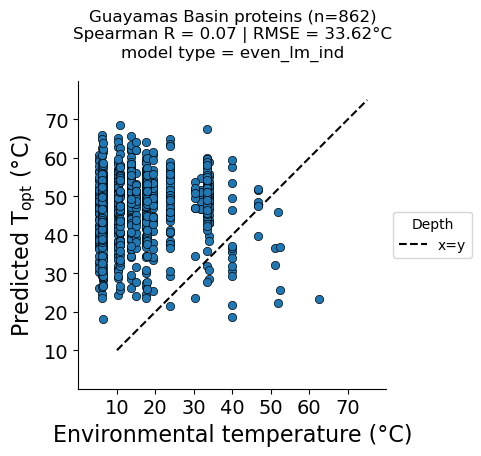

In [664]:
fig, ax = plt.subplots(figsize=(4,4))
sns.scatterplot(data=plotdf_grouped, x='actual', y='prediction', edgecolor='k',
                zorder=2)

# for index, row in per_sample.iterrows():
#     ax.plot((row['actual'], row['actual']),
#             (row['mean_predicted']-row['std_predicted'], row['mean_predicted']+row['std_predicted']), zorder=1, color='gray')

sns.despine()
ax.set_aspect('equal')
# axis
_lower, _upper = 0, 80
# ticks
tick_lower, tick_upper = 10, 80
tick_interval = 10
# line 
line_lower, line_upper = 10, 75

ax.set_xlim(_lower, _upper)
ax.set_ylim(_lower, _upper)
ticks = list(range(tick_lower, tick_upper, tick_interval))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.tick_params(labelsize=14, axis='both')

plt.plot((line_lower, line_upper), 
         (line_lower, line_upper), 
         'k--', label='x=y', zorder=0)

ax.set_ylabel('Predicted $\mathregular{T_{opt}}$ (°C)', fontsize=16)
ax.set_xlabel('Environmental temperature (°C)', fontsize=16)

spr = curr_scores[curr_scores.model_label.eq(model)].iloc[0, 2]
mse = curr_scores[curr_scores.model_label.eq(model)].iloc[0, 3]
ax.set_title(f'Guayamas Basin proteins (n={len(plotdf_grouped)})\nSpearman R = {spr:.2f} | RMSE = {mse:.2f}°C\nmodel type = {model}',
            y=1.05)

lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='Depth')

# Salazar2019 figure

In [665]:
dataset = 'Salazar2019'

In [666]:
adk_files = glob.glob(f'./../data/validation_datasets/{dataset}/genomes/*_final/*_adk.faa')
seq2sample = pd.Series()
for f in adk_files:
    with open(f, 'r') as handle:
        records = [r for r in SeqIO.parse(handle, format='fasta')]
    for r in records:
        seq2sample.loc[r.id] = f.split('/')[-2].replace('_final', '')

In [667]:
# get unique sequences
derep = pd.read_csv(f'./../data/validation_datasets/{dataset}/derep_adks_cluster.tsv', sep='\t', header=None, names=['rep', 'member'])
full_derep = pd.merge(derep, seq2sample.rename('member_sample'), left_on='member', right_index=True, how='left')

unique_reps = list(full_derep['rep'].unique())
rep_map = dict((rep, unique_reps.index(rep)) for rep in full_derep['rep'].values)

full_derep.head()

full_derep['cluster'] = full_derep['rep'].map(rep_map)
full_derep.head()

,rep,member,member_sample,cluster
0,NODE_137800_length_770_cov_1.882517_1|scaffold...,NODE_137800_length_770_cov_1.882517_1|scaffold...,ERR315859,0
1,NODE_138346_length_768_cov_2.258065_1|scaffold...,NODE_138346_length_768_cov_2.258065_1|scaffold...,ERR315859,1
2,NODE_138346_length_768_cov_2.258065_1|scaffold...,NODE_32835_length_1420_cov_2.887912_3|scaffold...,ERR598951,1
3,NODE_138990_length_766_cov_2.112518_1|scaffold...,NODE_138990_length_766_cov_2.112518_1|scaffold...,ERR315859,2
4,NODE_144004_length_751_cov_0.840517_1|scaffold...,NODE_144004_length_751_cov_0.840517_1|scaffold...,ERR315859,3


In [668]:
curr_scores['model_label'].unique()

array(['corkrey_lm_ind', 'corkrey_lm_ind_tuned_means',
       'corkrey_lm_ind_tuned_pca', 'corkrey_lm_means',
       'corkrey_lm_tuned_ind', 'corkrey_lm_tuned_means',
       'corkrey_lm_tuned_pca', 'corkrey_nn_ind',
       'corkrey_nn_ind_tuned_means', 'corkrey_nn_means',
       'corkrey_nn_tuned_means', 'corkrey_rf_means',
       'corkrey_rf_tuned_means', 'corkrey_rf_tuned_pca',
       'corkrey_svr_means', 'corkrey_svr_tuned_means',
       'corkrey_svr_tuned_pca', 'even_lm_ind', 'even_lm_means',
       'even_nn_ind', 'even_nn_means', 'even_rf_means', 'even_svr_means'],
      dtype=object)

In [669]:
model = 'even_lm_ind'

curr_scores = pd.read_csv(f'./../data/validation_datasets/prediction_results/{dataset}_full_test_scores.tsv', sep='\t')
curr_preds = pd.read_csv(f'./../data/validation_datasets/prediction_results/{dataset}_full_test_preds.tsv', sep='\t', index_col=0)
subset = curr_preds[curr_preds['model_label'].eq(model)]

In [670]:
plotdf = pd.merge(subset, full_derep, 
         left_on='protein', right_on='member', how='left')
print(plotdf.shape)
plotdf.head()

(5486, 11)


,prediction,actual,protein,model_label,dataset,sample_or_genome,env temp,rep,member,member_sample,cluster
0,30.803453,3.824545,NODE_7_length_274068_cov_6.338637_145|scaffold...,even_lm_ind,Salazar2019,ERR3589565,3.824545,NODE_7_length_274068_cov_6.338637_145|scaffold...,NODE_7_length_274068_cov_6.338637_145|scaffold...,ERR3589565,11
1,4.520048,3.824545,NODE_9_length_244561_cov_7.487370_171|scaffold...,even_lm_ind,Salazar2019,ERR3589565,3.824545,NODE_9_length_244561_cov_7.487370_171|scaffold...,NODE_9_length_244561_cov_7.487370_171|scaffold...,ERR3589565,12
2,21.079231,3.824545,NODE_25_length_172575_cov_16.520687_103|scaffo...,even_lm_ind,Salazar2019,ERR3589565,3.824545,NODE_25_length_172575_cov_16.520687_103|scaffo...,NODE_25_length_172575_cov_16.520687_103|scaffo...,ERR3589565,13
3,18.212347,3.824545,NODE_33_length_153415_cov_143.425241_21|scaffo...,even_lm_ind,Salazar2019,ERR3589565,3.824545,NODE_33_length_153415_cov_143.425241_21|scaffo...,NODE_33_length_153415_cov_143.425241_21|scaffo...,ERR3589565,14
4,23.578238,3.824545,NODE_75_length_112530_cov_23.833990_46|scaffol...,even_lm_ind,Salazar2019,ERR3589565,3.824545,NODE_75_length_112530_cov_23.833990_46|scaffol...,NODE_75_length_112530_cov_23.833990_46|scaffol...,ERR3589565,15


In [671]:
plotdf_grouped = plotdf.groupby('cluster').agg({'actual':'first', 'prediction':'mean', 'env temp':'first', 'sample_or_genome':'first'})
plotdf_grouped.head()

,actual,prediction,env temp,sample_or_genome
cluster,,,,
7,3.824545,28.968726,3.824545,ERR3589565
11,3.824545,29.600610,3.824545,ERR3589565
12,3.824545,4.520048,3.824545,ERR3589565
13,3.824545,21.079231,3.824545,ERR3589565
14,3.824545,21.340379,3.824545,ERR3589565


In [672]:
per_sample = plotdf_grouped.groupby('sample_or_genome').agg(mean_predicted=('prediction', 'mean'),
                                       std_predicted=('prediction', 'std'),
                                       actual=('env temp', 'first'))

per_sample.head()

,mean_predicted,std_predicted,actual
sample_or_genome,,,
ERR3589565,23.010566,7.668956,3.824545
ERR3589566,22.414135,8.071311,-0.160312
ERR3589568,22.728438,8.702051,2.507887
ERR598943,27.091106,7.199686,24.958885
ERR598945,19.411880,6.432197,1.903400


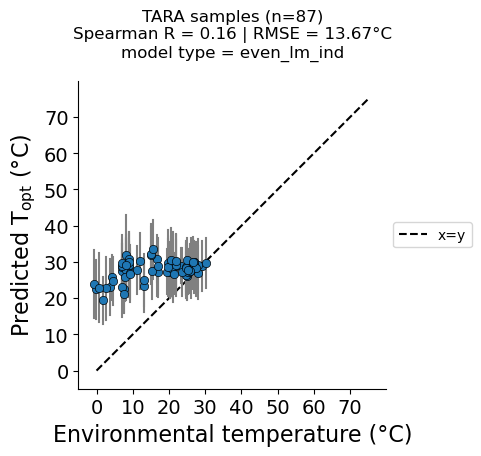

In [673]:
fig, ax = plt.subplots(figsize=(4,4))
sns.scatterplot(data=per_sample, x='actual', y='mean_predicted', edgecolor='k', zorder=2)

for index, row in per_sample.iterrows():
    ax.plot((row['actual'], row['actual']),
            (row['mean_predicted']-row['std_predicted'], row['mean_predicted']+row['std_predicted']), zorder=1, color='gray')

sns.despine()
ax.set_aspect('equal')
# axis
_lower, _upper = -5, 80
# ticks
tick_lower, tick_upper = 0, 80
tick_interval = 10
# line 
line_lower, line_upper = 0, 75

ax.set_xlim(_lower, _upper)
ax.set_ylim(_lower, _upper)
ticks = list(range(tick_lower, tick_upper, tick_interval))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.tick_params(labelsize=14, axis='both')

plt.plot((line_lower, line_upper), 
         (line_lower, line_upper), 
         'k--', label='x=y', zorder=0)

ax.set_ylabel('Predicted $\mathregular{T_{opt}}$ (°C)', fontsize=16)
ax.set_xlabel('Environmental temperature (°C)', fontsize=16)

spr = curr_scores[curr_scores.model_label.eq(model)].iloc[0, 2]
mse = curr_scores[curr_scores.model_label.eq(model)].iloc[0, 3]
ax.set_title(f'TARA samples (n={len(per_sample)})\nSpearman R = {spr:.2f} | RMSE = {mse:.2f}°C\nmodel type = {model}',
            y=1.05)

lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

In [446]:
for dataset in ['Antarctic',
                'Arthrobacter',
                'Australia',
                'Colman2024',
                'Conteville2024',
                'Mara2023',
                'Mycobacteria',
                'RoyoLlonch2021',
                'Salazar2019',
                'Shah2024',
                'Youngblut2020']:
    command = f'mafft --thread 16 --keeplength --add ./../../validation_datasets/{dataset}/adks.faa ./../backbone.filtered_only.afa > {dataset}_adk_to_backbone.afa'
    print(command)

mafft --thread 16 --keeplength --add ./../../validation_datasets/Antarctic/adks.faa ./../backbone.filtered_only.afa > Antarctic_adk_to_backbone.afa
mafft --thread 16 --keeplength --add ./../../validation_datasets/Arthrobacter/adks.faa ./../backbone.filtered_only.afa > Arthrobacter_adk_to_backbone.afa
mafft --thread 16 --keeplength --add ./../../validation_datasets/Australia/adks.faa ./../backbone.filtered_only.afa > Australia_adk_to_backbone.afa
mafft --thread 16 --keeplength --add ./../../validation_datasets/Colman2024/adks.faa ./../backbone.filtered_only.afa > Colman2024_adk_to_backbone.afa
mafft --thread 16 --keeplength --add ./../../validation_datasets/Conteville2024/adks.faa ./../backbone.filtered_only.afa > Conteville2024_adk_to_backbone.afa
mafft --thread 16 --keeplength --add ./../../validation_datasets/Mara2023/adks.faa ./../backbone.filtered_only.afa > Mara2023_adk_to_backbone.afa
mafft --thread 16 --keeplength --add ./../../validation_datasets/Mycobacteria/adks.faa ./../back

In [602]:
curr_scores.sort_values('MSE')

,dataset,model_label,SpearmanR,MSE
5,Salazar2019,corkrey_lm_tuned_pca,0.093252,11.954263
7,Salazar2019,corkrey_nn_ind_tuned_means,0.102984,12.664359
2,Salazar2019,corkrey_lm_ind_tuned_pca,0.093105,12.927599
14,Salazar2019,corkrey_svr_tuned_means,0.037071,13.124417
0,Salazar2019,corkrey_lm_ind,0.084370,13.308907
13,Salazar2019,corkrey_svr_means,0.143523,13.630530
16,Salazar2019,even_lm_ind,0.160737,13.666945
15,Salazar2019,corkrey_svr_tuned_pca,0.013138,13.694901
1,Salazar2019,corkrey_lm_ind_tuned_means,0.102565,14.266041
12,Salazar2019,corkrey_rf_tuned_pca,0.028860,14.729572


# Figure of all other metagenomes

In [166]:
scaler = reload_model('./../data/predictive_models/supporting_data/ogt_scaler.pickle')
scaler

StandardScaler()

In [178]:
dataset2label = {'Antarctic':'Antarctic soil', 
                 'Australia':'Australian soil', 
                 'Colman2024':'Hot springs', 
                 'RoyoLlonch2021':'Arctic ocean (TARA)', 
                 'Shah2024':'European freshwater lakes',
                'Youngblut2020':'Avian gut',
                'Conteville2024':'Rumen',
                'Mara2023':'Geothermal sediments',
                'Salazar2019':'Arctic ocean (TARA)'}


In [168]:
datasets = [i.split('/')[-3] for i in glob.glob('./../data/validation_datasets/*/embeddings/')][2:]
datasets

['Antarctic',
 'RoyoLlonch2021',
 'Australia',
 'Shah2024',
 'Colman2024',
 'Conteville2024',
 'Youngblut2020',
 'Salazar2019',
 'Mara2023']

In [169]:
base = './../data/validation_datasets/'
model = f'./../data/predictive_models/even_enetcv_ind.pickle'
model_label = 'even_enetcv_ind'
all_dataset_preds = []

for dataset in datasets:
    print(dataset)
    preds = run_model(embedding_loc=f'{base}{dataset}/embeddings/{dataset}_full_even.pickle',
             model_loc=model,
             msa_loc=f'{base}{dataset}/embeddings/{dataset}_msa_dataset.pickle',
             predict_fn=per_site_predict)

    msa_dataset = reload_model(f'{base}{dataset}/embeddings/{dataset}_msa_dataset.pickle')
    y_pred = pd.Series(data=unscale_ogts(preds.mean(axis=0), scaler),
                       index=[i[0] for i in msa_dataset])
    

    true_temps = pd.read_csv(f'{base}{dataset}/md/{dataset}_env_temps.tsv', sep='\t', index_col=0)
    y_true = true_temps.set_index('protein')['env temp']

    dataset_preds = pd.merge(true_temps.rename(columns={'env temp':'env_temp'}), 
                             y_pred.rename('pred_temp'), 
                             left_on='protein', right_index=True).assign(dataset=dataset)

    all_dataset_preds.append(dataset_preds)


Antarctic


100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 215/215 [00:01<00:00, 109.45it/s]


RoyoLlonch2021


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 215/215 [00:16<00:00, 12.68it/s]


Australia


...

100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 215/215 [00:01<00:00, 168.08it/s]


Salazar2019


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 215/215 [00:12<00:00, 17.49it/s]


Mara2023


100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 215/215 [00:02<00:00, 103.65it/s]


In [170]:
mg_dataset = pd.concat(all_dataset_preds)

In [180]:
mg_dataset['dataset_label'] = mg_dataset['dataset'].map(dataset2label)

In [181]:
mg_dataset.head()

,protein,sample_or_genome,env_temp,pred_temp,dataset,dataset_label
0,NODE_16_length_92306_cov_8.605710_14|scaffolds...,BS610,-30.65,35.262188,Antarctic,Antarctic soil
1,NODE_52_length_46706_cov_18.276008_3|scaffolds...,BS610,-30.65,32.163845,Antarctic,Antarctic soil
2,NODE_56_length_45654_cov_8.929394_45|scaffolds...,BS610,-30.65,36.869431,Antarctic,Antarctic soil
3,NODE_61_length_43867_cov_10.707741_40|scaffold...,BS610,-30.65,29.673172,Antarctic,Antarctic soil
4,NODE_128_length_27827_cov_4.801045_23|scaffold...,BS610,-30.65,33.781708,Antarctic,Antarctic soil


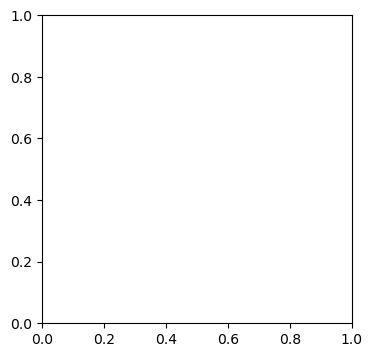

In [182]:
fig, ax = plt.subplots(figsize=(4,4))

# plt.savefig('./../data/figures/20251017_threesample_example.png', dpi=400, bbox_inches='tight')

In [183]:
violin_data = mg_dataset.groupby(['dataset_label', 'sample_or_genome'])[['pred_temp', 'env_temp']].mean().reset_index()

In [184]:
dataset2label.values()

dict_values(['Antarctic soil', 'Australian soil', 'Hot springs', 'Arctic ocean (TARA)', 'European freshwater lakes', 'Avian gut', 'Rumen', 'Geothermal sediments', 'Arctic ocean (TARA)'])

In [313]:
mg_dataset[mg_dataset.dataset_label.eq('Australian soil')]

,protein,sample_or_genome,env_temp,pred_temp,dataset,dataset_label
0,NODE_3158_length_2801_cov_1.389658_2|scaffolds...,10714,17.55267,24.732075,Australia,Australian soil
1,NODE_3427_length_2716_cov_4.868846_2|scaffolds...,10714,17.55267,31.389524,Australia,Australian soil
2,NODE_6928_length_2034_cov_2.804952_1|scaffolds...,10714,17.55267,39.069069,Australia,Australian soil
3,NODE_9829_length_1740_cov_1.804748_1|scaffolds...,10714,17.55267,31.387112,Australia,Australian soil
4,NODE_15715_length_1400_cov_1.133829_2|scaffold...,10714,17.55267,40.987938,Australia,Australian soil
...,...,...,...,...,...,...
763,NODE_41327_length_962_cov_3.771775_2|scaffolds...,138526,13.18646,40.274796,Australia,Australian soil
764,NODE_52409_length_871_cov_2.493873_2|scaffolds...,138526,13.18646,36.461189,Australia,Australian soil
765,NODE_76034_length_749_cov_1.612392_1|scaffolds...,138526,13.18646,32.702232,Australia,Australian soil
766,NODE_98262_length_675_cov_1.638710_1|scaffolds...,138526,13.18646,31.167738,Australia,Australian soil


In [317]:
mg_dataset[mg_dataset.sample_or_genome.isin([10714, 'SRR6323393', 'ERZ7462993', '3300045859'])]['sample_or_genome'].unique()

array(['ERZ7462993', 10714, '3300045859', 'SRR6323393'], dtype=object)

In [320]:
sns.kde-plmg_dataset[mg_dataset.sample_or_genome.isin([10714])]

,protein,sample_or_genome,env_temp,pred_temp,dataset,dataset_label
0,NODE_3158_length_2801_cov_1.389658_2|scaffolds...,10714,17.55267,24.732075,Australia,Australian soil
1,NODE_3427_length_2716_cov_4.868846_2|scaffolds...,10714,17.55267,31.389524,Australia,Australian soil
2,NODE_6928_length_2034_cov_2.804952_1|scaffolds...,10714,17.55267,39.069069,Australia,Australian soil
3,NODE_9829_length_1740_cov_1.804748_1|scaffolds...,10714,17.55267,31.387112,Australia,Australian soil
4,NODE_15715_length_1400_cov_1.133829_2|scaffold...,10714,17.55267,40.987938,Australia,Australian soil
5,NODE_15752_length_1398_cov_1.498883_1|scaffold...,10714,17.55267,37.298565,Australia,Australian soil
6,NODE_16313_length_1375_cov_1.168939_2|scaffold...,10714,17.55267,40.197948,Australia,Australian soil
7,NODE_39779_length_885_cov_2.453012_1|scaffolds...,10714,17.55267,27.261129,Australia,Australian soil


/tmp/ipykernel_3927213/3439307806.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=violin_data,


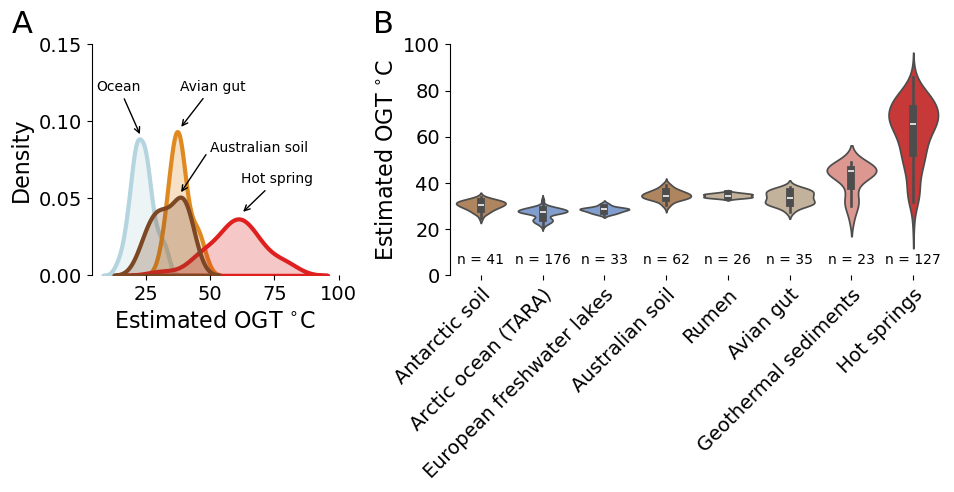

In [524]:
fig= plt.figure(figsize=(11, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 2])
# ---------------------------------- 
# plot 1
# ---------------------------------- 
ax = fig.add_subplot(gs[0])
g = sns.kdeplot(data=mg_dataset[mg_dataset.sample_or_genome.isin([10714, 'SRR6323393', 'ERZ7462993', '3300045859'])], 
                x='pred_temp', hue='dataset_label', #hist=False,
                ax=ax, common_norm=False, 
                palette = [sns.desaturate(i, 0.75) for i in [  'saddlebrown', 'red','darkorange', 'lightblue']],
                hue_order=[ 'Australian soil', 'Hot springs', 'Avian gut', 'Arctic ocean (TARA)'],
                # kde=True, 
            #stat='density',
            fill=True, alpha=0.25, linewidth=3)
ax.set_xlabel('Estimated OGT $^{\circ}$C', fontsize=16)
ax.set_ylabel('Density', fontsize=16)
plt.tick_params(labelsize=14)
ax.get_legend().remove()
# lgd = ax.get_legend()
# lgd._loc = 6
# lgd.set_title('Data source')
# lgd.title_fontsize=16
# lgd.set_bbox_to_anchor((1, 0.5))
ax.set_ylim(0, 0.15)
sns.despine()
ax.annotate('A', (-0.325, 1.05), xycoords='axes fraction', fontsize=22)



ax.annotate('Hot spring', xy=(62, 0.04), 
            xytext=(62, 0.06),
            xycoords='data', textcoords='data', arrowprops={'arrowstyle':'->'})

ax.annotate('Australian soil', xy=(38, 0.0525), 
            xytext=(50, 0.08),
            xycoords='data', textcoords='data', arrowprops={'arrowstyle':'->',
                                                           'relpos':(0, 0.5)},
           ha='left')

ax.annotate('Avian gut', xy=(38, 0.095), 
            xytext=(38, 0.12),
            xycoords='data', textcoords='data', arrowprops={'arrowstyle':'->'})

ax.annotate('Ocean', xy=(23, 0.09), 
            xytext=(23, 0.12),
            ha='right',
            xycoords='data', textcoords='data', arrowprops={'arrowstyle':'->'})


# ---------------------------------- 
# plot 2
# ---------------------------------- 
ax = fig.add_subplot(gs[1])

# violin_data = mg_dataset[~(mg_dataset['dataset_label'].eq('Hot spring genome assemblies') & \
#                             (mg_dataset['pred_temp'] < 40))].groupby(['dataset_label', 'sample_or_genome'])[['pred_temp', 'env_temp']].mean().reset_index()
x_order = ['Antarctic soil', 'Arctic ocean (TARA)', 
                                                          'European freshwater lakes', 'Australian soil', 
                                                          'Rumen', 'Avian gut',  'Geothermal sediments', 'Hot springs']
sns.violinplot(data=violin_data,
               y='pred_temp', x='dataset_label', order=x_order,
              palette=[sns.desaturate(i, 0.75) for i in ['peru', 'cornflowerblue', 'cornflowerblue', 'peru', 'tan', 'tan', 'salmon', 'red']],
               legend=False)

# sns.violinplot(data=dataset,
#                x='env temp', y='dataset_label', order=['Antarctic soil', 'Arctic ocean (TARA)', 
#                                                           'European freshwater lakes', 'Australian soil', 
#                                                           'Bovine microbiomes', 'Avian microbiomes', 'Hot spring genome assemblies'])

plt.tick_params(labelsize=14)
plt.tick_params(axis='x', rotation=45)
ax.set_ylabel('Estimated OGT $^{\circ}$C', fontsize=16)
ax.set_xlabel('')

for label in ax.get_xticklabels():
    label.set_rotation(45)
    label.set_ha('right')           # anchor to right end
    label.set_rotation_mode('anchor')  # rotate around the anchored point

for i, (label, count) in enumerate(mg_dataset.groupby('dataset_label').apply(lambda x: len(x['sample_or_genome'].unique())).reindex(index=x_order).items()):
    ax.annotate(f'n = {count}', (i, 5), ha='center')
    
# ax.set_yscale('log')
ax.set_ylim(0, 100)
# ax.set_yticks([])
# ax.set_yticks(list(np.logspace(1, 2, 5)))
sns.despine(bottom=True)
ax.annotate('B', (-0.155, 1.05), xycoords='axes fraction', fontsize=22)

fig.subplots_adjust(wspace=0.3)
plt.savefig('./../data/figures/finalized_figures/figure_5_mg_summary.svg', bbox_inches='tight')
plt.savefig('./../data/figures/finalized_figures/figure_5_mg_summary.png', dpi=400, bbox_inches='tight')

In [519]:
len(mg_dataset[mg_dataset['dataset_label'].eq('Geothermal sediments')]['sample_or_genome'].unique())

23

In [520]:
for i, (label, count) in enumerate(mg_dataset.groupby('dataset_label').apply(lambda x: len(x['sample_or_genome'].unique())).items()):
    print(i, label, count)
    # ax.annotate(f'n = {count}', (i, 5), ha='center')

0 Antarctic soil 41
1 Arctic ocean (TARA) 176
2 Australian soil 62
3 Avian gut 35
4 European freshwater lakes 33
5 Geothermal sediments 23
6 Hot springs 127
7 Rumen 26


In [522]:
mg_dataset.groupby('dataset_label').apply(lambda x: len(x['sample_or_genome'].unique())).reindex(x_order)

NameError: name 'x_order' is not defined

In [208]:
['Arctic ocean (TARA)', 'Avian gut', 'Hot springs'][::-1]

['Hot springs', 'Avian gut', 'Arctic ocean (TARA)']

In [219]:
mg_dataset[mg_dataset.sample_or_genome.isin(['SRR6323393', 'ERZ7462993', '3300045859'])].groupby('sample_or_genome').agg({'pred_temp':'mean'})

,pred_temp
sample_or_genome,
3300045859,59.879341
ERZ7462993,23.349592
SRR6323393,38.284401


In [218]:
mg_dataset

,protein,sample_or_genome,env_temp,pred_temp,dataset,dataset_label
0,NODE_16_length_92306_cov_8.605710_14|scaffolds...,BS610,-30.65,35.262188,Antarctic,Antarctic soil
1,NODE_52_length_46706_cov_18.276008_3|scaffolds...,BS610,-30.65,32.163845,Antarctic,Antarctic soil
2,NODE_56_length_45654_cov_8.929394_45|scaffolds...,BS610,-30.65,36.869431,Antarctic,Antarctic soil
3,NODE_61_length_43867_cov_10.707741_40|scaffold...,BS610,-30.65,29.673172,Antarctic,Antarctic soil
4,NODE_128_length_27827_cov_4.801045_23|scaffold...,BS610,-30.65,33.781708,Antarctic,Antarctic soil
...,...,...,...,...,...,...
981,NODE_433105_length_595_cov_2.818519_1|scaffold...,SRR22580804,17.50,44.801704,Mara2023,Geothermal sediments
982,NODE_452626_length_582_cov_2.713472_1|scaffold...,SRR22580804,17.50,52.541027,Mara2023,Geothermal sediments
983,NODE_699425_length_469_cov_5.108696_1|scaffold...,SRR22580804,17.50,35.856827,Mara2023,Geothermal sediments
984,NODE_823091_length_435_cov_1.250000_1|scaffold...,SRR22580804,17.50,35.563881,Mara2023,Geothermal sediments


<Axes: ylabel='pred_temp'>

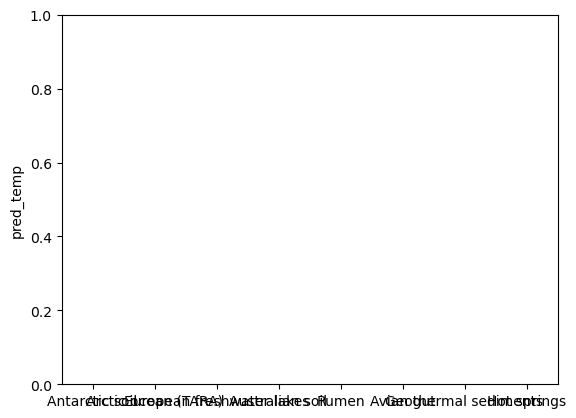

In [191]:
sns.violinplot(data=violin_data,
               y='pred_temp', hue='dataset_label', order=['Antarctic soil', 'Arctic ocean (TARA)', 
                                                          'European freshwater lakes', 'Australian soil', 
                                                          'Rumen', 'Avian gut',  'Geothermal sediments', 'Hot springs'],
              palette=[sns.desaturate(i, 0.75) for i in ['peru', 'cornflowerblue', 'cornflowerblue', 'peru', 'tan', 'tan', 'salmon', 'red']], legend=False)

In [839]:
# figure out where to save
# mg_dataset_preds.to_csv('./../data/predictive_models/supporting_data/m')

# CV plots

In [97]:
errors_df = pd.read_csv('./../data/predictive_models/supporting_data/taxonomic_cv_results.tsv', sep='\t', index_col=0)
errors_df.head()

,level,taxon,error,model
0,phylum,Desulfobacterota,1.256143,ElasticNet
1,phylum,Desulfobacterota,2.211185,SVR
2,phylum,Desulfobacterota,1.342442,RF
3,phylum,Desulfobacterota,2.188698,LM
4,phylum,Desulfobacterota,1.172930,GPR


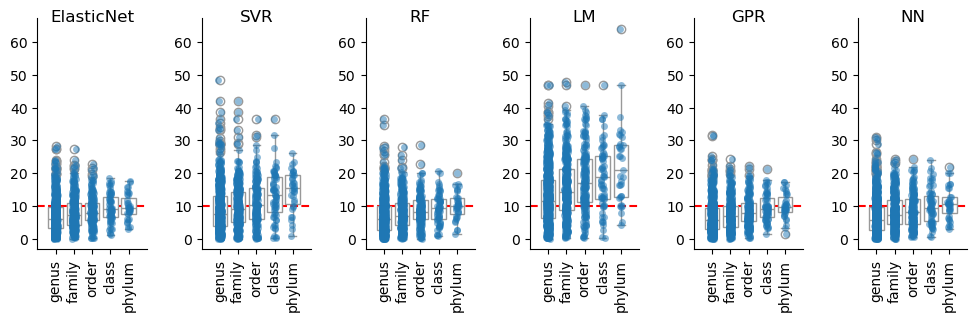

In [136]:
# plot of accuracies

fig = plt.figure(figsize=(12, 3))


axes = []
for i, model in enumerate(errors_df['model'].unique()):
   
    if i == 0:
        ax = fig.add_subplot(1,6,i+1)
        axes.append(ax)
    else:
        ax = fig.add_subplot(1,6,i+1, sharey=axes[0])
        axes.append(ax)

    ax.axhline(10, color='r', linestyle='--', zorder=0)
    
    plot_subset = errors_df[errors_df['model'].eq(model)]
    sns.boxplot(data=plot_subset,
              x='level',
              y=plot_subset['error'] * scaler.scale_,
              order=levels[1:-1][::-1],
              color='white', zorder=1)

    sns.stripplot(data=plot_subset,
          x='level',
          y=plot_subset['error'] * scaler.scale_,
          order=levels[1:-1][::-1],
          zorder=2, alpha=0.5)
    ax.set_xlim(-1, 5)
    ax.set_xlabel('')
    ax.set_ylabel('')
    sns.despine()
    ax.set_title(model, y=0.95)
    plt.tick_params(rotation=90, axis='x')

fig.subplots_adjust(wspace=0.5)
plt.savefig('./../data/figures/ESMmodels_CV_errors.svg', bbox_inches='tight')
plt.savefig('./../data/figures/ESMmodels_CV_errors.png', dpi=400, bbox_inches='tight')

In [134]:
ax.get_xlim()

(-0.5, 4.5)

In [99]:
even_msa_dataset = reload_model('./../data/predictive_models/supporting_data/even_msa_dataset.pickle')

In [100]:
# get GTDB accessions for our dataset
msa_keys = dict((i[0].split('|')[1], i[0]) for i in even_msa_dataset)

In [110]:
# make mapping of genome to taxonomy
even_genome2tax = gtdb_md.loc[msa_keys.keys(), 'gtdb_taxonomy']
# make sure all records are found
print(len(msa_keys), len(even_genome2tax))

# split levels into cols
levels = ['domain', 'phylum', 'class', 'order', 'family', 'genus', 'species']
even_genome2tax = even_genome2tax.apply(lambda x: pd.Series(index=levels, data=[i.split('__')[-1] for i in x.split(';')]))
# map index to sequences
# genome2tax = genome2tax.rename(index=msa_keys)

even_genome2tax.head()

1227 1227


,domain,phylum,class,order,family,genus,species
accession,,,,,,,
GB_GCA_001184205.1,Bacteria,Desulfobacterota,Desulfarculia,Desulfarculales,Desulfarculaceae,Desulfocarbo,Desulfocarbo indianensis
GB_GCA_002368155.1,Bacteria,Cyanobacteriota,Cyanobacteriia,Cyanobacteriales,Nostocaceae,Aulosira,Aulosira carnea
GB_GCA_009768935.1,Bacteria,Spirochaetota,Spirochaetia,Treponematales,Rectinemataceae,Rectinema,Rectinema subterraneum
GB_GCA_009856365.1,Bacteria,Pseudomonadota,Gammaproteobacteria,Pseudomonadales,Oleiphilaceae,Halospina,Halospina utahensis_B
GB_GCA_017161305.1,Bacteria,Spirochaetota,Spirochaetia,Treponematales,Treponemataceae,Treponema_D,Treponema_D ruminis


In [111]:
even_actual = pd.Series(index=[i[0].split('|')[1] for i in even_msa_dataset],
                  data=[unscale_ogts([i[2]], scaler)[0] for i in even_msa_dataset])
even_actual

GB_GCA_001184205.1    30.073430
GB_GCA_002368155.1    20.040163
GB_GCA_009768935.1    40.106697
GB_GCA_009856365.1    27.063450
GB_GCA_017161305.1    37.096717
                        ...    
RS_GCF_902804485.1    21.043489
RS_GCF_902859855.1    26.060123
RS_GCF_904846075.1    15.023529
RS_GCF_904846715.1    22.046816
RS_GCF_905397435.1    27.063450
Length: 1227, dtype: float64

In [112]:
# tome version
tome_cv_files = glob.glob('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/validation_datasets/tomes/tome_retraining/*_predictions.tsv')

In [113]:
tome_cv_files[:5]

['/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/validation_datasets/tomes/tome_retraining/Desulfobacterota_Tome_predictions.tsv',
 '/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/validation_datasets/tomes/tome_retraining/Cyanobacteriota_Tome_predictions.tsv',
 '/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/validation_datasets/tomes/tome_retraining/Spirochaetota_Tome_predictions.tsv',
 '/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/validation_datasets/tomes/tome_retraining/Pseudomonadota_Tome_predictions.tsv',
 '/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/validation_datasets/tomes/tome_retraining/Bacteroidota_Tome_predictions.tsv']

In [332]:
tome_cv_results = []
for f in tqdm(tome_cv_files):
    try:
        tome_cv_df = pd.read_csv(f, sep='\t')
    except pd.errors.EmptyDataError:
        print('No data')
        continue
    tome_cv_df['FileName'] = tome_cv_df['FileName'].apply(lambda x: x.replace('_protein.fasta', ''))
    tome_cv_df = tome_cv_df.set_index('FileName')

    taxname = f.split('/')[-1].split('_Tome')[0]
    whichlevel = [col for col in even_genome2tax.columns if taxname in even_genome2tax[col].unique()]
    # assert len(whichlevel) == 1, 'multiple levels matched'
    level = whichlevel[0]
    test_obs = even_genome2tax[even_genome2tax[level].eq(taxname)]
    
    tax_rmse = np.sqrt(mean_squared_error( even_actual.loc[test_obs.index], tome_cv_df.loc[test_obs.index, 'predOGT (C)']))
    
    tome_cv_results.append(pd.Series(index=['level', 'name', 'error'],
             data=[level, taxname, tax_rmse]))

100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 1411/1411 [00:25<00:00, 54.50it/s]


In [333]:
tome_cv_results = pd.concat(tome_cv_results, axis=1).T

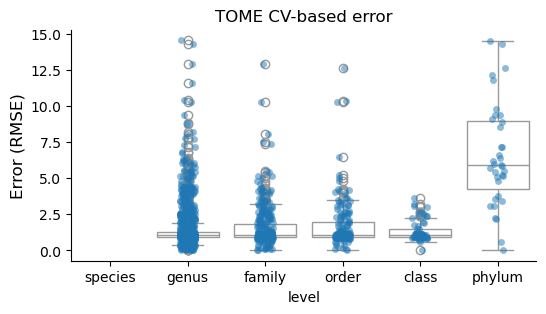

In [334]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.boxplot(data=tome_cv_results,
          x='level',
          y='error',
          order=levels[1:][::-1],
          color='white', zorder=1)

sns.stripplot(data=tome_cv_results,
      x='level',
      y='error',
      order=levels[1:][::-1],
      zorder=2, alpha=0.5)
sns.despine()
ax.set_title('TOME CV-based error')
ax.set_ylabel('Error (RMSE)', fontsize=12)

plt.savefig('./../data/figures/TOME_CV_error.svg', bbox_inches='tight', dpi=400)
plt.savefig('./../data/figures/TOME_CV_error.png', bbox_inches='tight')

In [335]:
full_cv_plotdf = pd.concat([errors_df,
                            tome_cv_results.assign(model='TOME').rename(columns={'name':'taxon'}),])

In [336]:
full_cv_plotdf['level'].unique()

array(['phylum', 'class', 'order', 'family', 'genus'], dtype=object)

In [337]:
tome_cv_results

,level,name,error
0,phylum,Desulfobacterota,9.383416
1,phylum,Cyanobacteriota,14.562418
2,phylum,Spirochaetota,7.204842
3,phylum,Pseudomonadota,6.226216
4,phylum,Bacteroidota,12.155762
...,...,...,...
1406,genus,Haemophilus,1.096717
1407,genus,Legionella,0.93655
1408,genus,Glaesserella,1.096717
1409,genus,Mesonia,1.23653


In [339]:
scaler = reload_model('./../data/predictive_models/supporting_data/ogt_scaler.pickle')
scaler

StandardScaler()

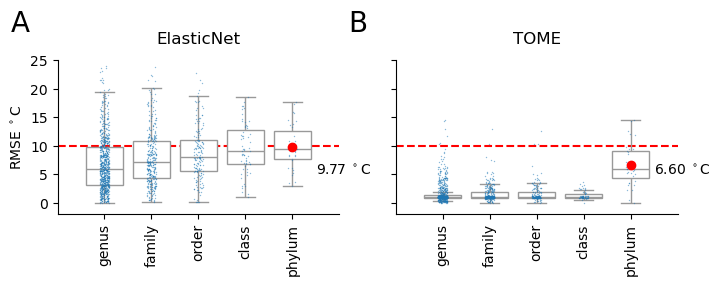

In [344]:
# plot of accuracies

fig = plt.figure(figsize=(8, 2))
# gs = fig.add_gridspec(2,4)

axes = []
model_list = [ 'ElasticNet', 'TOME']#full_cv_plotdf['model'].unique()
n_models = len(model_list)
axis_labels = ['A', 'B']
for i, model in enumerate(model_list): #enumerate(full_cv_plotdf['model'].unique()):
   
    if i == 0:
        ax = fig.add_subplot(1,n_models,i+1)
        axes.append(ax)
    else:
        ax = fig.add_subplot(1,n_models,i+1, sharey=axes[0])
        axes.append(ax)

    ax.axhline(10, color='r', linestyle='--', zorder=0)
    
    plot_subset = full_cv_plotdf[full_cv_plotdf['model'].eq(model)]
    if model != 'TOME':
        scale_mult = scaler.scale_
    else:
        scale_mult = 1
    sns.boxplot(data=plot_subset,
              x='level',
              y=plot_subset['error'] * scale_mult,
              order=levels[1:-1][::-1],
              color='white', zorder=1,
              showfliers=False)

    sns.stripplot(data=plot_subset,
          x='level',
          y=plot_subset['error'] * scale_mult,
          order=levels[1:-1][::-1],
          zorder=2, alpha=0.5, s=1)

   
    phylum_mean = np.mean(plot_subset[plot_subset['level'].eq('phylum')]['error'] * scale_mult)
    ax.scatter([4], [phylum_mean], zorder=3, color='r')
    ax.annotate(f'{phylum_mean:.2f} $^\circ$C', (4.5, 5), xycoords='data')
    
    ax.set_xlim(-1, 5)
    ax.set_ylim(-2, 25)
    ax.set_yticks(list(range(0, 30, 5)))
    ax.annotate(axis_labels[i], xy=(-2, 30), annotation_clip=False, xycoords='data', fontsize=20)

    ax.set_xlabel('')
    if i == 0:
        ax.set_ylabel('RMSE $^\circ$C')
        ax.tick_params(labelleft=True)
    else:
        ax.set_ylabel('')
        ax.tick_params(labelleft=False)
        
    sns.despine()
    ax.set_title(model, y=1.05)
    plt.tick_params(rotation=90, axis='x')

# fig.subplots_adjust(wspace=0.25)
plt.savefig('./../data/figures/ENET_TOME_CV_errors.svg', bbox_inches='tight')
plt.savefig('./../data/figures/ENET_TOME_CV_errors.png', dpi=400, bbox_inches='tight')

In [263]:
plot_subset

,level,taxon,error,model
0,phylum,Desulfobacterota,1.256143,ElasticNet
6,phylum,Cyanobacteriota,1.347782,ElasticNet
12,phylum,Spirochaetota,1.09388,ElasticNet
18,phylum,Pseudomonadota,1.220449,ElasticNet
24,phylum,Bacteroidota,1.087022,ElasticNet
...,...,...,...,...
8484,genus,Haemophilus,1.396148,ElasticNet
8490,genus,Legionella,0.77296,ElasticNet
8496,genus,Glaesserella,1.67846,ElasticNet
8502,genus,Mesonia,0.294867,ElasticNet


In [346]:
structural_data

,Unnamed: 0,Position,Contacts at 4.5 Å,SASA,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,bbsc_internal_hbonds,...,temp,mean_temp,seq_length,bitscore,C,L,N,P,max_structure_length,lid_bitscore
uid,,,,,,,,,,,,,,,,,,,,,
GB_GCA_000376885.1,0,94.0,11.358289,52.616491,-454.076,1.278,10.765,2.648,124.0,21.0,...,37.0,37.00,187,178.2,90.0,48.0,42.0,6.0,24,0.0
GB_GCA_000016765.1,1,108.0,11.125581,49.464040,-450.126,1.316,10.730,2.697,132.0,30.0,...,30.0,30.00,215,175.3,116.0,49.0,43.0,6.0,23,52.3
GB_GCA_000242235.1,2,119.5,11.289720,49.538232,-419.604,1.327,10.981,2.842,128.0,22.0,...,37.0,37.00,214,192.2,117.0,48.0,42.0,6.0,24,59.2
GB_GCA_000283575.1,3,105.5,11.276190,50.018080,-452.738,1.390,10.905,2.771,129.0,20.0,...,30.0,30.00,210,168.7,112.0,48.0,43.0,6.0,24,58.3
GB_GCA_001054945.1,4,91.0,11.359116,51.483049,-431.800,1.243,10.768,2.669,117.0,20.0,...,37.0,37.00,181,192.9,88.0,44.0,42.0,6.0,21,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RS_GCF_905397275.1,9336,111.0,11.257919,49.134618,-492.694,1.353,10.846,2.780,130.0,29.0,...,30.0,28.75,221,195.8,123.0,48.0,43.0,6.0,28,61.7
RS_GCF_907163105.1,9337,99.0,11.502591,51.214600,-494.248,1.290,11.031,2.738,128.0,25.0,...,30.0,33.50,193,165.6,122.0,22.0,42.0,6.0,24,0.0
RS_GCF_905397435.1,9338,111.0,11.366516,49.484025,-469.955,1.362,10.810,2.811,133.0,30.0,...,27.0,26.40,221,194.9,123.0,48.0,43.0,6.0,28,61.6


In [351]:
(genome2tax.loc[structural_data.index, 'phylum'].value_counts() / len(structural_data.index)).head().sum()

0.8985119366234878

In [352]:
(genome2tax.loc[structural_data.index, 'phylum'].value_counts() / len(structural_data.index)).head()

phylum
Pseudomonadota    0.368376
Actinomycetota    0.233594
Bacteroidota      0.129108
Bacillota         0.125575
Bacillota_A       0.041858
Name: count, dtype: float64

In [149]:
tome_cv_results.sort_values('error', ascending=False).head()

,level,name,error
817,genus,Cytobacillus,14.586471
1,phylum,Cyanobacteriota,14.562418
29,phylum,Armatimonadota,14.354863
768,genus,Paenibacillus_I,14.339837
740,genus,Alteribacter,12.969837


In [152]:
(scaler.transform([[10]]) - scaler.transform([[5]])) * scaler.scale_

array([[5.]])

# Extra model validation plots

In [396]:
lls = pd.read_csv('./../data/predictive_models/supporting_data/even_lls.tsv', sep='\t', index_col=0)['0']
lls.head(2)

LBMP01000009.1_70|GB_GCA_001184205.1|adk|temp=30.0|bitscore=199.8   -61.035912
AP018180.1_3248|GB_GCA_002368155.1|adk|temp=20.0|bitscore=179.1     -77.817551
Name: 0, dtype: float64

In [398]:
onehot = pd.read_csv('./../data/predictive_models/supporting_data/onehot_site_sprs.tsv', sep='\t', index_col=0, )['0']
onehot.head(2)

0    0.070138
1    0.076786
Name: 0, dtype: float64

In [ ]:
onehot = pd.read_csv('./../data/predictive_models/supporting_data/onehot_site_sprs.tsv', sep='\t', index_col=0, )['0']
onehot.head(2)

In [ ]:
# placeholder
layer1 = pd.Series(index=range(len(onehot)), data=[0]*len(onehot))
layer6 = pd.read_csv('./../data/predictive_models/supporting_data/')

In [399]:
label = 'even_enetcv_ind_layer6'


done.


In [444]:
df_list = []

for label in ['even_enetcv_ind_layer1', 'even_enetcv_ind_layer6', 'even_enetcv_ind']:
    with open(f'./../data/predictive_models/{label}.pickle', 'rb') as handle:
        enet_results = pickle.load(handle)
    print('done.')
    for col in range(enet_results['full_predictions'].shape[0]):
        _, (r2, rmse, spr) = assess_model(unscale_ogts(enet_results['full_predictions'][col, :], scaler), 
                                      unscale_ogts(enet_results['true_values'], scaler))
        
        df_list.append(pd.Series(data=[label, col, r2, rmse, spr], 
              index=['label', 'col', 'r2', 'rmse', 'spr']))

done.
done.
done.


In [482]:
label_map = {'even_enetcv_ind_layer1':'ESM-1b layer 1',
 'even_enetcv_ind_layer6':'ESM-1b layer 6',
 'even_enetcv_ind':'ROSEATE (layer 12)',
 'onehot':'One-hot (sequence)'}

In [483]:
labels[::-1]

['even_enetcv_ind',
 'even_enetcv_ind',
 'even_enetcv_ind_layer6',
 'even_enetcv_ind_layer1']

<module 'matplotlib.pyplot' from '/data/mhoffert/miniforge3/envs/adenylate_kinase_ogt/lib/python3.10/site-packages/matplotlib/pyplot.py'>

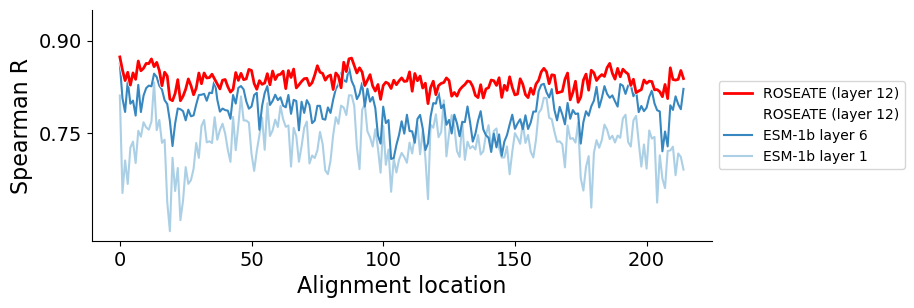

In [484]:
fig, ax = plt.subplots(figsize=(8,3))

sns.lineplot(data=pd.concat(df_list, axis=1).T,
             x='col', y='spr', hue='label',
            hue_order=['even_enetcv_ind_layer1', 'even_enetcv_ind_layer6' ],
            palette='Blues'
)


sns.lineplot(data=pd.concat(df_list, axis=1).T,
             x='col', y='spr', hue='label',
            hue_order=['even_enetcv_ind', ],
            palette=['white'], linewidth=3,
)

sns.lineplot(data=pd.concat(df_list, axis=1).T,
             x='col', y='spr', hue='label',
            hue_order=['even_enetcv_ind', ],
            palette=['r'], linewidth=2,
)

sns.despine()
handles, labels = ax.get_legend_handles_labels()

lgd = ax.legend(handles[::-1], [label_map[l] for l in labels][::-1], loc='center left', bbox_to_anchor=(1, 0.5))

ax.set_ylim(0.575, 0.95)
yticks = ax.set_yticks([0.75, 0.9])
ax.set_ylabel('Spearman R', fontsize=16)
ax.set_xlabel('Alignment location', fontsize=16)
plt.tick_params(labelsize=14)
plt.savefig('./../data/figures/model_layers.svg', bbox_inches='tight')

# sns.lineplot(x=onehot.index, y=onehot.values, 
#              color='gray', label='onehot')

plt

In [423]:
scaler = reload_model('./../data/predictive_models/supporting_data/ogt_scaler.pickle')
scaler

StandardScaler()

$R^{2}$=0.15|RMSE=11.36|SpR=0.82


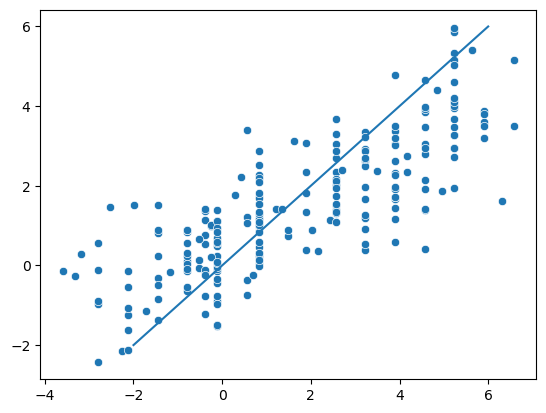

In [415]:
sns.scatterplot(y=enet_results['full_predictions'][col, :], 
            x=enet_results['true_values'])
plt.plot((-2, 6), (-2, 6))

In [405]:
enet_results['true_values']

array([ 0.82078436,  2.15898392, -1.4541549 , -2.79235447,  3.22954357,
        5.23684292, -0.78505512,  3.22954357,  2.42662383,  4.56774314,
        2.56044379,  3.89864335,  5.23684292,  4.96920301,  1.48988414,
       -0.38359525,  5.9059427 ,  4.56774314,  3.89864335,  5.23684292,
        4.83538305,  2.56044379,  2.56044379,  0.82078436, -0.11595534,
        4.56774314, -3.19381433,  0.55314444,  1.48988414,  2.56044379,
        5.9059427 ,  5.9059427 ,  0.82078436, -0.78505512,  5.23684292,
        5.23684292,  1.89134401, -0.11595534,  3.22954357, -0.11595534,
        2.56044379,  2.56044379,  5.23684292,  2.02516397, -0.11595534,
        2.56044379, -0.11595534,  4.56774314, -0.11595534, -0.78505512,
        3.89864335, -0.78505512,  0.82078436,  4.56774314,  3.22954357,
        4.56774314,  3.22954357, -1.18651499,  0.82078436,  3.89864335,
        0.82078436, -0.51741521,  0.82078436, -0.78505512, -2.79235447,
        0.41932449,  0.82078436, -2.12325468, -0.38359525,  1.62